# Digital Image Processing Fundamentals  
## Imaging Physics, Sensor Models, Sampling, Resolution, and CCD/CMOS Analysis

This notebook is a compact image-processing project that connects the **physics of electromagnetic radiation** with the **numerical representation and acquisition of digital images**. Rather than treating the topics as isolated exercises, the project follows a progression from wavelength and photon energy to luminance, sensor acquisition, spatial sampling, quantization, resolution, volumetric data, and simplified CCD/CMOS system modeling.

### Project Goals
- Relate wavelength, frequency, and photon energy across the electromagnetic spectrum.
- Model visible-light classification, luminance, and grayscale intensity behavior.
- Reconstruct images from single-element, line-sensor, 2D-array, and multi-slice sensor data.
- Analyze spatial sampling, intensity quantization, DPI, and line-pair resolution.
- Compare simplified CCD/CMOS power, noise, SNR, and ROI-processing behavior.
- Present every analysis with reproducible Python, numerical results, and visual interpretation.

### Technology Stack
`Python` · `NumPy` · `Pandas` · `Matplotlib` · `Pillow`

### Reproducibility
All sections are designed to run sequentially in Jupyter Notebook or Google Colab. Keep the supplied CSV, PNG, and NPY resource files in the `data/` folder beside this notebook, then use **Run All** to regenerate tables, figures, and numerical results.

> **Note:** The sensor and power models in this project are intentionally simplified demonstrations. They illustrate digital-image-processing concepts and should not be interpreted as universal specifications for real imaging hardware.


## Data Assets

The notebook expects the following project resources in the `data/` directory:

- `em_wavelengths.csv`
- `chromatic_test.png`
- `chromatic_pixel_values.csv`
- `radiance_luminance.csv`
- `grayscale_test.png`
- `grayscale_values_16x16.csv`
- `radar_velocity_20x20.csv`
- `single_sensor_stream.csv`
- `sensor_strip_lines_12x20.csv`
- `sensor_array_20x20.csv`
- `sensor_volume_slice_01.csv` through `sensor_volume_slice_08.csv`
- `sensor_volume_8x20x20.npy`
- `sampling_quantization_source.png`
- `ccd_cmos_lowlight_scene.png`
- `ccd_cmos_parameters.csv`

## Analysis Roadmap

### Imaging Physics and Perception
1. Electromagnetic wavelength and frequency
2. Photon energy
3. Visible-spectrum classification
4. RGB luminance and grayscale conversion
5. Radiant flux, luminous flux, and perceived brightness

### Sensor Acquisition and Numerical Image Representation
6. Grayscale statistics
7. Signed Doppler data
8. Single-element sensing
9. Line-sensor reconstruction
10. 2D sensor arrays
11. 3D sensor volumes

### Sampling, Quantization, and Resolution
12. Spatial sampling
13. Intensity quantization
14. DPI and storage
15. Line-pair resolution

### Sensor-System Modeling
16. CCD/CMOS power efficiency
17. Low-light noise and ROI readout


## Part I — Imaging Physics and Human Perception

The project begins with the physical quantities that determine how electromagnetic energy is represented and perceived before moving into digital sensor data.


## 1. Electromagnetic Wavelength and Frequency Analysis

### Introduction
Digital imaging begins with electromagnetic radiation. A sensor does not initially “see an image”; it responds to electromagnetic energy arriving at different wavelengths. This section establishes that physical foundation by relating wavelength to frequency across representative regions of the electromagnetic spectrum.

### Method
The dataset `em_wavelengths.csv` provides representative wavelengths in meters. Frequency is calculated using

\[
f=\frac{c}{\lambda}
\]

where \(c=2.998\times10^8\text{ m/s}\), \(f\) is frequency, and \(\lambda\) is wavelength. The analysis also converts wavelengths to nanometers, classifies broad electromagnetic regions, sorts samples from longest to shortest wavelength, and visualizes the inverse relationship on logarithmic axes.

A fixed example wavelength is included in the notebook so the entire project can run non-interactively on GitHub, Colab, or Jupyter.


Original Dataset:
   band_or_color  wavelength_m            note
0          Radio  3.000000e+00  representative
1      Microwave  3.000000e-02  representative
2       Infrared  1.000000e-05  representative
3         Violet  4.300000e-07         visible
4           Blue  4.700000e-07         visible
5          Green  5.300000e-07         visible
6         Yellow  5.800000e-07         visible
7         Orange  6.100000e-07         visible
8            Red  7.000000e-07         visible
9    Ultraviolet  3.000000e-07  representative
10         X-ray  1.000000e-10  representative
11     Gamma ray  1.000000e-12  representative

Additional wavelength example: 1.0 m

Electromagnetic Spectrum Results:
       band  wavelength_m  wavelength_nm  frequency_Hz
      Radio  3.000000e+00   3.000000e+09  9.993333e+07
      Radio  1.000000e+00   1.000000e+09  2.998000e+08
  Microwave  3.000000e-02   3.000000e+07  9.993333e+09
   Infrared  1.000000e-05   1.000000e+04  2.998000e+13
    Visible  7.000000e-

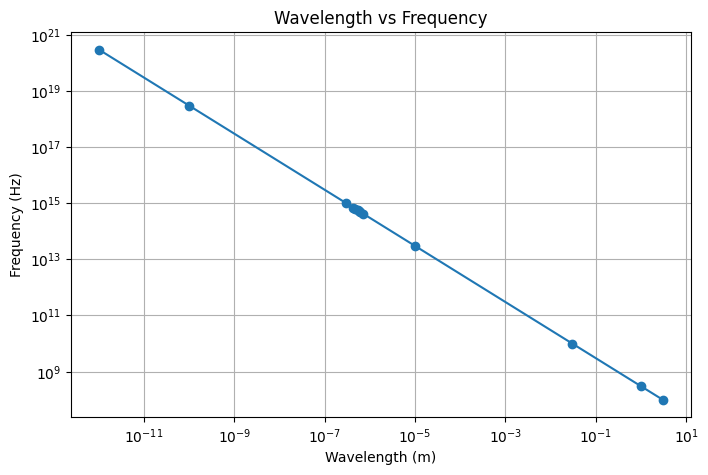

In [1]:
from pathlib import Path

# Launch the notebook from the project folder; retain the supplied data/ directory.
DATA_DIR = Path("data")
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Open this notebook from the project folder containing data/.")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Speed of light
c = 2.998e8  # m/s

# ---------------------------------------------------
# Function to convert wavelength into meters
# ---------------------------------------------------
def convert_to_meters(value, unit):
    unit = unit.lower().strip()

    if unit == "m":
        return value
    elif unit == "cm":
        return value * 1e-2
    elif unit == "mm":
        return value * 1e-3
    elif unit == "um" or unit == "µm":
        return value * 1e-6
    elif unit == "nm":
        return value * 1e-9
    elif unit == "pm":
        return value * 1e-12
    else:
        raise ValueError("Unsupported wavelength unit")


# ---------------------------------------------------
# Broad electromagnetic-band classifier
# ---------------------------------------------------
def classify_em_band(wavelength_m):

    if wavelength_m >= 1:
        return "Radio"

    elif wavelength_m >= 1e-3:
        return "Microwave"

    elif wavelength_m >= 750e-9:
        return "Infrared"

    elif wavelength_m >= 380e-9:
        return "Visible"

    elif wavelength_m >= 10e-9:
        return "Ultraviolet"

    elif wavelength_m >= 1e-11:
        return "X-ray"

    else:
        return "Gamma Ray"


# ---------------------------------------------------
# Load CSV file
# ---------------------------------------------------
df = pd.read_csv((DATA_DIR / "em_wavelengths.csv"))

print("Original Dataset:")
print(df)


# The source dataset already stores wavelength values in meters.


# ---------------------------------------------------
# Calculate frequency
# ---------------------------------------------------
df["frequency_Hz"] = c / df["wavelength_m"]


# ---------------------------------------------------
# Wavelength in nanometers
# ---------------------------------------------------
df["wavelength_nm"] = df["wavelength_m"] * 1e9


# ---------------------------------------------------
# If band is not already present, classify it
# ---------------------------------------------------
if "band" not in df.columns:
    df["band"] = df["wavelength_m"].apply(classify_em_band)


# ---------------------------------------------------
# User-entered wavelength
# ---------------------------------------------------
user_value = 1.0
user_unit = "m"
print(f"\nAdditional wavelength example: {user_value} {user_unit}")

user_m = convert_to_meters(user_value, user_unit)
user_frequency = c / user_m
user_band = classify_em_band(user_m)

new_row = pd.DataFrame({
    "wavelength": [user_value],
    "unit": [user_unit],
    "band": [user_band],
    "wavelength_m": [user_m],
    "frequency_Hz": [user_frequency],
    "wavelength_nm": [user_m * 1e9]
})

df = pd.concat([df, new_row], ignore_index=True)


# ---------------------------------------------------
# Sort longest wavelength to shortest wavelength
# ---------------------------------------------------
df = df.sort_values(
    by="wavelength_m",
    ascending=False
)


# ---------------------------------------------------
# Display results
# ---------------------------------------------------
result = df[
    [
        "band",
        "wavelength_m",
        "wavelength_nm",
        "frequency_Hz"
    ]
]

print("\nElectromagnetic Spectrum Results:")
print(result.to_string(index=False))


# ---------------------------------------------------
# Highest and lowest frequency
# ---------------------------------------------------
highest = df.loc[df["frequency_Hz"].idxmax()]
lowest = df.loc[df["frequency_Hz"].idxmin()]

print("\nHighest Frequency:")
print(highest["band"])
print(f'{highest["frequency_Hz"]:.3e} Hz')

print("\nLowest Frequency:")
print(lowest["band"])
print(f'{lowest["frequency_Hz"]:.3e} Hz')


# ---------------------------------------------------
# Plot wavelength vs frequency
# ---------------------------------------------------
plt.figure(figsize=(8, 5))

plt.loglog(
    df["wavelength_m"],
    df["frequency_Hz"],
    marker="o"
)

plt.title("Wavelength vs Frequency")
plt.xlabel("Wavelength (m)")
plt.ylabel("Frequency (Hz)")

plt.grid(True)

plt.show()


### Interpretation
Frequency increases as wavelength decreases, producing the expected inverse relationship \(f\propto1/\lambda\). The logarithmic plot is especially useful because the electromagnetic spectrum spans many orders of magnitude. This analysis establishes the physical relationship that underpins the later sensor and image-formation sections.


## 2. Photon Energy Across the Electromagnetic Spectrum

### Introduction
Frequency alone does not describe how energetic electromagnetic radiation is. Photon energy is fundamental to understanding why different spectral regions interact with materials and imaging sensors in different ways.

### Method
Using the same wavelength dataset, frequency is first computed from \(f=c/\lambda\). Photon energy is then calculated from

\[
E=hf=\frac{hc}{\lambda}
\]

where \(h=6.62607015\times10^{-34}\text{ J·s}\) is Planck’s constant. Results are expressed in both joules and electron-volts, allowing the energy scale to be compared across radio, microwave, infrared, visible, ultraviolet, X-ray, and gamma-ray regions.

A logarithmic energy-versus-wavelength plot makes the inverse relationship visible over the extremely wide dynamic range of the electromagnetic spectrum.


Original Dataset:
   band_or_color  wavelength_m            note
0          Radio  3.000000e+00  representative
1      Microwave  3.000000e-02  representative
2       Infrared  1.000000e-05  representative
3         Violet  4.300000e-07         visible
4           Blue  4.700000e-07         visible
5          Green  5.300000e-07         visible
6         Yellow  5.800000e-07         visible
7         Orange  6.100000e-07         visible
8            Red  7.000000e-07         visible
9    Ultraviolet  3.000000e-07  representative
10         X-ray  1.000000e-10  representative
11     Gamma ray  1.000000e-12  representative

Photon Energy Comparison:
       band  wavelength_m  frequency_Hz     energy_J    energy_eV
      Radio  3.000000e+00  9.993333e+07 6.621653e-26 4.132911e-07
  Microwave  3.000000e-02  9.993333e+09 6.621653e-24 4.132911e-05
   Infrared  1.000000e-05  2.998000e+13 1.986496e-20 1.239873e-01
    Visible  4.300000e-07  6.972093e+14 4.619758e-19 2.883426e+00
    Visible  4

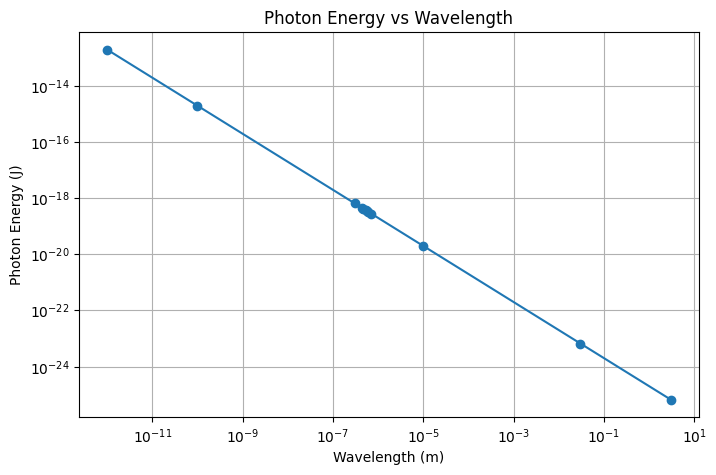

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Constants
c = 2.998e8                 # Speed of light in m/s
h = 6.62607015e-34          # Planck's constant in J.s
eV_conversion = 1.602176634e-19  # 1 eV in joules


# ---------------------------------------------------
# Convert wavelength to meters
# This function is no longer explicitly used
# because the CSV already provides wavelength in meters
# ---------------------------------------------------
def convert_to_meters(value, unit):
    unit = unit.lower().strip()

    if unit == "m":
        return value
    elif unit == "cm":
        return value * 1e-2
    elif unit == "mm":
        return value * 1e-3
    elif unit == "um" or unit == "µm":
        return value * 1e-6
    elif unit == "nm":
        return value * 1e-9
    elif unit == "pm":
        return value * 1e-12
    else:
        raise ValueError("Unsupported wavelength unit")


# ---------------------------------------------------
# Broad electromagnetic-band classifier
# ---------------------------------------------------
def classify_em_band(wavelength_m):

    if wavelength_m >= 1:
        return "Radio"

    elif wavelength_m >= 1e-3:
        return "Microwave"

    elif wavelength_m >= 750e-9:
        return "Infrared"

    elif wavelength_m >= 380e-9:
        return "Visible"

    elif wavelength_m >= 10e-9:
        return "Ultraviolet"

    elif wavelength_m >= 1e-11:
        return "X-ray"

    else:
        return "Gamma Ray"


# ---------------------------------------------------
# Load dataset
# ---------------------------------------------------
df = pd.read_csv((DATA_DIR / "em_wavelengths.csv"))

print("Original Dataset:")
print(df)


# The source dataset already stores wavelength values in meters.


# ---------------------------------------------------
# Calculate frequency
# f = c / lambda
# ---------------------------------------------------
df["frequency_Hz"] = c / df["wavelength_m"]


# ---------------------------------------------------
# Classify the electromagnetic band
# ---------------------------------------------------
df["band"] = df["wavelength_m"].apply(classify_em_band)


# ---------------------------------------------------
# Calculate photon energy in joules
# E = h * f
# ---------------------------------------------------
df["energy_J"] = h * df["frequency_Hz"]


# ---------------------------------------------------
# Convert photon energy to electron-volts
# ---------------------------------------------------
df["energy_eV"] = df["energy_J"] / eV_conversion


# ---------------------------------------------------
# Display comparison table
# ---------------------------------------------------
result = df[
    [
        "band",
        "wavelength_m",
        "frequency_Hz",
        "energy_J",
        "energy_eV"
    ]
]

print("\nPhoton Energy Comparison:")
print(result.to_string(index=False))


# ---------------------------------------------------
# Find highest photon energy
# ---------------------------------------------------
highest_energy = df.loc[df["energy_J"].idxmax()]

print("\nHighest Photon Energy:")
print("Band:", highest_energy["band"])
print(f'Energy: {highest_energy["energy_J"]:.3e} J')
print(f'Energy: {highest_energy["energy_eV"]:.3e} eV')


# ---------------------------------------------------
# Find lowest photon energy
# ---------------------------------------------------
lowest_energy = df.loc[df["energy_J"].idxmin()]

print("\nLowest Photon Energy:")
print("Band:", lowest_energy["band"])
print(f'Energy: {lowest_energy["energy_J"]:.3e} J')
print(f'Energy: {lowest_energy["energy_eV"]:.3e} eV')


# ---------------------------------------------------
# Plot photon energy vs wavelength
# ---------------------------------------------------
plt.figure(figsize=(8, 5))

plt.loglog(
    df["wavelength_m"],
    df["energy_J"],
    marker="o"
)

plt.title("Photon Energy vs Wavelength")
plt.xlabel("Wavelength (m)")
plt.ylabel("Photon Energy (J)")

plt.grid(True)

plt.show()


### Interpretation
Photon energy rises sharply as wavelength becomes shorter. Radio and microwave photons occupy the low-energy end of the modeled spectrum, while X-ray and gamma-ray photons occupy the high-energy end. The calculation shows that wavelength, frequency, and photon energy are mathematically linked rather than independent properties.


## 3. Visible-Spectrum Color Classification

### Introduction
The visible portion of the electromagnetic spectrum occupies only a narrow wavelength interval, yet small wavelength changes within that interval correspond to distinct perceived colors. This section implements a simple wavelength-to-color classifier.

### Method
Visible wavelengths are divided into conventional bands from approximately 380 nm to 750 nm: violet, blue, green, yellow, orange, and red. A classification function maps any supplied wavelength to one of these bands or marks it as outside the visible range.

Representative wavelengths are evaluated, and the complete visible interval is sampled every 5 nm. The distribution of samples across color classes is counted and plotted, providing a compact view of how the chosen numerical boundaries partition the spectrum.

This is a simplified numerical classification model; real human color perception depends on overlapping cone responses rather than perfectly discrete wavelength boundaries.


530.0 nm -> Green

Reference Wavelength Results:
430 nm -> Violet
470 nm -> Blue
530 nm -> Green
580 nm -> Yellow
610 nm -> Orange
700 nm -> Red

Number of samples in each color class:
Violet : 14
Blue : 9
Green : 15
Yellow : 4
Orange : 6
Red : 27


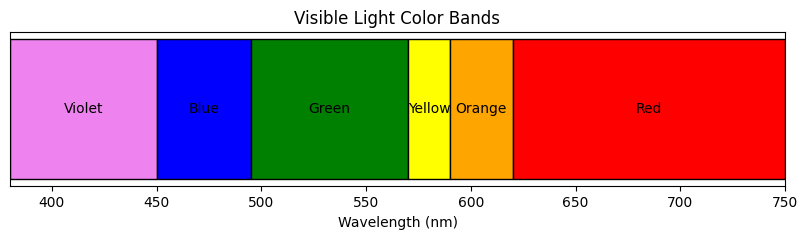

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter


# ---------------------------------------------------
# Function to classify visible wavelength
# ---------------------------------------------------
def classify_visible_color(wavelength_nm):

    if 380 <= wavelength_nm < 450:
        return "Violet"

    elif 450 <= wavelength_nm < 495:
        return "Blue"

    elif 495 <= wavelength_nm < 570:
        return "Green"

    elif 570 <= wavelength_nm < 590:
        return "Yellow"

    elif 590 <= wavelength_nm < 620:
        return "Orange"

    elif 620 <= wavelength_nm <= 750:
        return "Red"

    else:
        return "Outside visible range"


# ---------------------------------------------------
# Reproducible example wavelength
# ---------------------------------------------------
user_wavelength = 530.0

user_color = classify_visible_color(user_wavelength)

print(
    f"{user_wavelength} nm -> {user_color}"
)


# ---------------------------------------------------
# Reference wavelengths
# ---------------------------------------------------
test_wavelengths = [
    430,
    470,
    530,
    580,
    610,
    700
]

print("\nReference Wavelength Results:")

for wavelength in test_wavelengths:

    color = classify_visible_color(wavelength)

    print(
        f"{wavelength} nm -> {color}"
    )


# ---------------------------------------------------
# Generate wavelengths from 380 to 750 nm
# in steps of 5 nm
# ---------------------------------------------------
wavelengths = np.arange(
    380,
    751,
    5
)


# Classify every wavelength
color_classes = [
    classify_visible_color(w)
    for w in wavelengths
]


# ---------------------------------------------------
# Count samples in every color class
# ---------------------------------------------------
counts = Counter(color_classes)

print("\nNumber of samples in each color class:")

colors = [
    "Violet",
    "Blue",
    "Green",
    "Yellow",
    "Orange",
    "Red"
]

for color in colors:

    print(
        color,
        ":",
        counts[color]
    )


# ---------------------------------------------------
# Horizontal color-band plot
# ---------------------------------------------------
ranges = [
    (380, 450, "Violet"),
    (450, 495, "Blue"),
    (495, 570, "Green"),
    (570, 590, "Yellow"),
    (590, 620, "Orange"),
    (620, 750, "Red")
]

plot_colors = [
    "violet",
    "blue",
    "green",
    "yellow",
    "orange",
    "red"
]


plt.figure(figsize=(10, 2))

for (start, end, label), display_color in zip(
    ranges,
    plot_colors
):

    plt.barh(
        y=0,
        width=end - start,
        left=start,
        color=display_color,
        edgecolor="black"
    )

    plt.text(
        (start + end) / 2,
        0,
        label,
        ha="center",
        va="center"
    )


plt.xlim(380, 750)

plt.xlabel("Wavelength (nm)")
plt.title("Visible Light Color Bands")

plt.yticks([])

plt.show()


### Interpretation
The classifier correctly assigns representative visible wavelengths to conventional color regions and shows that those regions have unequal numerical widths. The model is useful for numerical grouping, but its hard boundaries should be understood as an engineering simplification of continuous human color perception.


## 4. RGB Luminance and Grayscale Conversion

### Introduction
Color images store multiple channels, but many image-processing operations work with a single intensity channel. Converting RGB data to grayscale is therefore one of the most common preprocessing operations in computer vision.

### Method
The project loads `chromatic_test.png` together with its pixel-value table and calculates luminance using

\[
Y=0.299R+0.587G+0.114B
\]

The unequal coefficients reflect the fact that perceived brightness is more sensitive to green than to red or blue. The resulting luminance values are rounded and clipped to the valid 8-bit interval \([0,255]\).

The original RGB image and its grayscale representation are displayed side by side, while mean channel values provide a numerical summary of the image’s color composition. This demonstrates that grayscale conversion preserves brightness structure while intentionally discarding hue and saturation.

**Terminology:** The weighted RGB sum is a conventional grayscale/luma approximation. Without linearizing gamma-encoded RGB, it is not a calibrated physical luminance measurement.


Original RGB Pixel Values:
   pixel_id  nominal_wavelength_nm    R    G    B
0        P1                    430   90   20  180
1        P2                    470   20   80  230
2        P3                    530   30  180   70
3        P4                    580  230  210   40
4        P5                    610  250  130   20
5        P6                    700  220   30   30
6        P7                    530   80  220  120
7        P8                    470   60  120  255
8        P9                    610  255  180   80
9       P10                    700  180   15   15
10      P11                    580  180  175   30
11      P12                    430  120   40  220

RGB Values with Computed Grayscale:
   pixel_id  nominal_wavelength_nm    R    G    B        Y  Y_rounded
0        P1                    430   90   20  180   59.170         59
1        P2                    470   20   80  230   79.160         79
2        P3                    530   30  180   70  122.610        123
3     

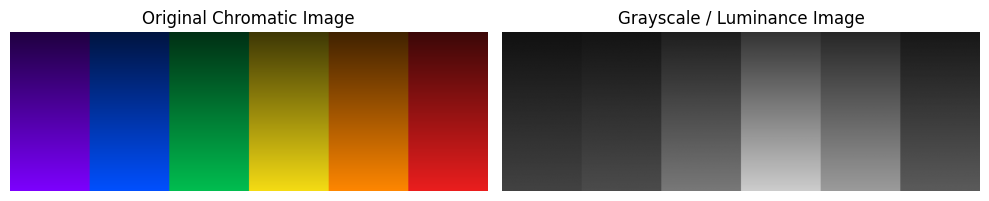

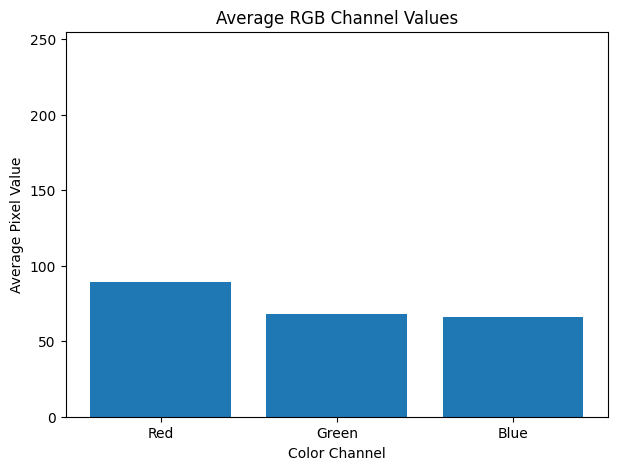

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# ---------------------------------------------------
# PART 1: Load the supplied RGB pixel values
# ---------------------------------------------------

df = pd.read_csv((DATA_DIR / "chromatic_pixel_values.csv"))

print("Original RGB Pixel Values:")
print(df)


# ---------------------------------------------------
# PART 2: Calculate grayscale/luminance Y
# Y = 0.299R + 0.587G + 0.114B
# ---------------------------------------------------

df["Y"] = (
    0.299 * df["R"]
    + 0.587 * df["G"]
    + 0.114 * df["B"]
)


# Round Y to nearest integer and ensure [0, 255]
df["Y_rounded"] = np.clip(
    np.rint(df["Y"]),
    0,
    255
).astype(int)


print("\nRGB Values with Computed Grayscale:")
print(df)


# ---------------------------------------------------
# PART 3: Find highest and lowest Y pixels
# ---------------------------------------------------

highest_pixel = df.loc[df["Y_rounded"].idxmax()]
lowest_pixel = df.loc[df["Y_rounded"].idxmin()]

print("\nPixel with Highest Y:")
print(highest_pixel)

print("\nPixel with Lowest Y:")
print(lowest_pixel)


# ---------------------------------------------------
# PART 4: Load chromatic image
# ---------------------------------------------------

image = Image.open((DATA_DIR / "chromatic_test.png")).convert("RGB")

rgb = np.array(image)

print("\nImage shape:")
print(rgb.shape)


# ---------------------------------------------------
# PART 5: Convert complete image to grayscale
# using the SAME weighted formula
# ---------------------------------------------------

gray = (
    0.299 * rgb[:, :, 0]
    + 0.587 * rgb[:, :, 1]
    + 0.114 * rgb[:, :, 2]
)

gray = np.clip(
    np.rint(gray),
    0,
    255
).astype(np.uint8)


# ---------------------------------------------------
# PART 6: Display color and grayscale side by side
# ---------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(rgb)
axes[0].set_title("Original Chromatic Image")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale / Luminance Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# ---------------------------------------------------
# PART 7: Calculate average R, G and B
# ---------------------------------------------------

mean_R = rgb[:, :, 0].mean()
mean_G = rgb[:, :, 1].mean()
mean_B = rgb[:, :, 2].mean()

print("\nAverage Channel Values:")
print(f"Average R: {mean_R:.2f}")
print(f"Average G: {mean_G:.2f}")
print(f"Average B: {mean_B:.2f}")


# ---------------------------------------------------
# PART 8: Plot average RGB values
# ---------------------------------------------------

channels = ["Red", "Green", "Blue"]
averages = [mean_R, mean_G, mean_B]

plt.figure(figsize=(7, 5))

plt.bar(channels, averages)

plt.title("Average RGB Channel Values")
plt.xlabel("Color Channel")
plt.ylabel("Average Pixel Value")

plt.ylim(0, 255)

plt.show()


### Interpretation
The luminance-weighted grayscale conversion preserves the image’s brightness structure while removing chromatic information. Because green contributes the largest coefficient, equal numerical amounts of red, green, and blue do not produce equal perceived brightness. This is why weighted luminance is more meaningful than a simple arithmetic channel average.


## 5. Radiant Flux, Luminous Flux, and Perceived Brightness

The supplied synthetic file is named `radiance_luminance.csv`, with legacy columns `radiance_W` and `luminance_lm`. Their stated units are watts and lumens, which describe radiant flux and luminous flux, respectively—not radiance or luminance. The source file and column names are preserved for traceability; this section interprets their values according to those units.

The analysis compares flux rankings with supplied subjective brightness ratings, calculates a luminous-to-radiant flux ratio (lm/W), and reports Pearson correlation. These are illustrative teaching values, not calibrated physical measurements or a human-subject study.


Original Dataset:
             source  ...  subjective_brightness_rating_0_to_1
0   A_visible_green  ...                                 0.78
1     B_visible_red  ...                                 0.55
2         C_near_IR  ...                                 0.08
3    D_visible_blue  ...                                 0.43
4  E_visible_yellow  ...                                 0.71

[5 rows x 4 columns]

Column Names:
Index(['source', 'radiance_W', 'luminance_lm',
       'subjective_brightness_rating_0_to_1'],
      dtype='object')

Dataset with Luminous Flux/Radiant Flux Ratio:
             source  ...  luminance_radiance_ratio
0   A_visible_green  ...                350.000000
1     B_visible_red  ...                180.000000
2         C_near_IR  ...                  4.444444
3    D_visible_blue  ...                112.500000
4  E_visible_yellow  ...                344.444444

[5 rows x 5 columns]

Ranking by Radiant Flux:
          source  radiance_W
       C_near_IR        18

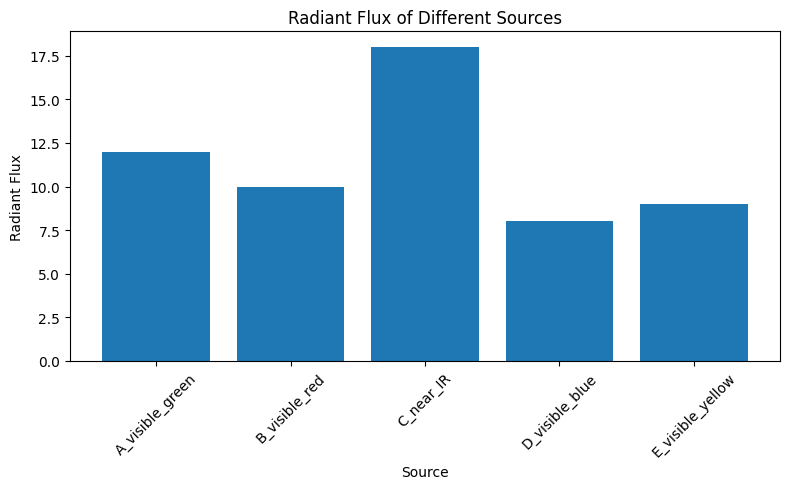

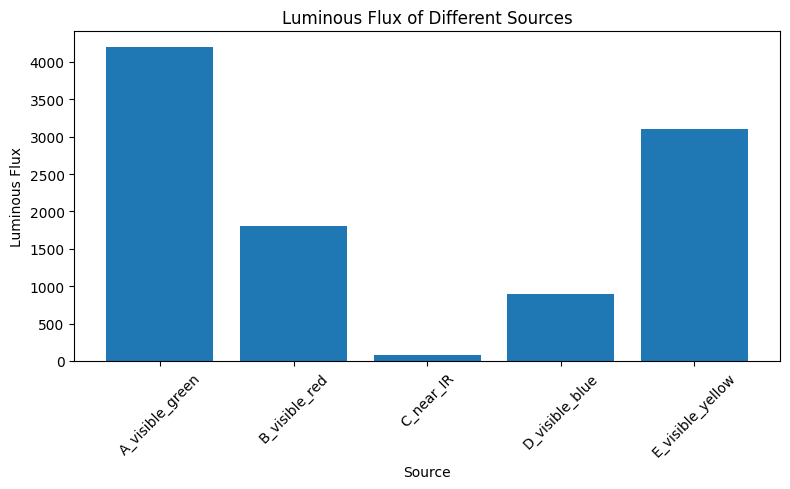

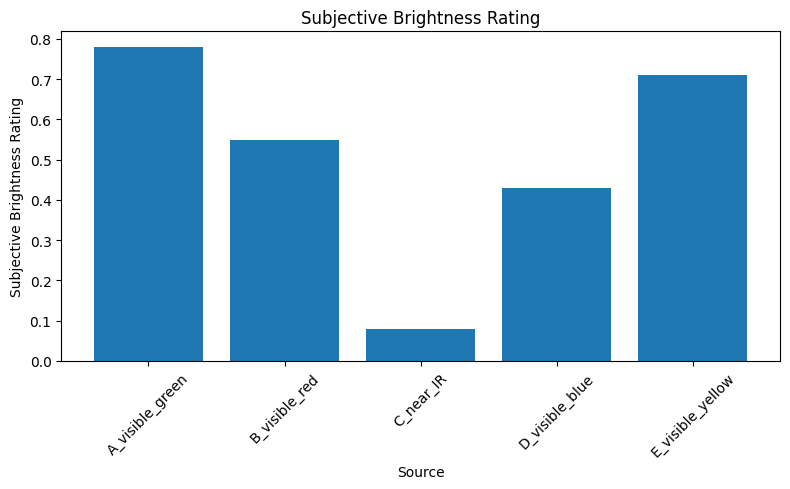

In [5]:
import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------
# PART 1: Load dataset
# ---------------------------------------------------

df = pd.read_csv((DATA_DIR / "radiance_luminance.csv"))

print("Original Dataset:")
print(df)

# Display column names so we can verify them
print("\nColumn Names:")
print(df.columns)


# ---------------------------------------------------
# IMPORTANT:
# The following assumes the CSV columns are named:
#
# source
# radiance_W
# luminance_lm
# subjective_brightness_rating_0_to_1
#
# If your CSV uses slightly different names,
# replace them below with the actual names.
# ---------------------------------------------------


# ---------------------------------------------------
# PART 2: Calculate luminance/radiance ratio
# ---------------------------------------------------

df["luminance_radiance_ratio"] = (
    df["luminance_lm"] / df["radiance_W"]
)

print("\nDataset with Luminous Flux/Radiant Flux Ratio:")
print(df)


# ---------------------------------------------------
# PART 3: Rank sources by radiance
# ---------------------------------------------------

radiance_rank = df.sort_values(
    by="radiance_W",
    ascending=False
)

print("\nRanking by Radiant Flux:")
print(
    radiance_rank[
        ["source", "radiance_W"]
    ].to_string(index=False)
)


# ---------------------------------------------------
# Rank sources by luminance
# ---------------------------------------------------

luminance_rank = df.sort_values(
    by="luminance_lm",
    ascending=False
)

print("\nRanking by Luminous Flux:")
print(
    luminance_rank[
        ["source", "luminance_lm"]
    ].to_string(index=False)
)


# ---------------------------------------------------
# Rank sources by subjective brightness
# ---------------------------------------------------

brightness_rank = df.sort_values(
    by="subjective_brightness_rating_0_to_1",
    ascending=False
)

print("\nRanking by Subjective Brightness:")
print(
    brightness_rank[
        ["source", "subjective_brightness_rating_0_to_1"]
    ].to_string(index=False)
)


# ---------------------------------------------------
# PART 4: Bar chart for radiance
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    df["source"],
    df["radiance_W"]
)

plt.title("Radiant Flux of Different Sources")
plt.xlabel("Source")
plt.ylabel("Radiant Flux")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ---------------------------------------------------
# Bar chart for luminance
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    df["source"],
    df["luminance_lm"]
)

plt.title("Luminous Flux of Different Sources")
plt.xlabel("Source")
plt.ylabel("Luminous Flux")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ---------------------------------------------------
# Bar chart for subjective brightness
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    df["source"],
    df["subjective_brightness_rating_0_to_1"]
)

plt.title("Subjective Brightness Rating")
plt.xlabel("Source")
plt.ylabel("Subjective Brightness Rating")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ---------------------------------------------------
# PART 5: Pearson correlation
# ---------------------------------------------------

correlation = df["luminance_lm"].corr(
    df["subjective_brightness_rating_0_to_1"],
    method="pearson"
)

print(
    "\nPearson Correlation between "
    "Luminous Flux and Subjective Brightness:"
)

print(round(correlation, 4))


# ---------------------------------------------------
# PART 6:
# Identify relatively high-radiance / low-luminance
# sources
#
# Here we define:
# high radiance = above dataset median
# low luminance = below dataset median
# ---------------------------------------------------

radiance_median = df["radiance_W"].median()
luminance_median = df["luminance_lm"].median()

high_rad_low_lum = df[
    (df["radiance_W"] > radiance_median)
    &
    (df["luminance_lm"] < luminance_median)
]

print("\nHigh Radiant Flux but Relatively Low Luminous Flux:")

if high_rad_low_lum.empty:
    print("No source meets the selected median-based criterion.")
else:
    print(
        high_rad_low_lum[
            [
                "source",
                "radiance_W",
                "luminance_lm",
                "luminance_radiance_ratio"
            ]
        ].to_string(index=False)
    )


### Interpretation
The synthetic sources can rank differently by radiant flux, luminous flux, and supplied brightness ratings. The correlation is descriptive for this small teaching dataset; it does not establish a general law of perception.


## Part II — Sensor Acquisition and Numerical Image Representation

These analyses move from pixel statistics into progressively richer sensing architectures: signed measurement fields, serial sensing, line sensing, 2D arrays, and 3D volumes.


## 6. Grayscale Intensity Statistics and Histogram Analysis

### Introduction
A grayscale image can be treated as a two-dimensional numerical signal. Statistical summaries of its pixel intensities provide a quick description of contrast, brightness distribution, and dynamic range.

### Method
The raw 16×16 intensity matrix is loaded with `header=None` so every value is preserved as image data. The analysis calculates minimum, maximum, mean, median, standard deviation, and dynamic range. Pixels are also grouped into dark, mid-tone, and bright intensity ranges.

A 256-bin histogram reveals how frequently each gray level occurs, while the five strongest intensity samples are located using their row and column coordinates. The accompanying image display connects these numerical statistics back to spatial structure.

This section demonstrates how basic descriptive statistics can summarize an image without altering its original pixel values.


Matrix Shape: (16, 16)

Grayscale Matrix:
[[  9  24  40  56  72  88 104 120 136 152 168 184 200 216 232 246]
 [  9  24  40  56  72  88 104 120 136 152 168 184 200 216 232 246]
 [  9  24  41  73  99  98 104 120 136 152 168 184 200 216 232 246]
 [  9  24  82 187 208 186 122 120 136 152 168 184 200 216 232 246]
 [  9  27 154 220 220 219 162 120 136 152 168 184 200 216 232 246]
 [  9  27 157 220 220 220 164 120 136 152 168 184 200 216 232 246]
 [  9  24  87 193 212 191 125 120 136 152 168 184 200 216 232 246]
 [  9  24  41  77 105 102 104 120 136 146 132 124 150 203 232 246]
 [  9  24  40  56  72  88 104 120 130  88  51  45  50  99 213 246]
 [  9  24  40  56  72  88 104 120 105  49  45  45  45  47 146 245]
 [  9  24  40  56  72  88 104 120  89  45  45  45  45  45 111 242]
 [  9  24  40  56  72  88 104 120  97  46  45  45  45  45 129 244]
 [  9  24  40  56  72  88 104 120 124  69  46  45  45  71 194 246]
 [  9  24  40  56  72  88 104 120 136 135 100  85 108 179 231 246]
 [  9  24  40  56  7

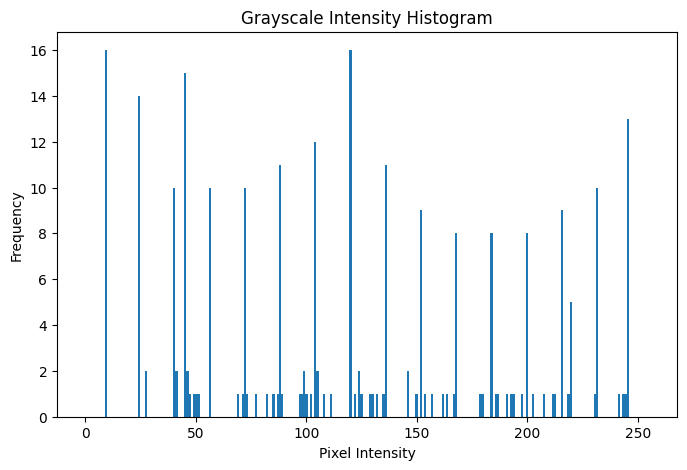

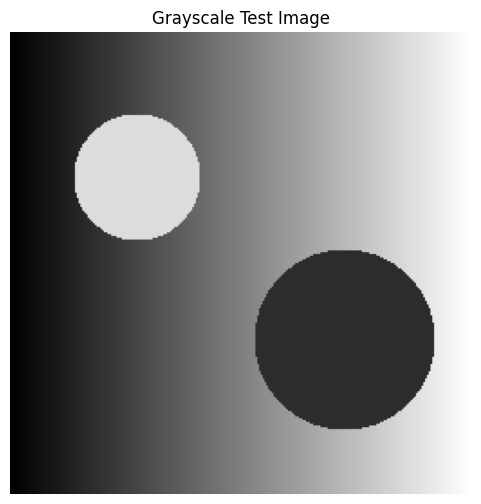

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# ===================================================
# GRAYSCALE INTENSITY STATISTICS AND HISTOGRAM ANALYSIS
# ===================================================


# 1. Load 16x16 grayscale values
# header=None is important because the CSV has no header
df = pd.read_csv(
    (DATA_DIR / "grayscale_values_16x16.csv"),
    header=None
)

gray_values = df.to_numpy()

print("Matrix Shape:", gray_values.shape)
print("\nGrayscale Matrix:")
print(gray_values)


# ---------------------------------------------------
# 2. Calculate statistics
# ---------------------------------------------------

minimum = np.min(gray_values)
maximum = np.max(gray_values)
mean = np.mean(gray_values)
median = np.median(gray_values)
std_dev = np.std(gray_values)

dynamic_range = maximum - minimum

print("\n--- Intensity Statistics ---")

print("Minimum:", minimum)
print("Maximum:", maximum)
print(f"Mean: {mean:.2f}")
print(f"Median: {median:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")
print("Dynamic Range:", dynamic_range)


# ---------------------------------------------------
# 3. 256-bin histogram
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    gray_values.flatten(),
    bins=256,
    range=(0, 255)
)

plt.title("Grayscale Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()


# ---------------------------------------------------
# 4. Dark, mid-tone and bright pixel counts
# ---------------------------------------------------

dark_count = np.sum(
    (gray_values >= 0) &
    (gray_values <= 85)
)

mid_count = np.sum(
    (gray_values >= 86) &
    (gray_values <= 170)
)

bright_count = np.sum(
    (gray_values >= 171) &
    (gray_values <= 255)
)

print("\n--- Pixel Categories ---")

print("Dark [0-85]:", dark_count)
print("Mid-tone [86-170]:", mid_count)
print("Bright [171-255]:", bright_count)

print(
    "Total:",
    dark_count + mid_count + bright_count
)


# ---------------------------------------------------
# 5. Five highest-intensity samples
# ---------------------------------------------------

flat_indices = np.argsort(
    gray_values,
    axis=None
)[::-1]

top_five = flat_indices[:5]

print("\n--- Five Highest-Intensity Samples ---")

for index in top_five:

    row, col = np.unravel_index(
        index,
        gray_values.shape
    )

    value = gray_values[row, col]

    print(
        f"Coordinate ({row}, {col}) "
        f"-> Intensity = {value}"
    )


# ---------------------------------------------------
# 6. Load and display grayscale image
# ---------------------------------------------------

image = Image.open(
    (DATA_DIR / "grayscale_test.png")
).convert("L")

image_array = np.array(image)

print("\nImage Shape:", image_array.shape)

plt.figure(figsize=(6, 6))

plt.imshow(
    image_array,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Grayscale Test Image")

plt.axis("off")

plt.show()


### Interpretation
The histogram and descriptive statistics summarize the image’s tonal distribution, while coordinate-based extrema preserve spatial context. Dynamic range indicates the span of represented intensities, and the dark/mid/bright counts provide a simple description of how that range is populated.


## 7. Signed Doppler Velocity Visualization

### Introduction
Not every digital image is an unsigned brightness map. Scientific and engineering images often contain signed measurements in which the sign itself carries physical meaning. Doppler and radar velocity fields are a common example.

### Method
The 20×20 velocity matrix is loaded as floating-point data while preserving negative, positive, and zero values. Negative values represent one radial-motion direction, positive values represent the opposite direction, and zero represents no measured radial motion under the adopted convention.

The analysis counts pixels in each sign category, calculates mean values for approaching and receding motion, identifies the strongest negative and positive responses, and displays the field with a zero-centered diverging heatmap.

For visualization only, the signed range is also linearly mapped to an 8-bit grayscale image. The original signed matrix remains unchanged, preventing the loss of directional information that would occur if negative values were simply clipped.


===== RADAR DATA INFORMATION =====
Matrix shape: (20, 20)
Data type: float64

Signed Radar Velocity Matrix:
[[  0.    0.    0.    0.    1.6   1.6   0.    0.    0.    0.    0.    0.
    0.    0.   -1.6  -1.6   0.    0.    0.    0. ]
 [  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0. ]
 [  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0. ]
 [  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
    0.    0.    0.    0.    0.    0.    0.    0. ]
 [  0.    0.   -1.7  -2.6  -3.5  -4.   -3.6  -2.7  -1.5   0.    0.    0.
    0.    1.5   1.7   1.7   0.    0.    0.    0. ]
 [  0.   -1.6  -3.4  -5.8  -8.3  -9.6  -8.8  -6.4  -3.6   0.    0.    0.
    2.    2.5   2.7   2.6   2.3   1.7   0.    0. ]
 [  0.   -2.7  -6.1 -11.2 -16.8 -19.9 -18.3 -13.1  -7.2  -2.6   0.    2.
    3.3   4.2   4.4   4.    3.3   2.4   0.    0. ]
 [  0.   -4.1  -9.5 -18.

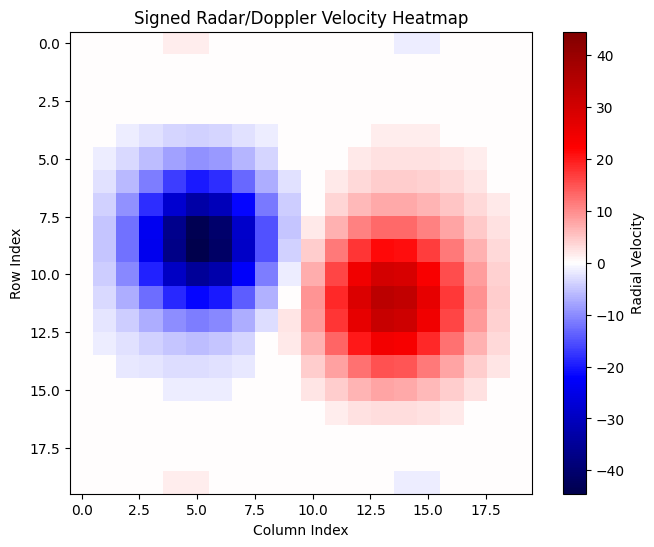

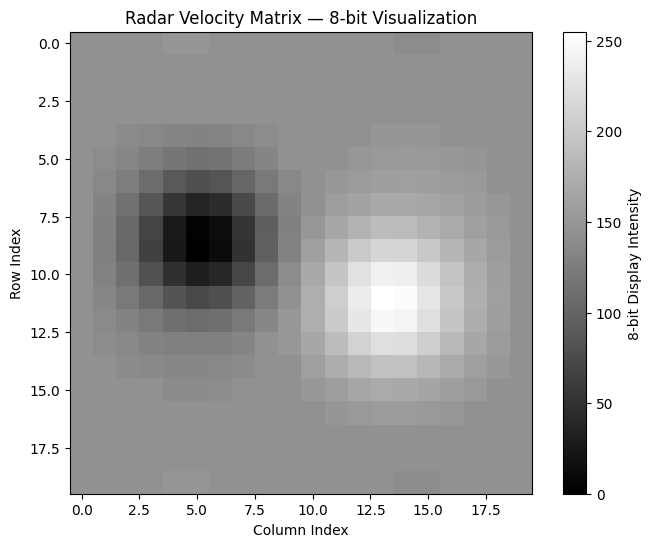

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SIGNED DOPPLER VELOCITY VISUALIZATION
# ============================================================

# Adopted sign convention:
# Negative velocity = approaching
# Positive velocity = receding
# Zero velocity     = stationary / no detected radial motion


# ------------------------------------------------------------
# 1. Load the 20x20 signed radar matrix
# ------------------------------------------------------------

# header=None is required because the CSV contains raw matrix
# values and does NOT contain column headings.
df = pd.read_csv(
    (DATA_DIR / "radar_velocity_20x20.csv"),
    header=None
)

# Convert to floating-point NumPy array
radar = df.to_numpy(dtype=float)

print("===== RADAR DATA INFORMATION =====")
print("Matrix shape:", radar.shape)
print("Data type:", radar.dtype)

print("\nSigned Radar Velocity Matrix:")
print(radar)


# Verify expected shape
if radar.shape == (20, 20):
    print("\nShape verification: Correct (20 x 20)")
else:
    print(
        "\nWARNING: Expected shape (20, 20), "
        f"but received {radar.shape}"
    )


# ------------------------------------------------------------
# 2. Classify negative, positive and zero values
# ------------------------------------------------------------

approaching_mask = radar < 0
receding_mask = radar > 0
stationary_mask = radar == 0

approaching_count = np.sum(approaching_mask)
receding_count = np.sum(receding_mask)
stationary_count = np.sum(stationary_mask)

total_pixels = radar.size

print("\n===== MOTION CLASSIFICATION =====")

print(
    "Approaching pixels (negative):",
    approaching_count
)

print(
    "Receding pixels (positive):",
    receding_count
)

print(
    "Stationary pixels (zero):",
    stationary_count
)

print("Total pixels:", total_pixels)

print(
    "Classification check:",
    approaching_count
    + receding_count
    + stationary_count
)


# ------------------------------------------------------------
# 3. Calculate velocity statistics
# ------------------------------------------------------------

approaching_values = radar[approaching_mask]
receding_values = radar[receding_mask]

if approaching_values.size > 0:
    mean_approaching = np.mean(approaching_values)
else:
    mean_approaching = np.nan

if receding_values.size > 0:
    mean_receding = np.mean(receding_values)
else:
    mean_receding = np.nan

minimum_velocity = np.min(radar)
maximum_velocity = np.max(radar)

print("\n===== VELOCITY STATISTICS =====")

print(
    f"Mean approaching velocity: "
    f"{mean_approaching:.2f}"
)

print(
    f"Mean receding velocity: "
    f"{mean_receding:.2f}"
)

print(
    f"Minimum velocity: "
    f"{minimum_velocity:.2f}"
)

print(
    f"Maximum velocity: "
    f"{maximum_velocity:.2f}"
)


# ------------------------------------------------------------
# 4. Find strongest approaching and receding targets
# ------------------------------------------------------------

# Strongest approaching target = most negative value
strongest_approaching_flat = np.argmin(radar)

strongest_approaching_coord = np.unravel_index(
    strongest_approaching_flat,
    radar.shape
)

strongest_approaching_value = radar[
    strongest_approaching_coord
]


# Strongest receding target = most positive value
strongest_receding_flat = np.argmax(radar)

strongest_receding_coord = np.unravel_index(
    strongest_receding_flat,
    radar.shape
)

strongest_receding_value = radar[
    strongest_receding_coord
]


print("\n===== STRONGEST TARGETS =====")

print(
    "Strongest approaching target:"
)

print(
    f"Coordinate = "
    f"{strongest_approaching_coord}"
)

print(
    f"Velocity = "
    f"{strongest_approaching_value:.2f}"
)


print("\nStrongest receding target:")

print(
    f"Coordinate = "
    f"{strongest_receding_coord}"
)

print(
    f"Velocity = "
    f"{strongest_receding_value:.2f}"
)


# ------------------------------------------------------------
# 5. Display signed radar matrix as heatmap
# ------------------------------------------------------------

# Use a symmetric display range around zero so that zero is
# conceptually at the center of the color scale.

max_absolute_velocity = max(
    abs(minimum_velocity),
    abs(maximum_velocity)
)

plt.figure(figsize=(8, 6))

heatmap = plt.imshow(
    radar,
    cmap="seismic",
    vmin=-max_absolute_velocity,
    vmax=max_absolute_velocity,
    interpolation="nearest"
)

plt.colorbar(
    heatmap,
    label="Radial Velocity"
)

plt.title(
    "Signed Radar/Doppler Velocity Heatmap"
)

plt.xlabel("Column Index")
plt.ylabel("Row Index")

plt.show()


# ------------------------------------------------------------
# 6. Create 8-bit visualization
# ------------------------------------------------------------

# IMPORTANT:
# We normalize a COPY for visualization.
# The original signed 'radar' matrix remains unchanged.

radar_min = np.min(radar)
radar_max = np.max(radar)

if radar_max != radar_min:

    radar_8bit = (
        (radar - radar_min)
        /
        (radar_max - radar_min)
        * 255
    )

else:
    radar_8bit = np.zeros_like(radar)

radar_8bit = np.rint(
    radar_8bit
).astype(np.uint8)


print("\n===== 8-BIT VISUALIZATION =====")

print(
    "Original signed range:",
    radar_min,
    "to",
    radar_max
)

print(
    "Mapped 8-bit range:",
    radar_8bit.min(),
    "to",
    radar_8bit.max()
)

print("\n8-bit Matrix:")
print(radar_8bit)


# ------------------------------------------------------------
# 7. Display normalized 8-bit radar image
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.imshow(
    radar_8bit,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.colorbar(
    label="8-bit Display Intensity"
)

plt.title(
    "Radar Velocity Matrix — 8-bit Visualization"
)

plt.xlabel("Column Index")
plt.ylabel("Row Index")

plt.show()


# ------------------------------------------------------------
# 8. Confirm that original signed data was preserved
# ------------------------------------------------------------

print("\n===== DATA PRESERVATION CHECK =====")

print(
    "Original matrix dtype:",
    radar.dtype
)

print(
    "Original minimum:",
    radar.min()
)

print(
    "Original maximum:",
    radar.max()
)

print(
    "8-bit visualization dtype:",
    radar_8bit.dtype
)

print(
    "8-bit minimum:",
    radar_8bit.min()
)

print(
    "8-bit maximum:",
    radar_8bit.max()
)


### Interpretation
Signed scientific images must preserve their original numerical sign during analysis. A zero-centered color scale makes direction immediately visible, while the separate 8-bit mapping is appropriate only for display. Keeping the signed source array intact avoids destroying physically meaningful motion information.


## 8. Single-Element Sensor Image Reconstruction

### Introduction
An image can be acquired with only one sensing element if that sensor is moved systematically across a scene. Although slower than array-based capture, this model clearly demonstrates how a serial stream of measurements becomes a two-dimensional image.

### Method
`single_sensor_stream.csv` contains sample indices, row and column coordinates, analog voltage values, and digitized intensities. The image is reconstructed by assigning each intensity to its corresponding spatial coordinate.

The reconstructed 10×10 image is visualized, its strongest sample is located, and scan-order behavior is explored in two ways. Reversing a raw serial stream changes the reconstructed image when position is inferred only from order. In contrast, reversing coordinate-tagged records does not change the reconstruction because every sample still carries its explicit row and column.

This distinction illustrates why spatial metadata is critical in sequential sensing systems.


===== DATASET INFORMATION =====
Shape: (100, 5)

Columns:
['sample_index', 'row', 'col', 'voltage_mV', 'digitized_intensity']

First 10 samples:
   sample_index  row  col  voltage_mV  digitized_intensity
0             0    0    0       0.892                   25
1             1    0    1       1.018                   33
2             2    0    2       1.143                   41
3             3    0    3       1.269                   49
4             4    0    4       1.410                   58
5             5    0    5       1.535                   66
6             6    0    6       1.661                   74
7             7    0    7       1.786                   82
8             8    0    8       1.896                   89
9             9    0    9       2.022                   97

Required columns verified successfully.

===== RECONSTRUCTED 10x10 IMAGE =====
[[ 25  33  41  49  58  66  74  82  89  97]
 [ 43  51  59  69  79  89  97 103 109 115]
 [ 61  69  79  91 106 119 127 130 131 13

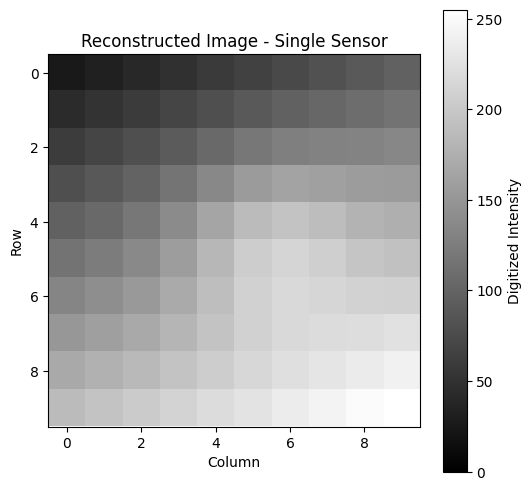

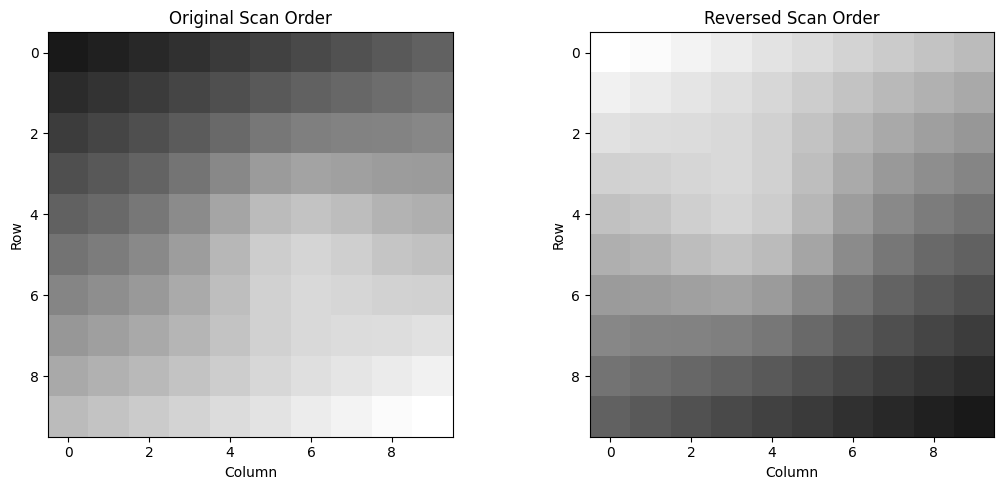

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SINGLE-ELEMENT SENSOR IMAGE RECONSTRUCTION
# ============================================================


# ------------------------------------------------------------
# 1. Load the single-sensor stream
# ------------------------------------------------------------

df = pd.read_csv((DATA_DIR / "single_sensor_stream.csv"))

print("===== DATASET INFORMATION =====")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 samples:")
print(df.head(10))


# ------------------------------------------------------------
# Verify required columns
# ------------------------------------------------------------

required_columns = [
    "sample_index",
    "row",
    "col",
    "digitized_intensity"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("\nRequired columns verified successfully.")


# ------------------------------------------------------------
# 2. Reconstruct the original 10x10 image
# ------------------------------------------------------------

image = np.zeros((10, 10), dtype=np.uint8)

for _, sample in df.iterrows():

    row = int(sample["row"])
    col = int(sample["col"])
    intensity = int(sample["digitized_intensity"])

    image[row, col] = intensity


print("\n===== RECONSTRUCTED 10x10 IMAGE =====")
print(image)

print("\nReconstructed image shape:", image.shape)


# ------------------------------------------------------------
# 3. Display reconstructed image
# using nearest-neighbor visualization
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.colorbar(label="Digitized Intensity")

plt.title(
    "Reconstructed Image - Single Sensor"
)

plt.xlabel("Column")
plt.ylabel("Row")

plt.show()


# ------------------------------------------------------------
# 4. Find maximum intensity and its location
# ------------------------------------------------------------

max_intensity = np.max(image)

max_flat_index = np.argmax(image)

max_row, max_col = np.unravel_index(
    max_flat_index,
    image.shape
)

print("\n===== MAXIMUM INTENSITY =====")

print(
    "Maximum intensity:",
    max_intensity
)

print(
    f"Location: row = {max_row}, "
    f"column = {max_col}"
)

print(
    f"Coordinate: ({max_row}, {max_col})"
)


# ------------------------------------------------------------
# 5. Reverse the serial measurement stream
# ------------------------------------------------------------

reversed_df = df.iloc[::-1].reset_index(drop=True)

print("\n===== REVERSED SERIAL STREAM =====")

print(
    reversed_df[
        [
            "sample_index",
            "row",
            "col",
            "digitized_intensity"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# 6. Reconstruction using reversed SERIAL ORDER
#
# Here we intentionally reconstruct by acquisition order
# rather than using the stored row/column coordinates.
# This demonstrates why scan order matters.
# ------------------------------------------------------------

original_serial_values = (
    df
    .sort_values("sample_index")
    ["digitized_intensity"]
    .to_numpy()
)

reversed_serial_values = (
    original_serial_values[::-1]
)


# Original serial stream interpreted as row-major 10x10
original_from_stream = original_serial_values.reshape(
    10,
    10
)


# Reversed stream interpreted using the SAME assumed
# row-major scan order
reversed_image = reversed_serial_values.reshape(
    10,
    10
)


print(
    "\n===== ORIGINAL IMAGE FROM SERIAL ORDER ====="
)

print(original_from_stream)


print(
    "\n===== IMAGE FROM REVERSED SERIAL ORDER ====="
)

print(reversed_image)


# ------------------------------------------------------------
# 7. Display original and reversed reconstruction
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5)
)


# Original reconstruction
axes[0].imshow(
    original_from_stream,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

axes[0].set_title(
    "Original Scan Order"
)

axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")


# Reversed reconstruction
axes[1].imshow(
    reversed_image,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

axes[1].set_title(
    "Reversed Scan Order"
)

axes[1].set_xlabel("Column")
axes[1].set_ylabel("Row")


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Compare reconstruction using explicit coordinates
# ------------------------------------------------------------
#
# Important observation:
#
# If the reversed records still retain their correct row/column
# coordinates, reconstruction using those coordinates should
# reproduce the original image.
#
# This shows the difference between:
#
# 1. a raw serial stream whose position depends on scan order
# 2. samples that explicitly store spatial coordinates
# ------------------------------------------------------------

coordinate_reconstruction = np.zeros(
    (10, 10),
    dtype=np.uint8
)

for _, sample in reversed_df.iterrows():

    row = int(sample["row"])
    col = int(sample["col"])
    intensity = int(sample["digitized_intensity"])

    coordinate_reconstruction[
        row,
        col
    ] = intensity


same_with_coordinates = np.array_equal(
    image,
    coordinate_reconstruction
)


print(
    "\n===== SCAN ORDER ANALYSIS ====="
)

print(
    "Does reversing records change the image "
    "when explicit row/column coordinates are used?"
)

print(
    "No" if same_with_coordinates else "Yes"
)

print(
    "\nWhen only a raw serial stream is available, "
    "the assumed scan order determines where each "
    "intensity sample is placed."
)

print(
    "When correct row and column coordinates are "
    "stored with every measurement, the original "
    "spatial arrangement can still be recovered "
    "even if the records themselves are reversed."
)


### Interpretation
Sequential sensing can reconstruct a spatial image from a one-dimensional stream, but interpretation depends on knowing where each measurement belongs. Explicit row/column coordinates make reconstruction independent of record ordering, whereas an untagged serial stream depends directly on the assumed scan sequence.


## 9. Line-Sensor Reconstruction and Missing-Line Interpolation

### Introduction
A one-dimensional sensor strip can acquire a two-dimensional image when either the strip or the scene moves in the perpendicular direction. This principle is widely used in scanners, industrial inspection, and push-broom imaging.

### Method
The 12×20 matrix represents 12 motion steps captured by a 20-element line sensor. Each row is one acquired line, and stacking these rows reconstructs the full image.

Selected line profiles are plotted to show how intensity changes across the sensor. Mean intensity is calculated for every acquired line, and the brightest line is identified. To model data loss, one row is removed and reconstructed by linear interpolation from its neighboring rows.

The interpolated line is compared with the original using mean absolute error and mean squared error. This demonstrates both the usefulness and the limitations of recovering missing scan lines from nearby measurements.


===== DATASET INFORMATION =====
Shape: (12, 20)

Sensor Strip Matrix:
[[ 35.  40.  45.  50.  55.  60.  65.  70.  75.  80.  85.  90.  95. 100.
  105. 110. 115. 120. 125. 130.]
 [ 43.  48.  53.  58.  63.  68.  74.  79.  85.  91.  96. 101. 106. 111.
  115. 119. 124. 128. 133. 138.]
 [ 51.  56.  61.  66.  72.  78.  84.  91.  99. 106. 112. 118. 122. 126.
  129. 131. 134. 138. 142. 146.]
 [ 59.  64.  69.  75.  82.  89.  98. 108. 118. 128. 136. 143. 146. 148.
  148. 148. 148. 149. 152. 155.]
 [ 67.  72.  78.  84.  92. 102. 114. 128. 143. 157. 169. 176. 179. 177.
  173. 168. 164. 162. 162. 164.]
 [ 75.  80.  86.  94. 103. 115. 130. 148. 167. 186. 200. 209. 210. 206.
  197. 188. 180. 175. 173. 174.]
 [ 83.  88.  95. 102. 112. 125. 141. 161. 182. 203. 219. 228. 229. 223.
  212. 201. 191. 185. 182. 182.]
 [ 91.  96. 102. 110. 119. 131. 146. 164. 183. 202. 216. 225. 226. 222.
  213. 204. 196. 191. 189. 190.]
 [ 99. 104. 110. 116. 124. 134. 146. 160. 175. 189. 201. 208. 211. 209.
  205. 200. 196. 1

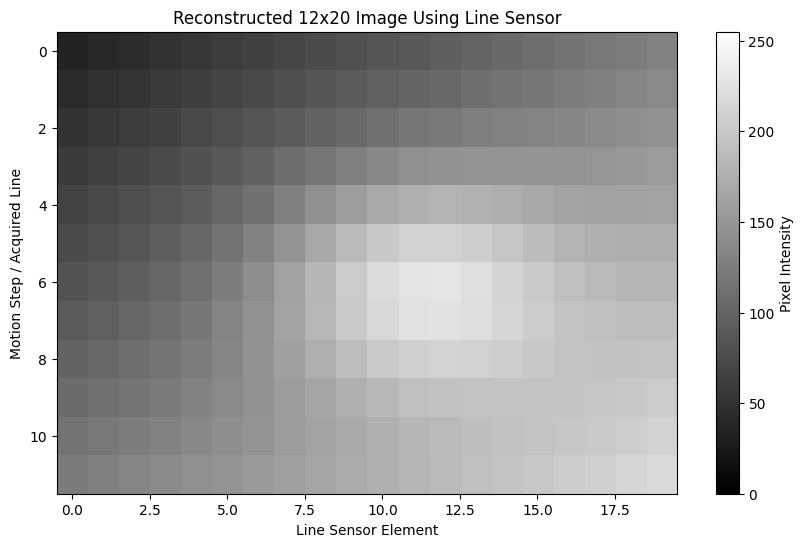

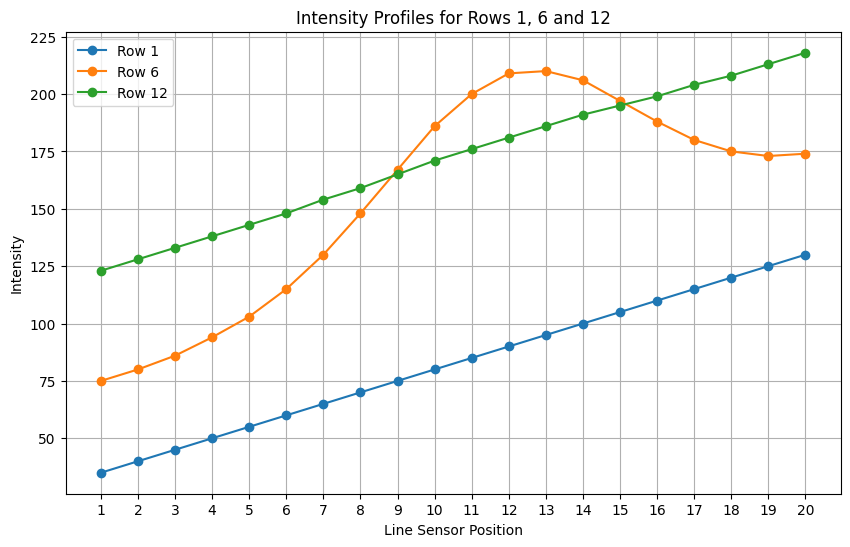

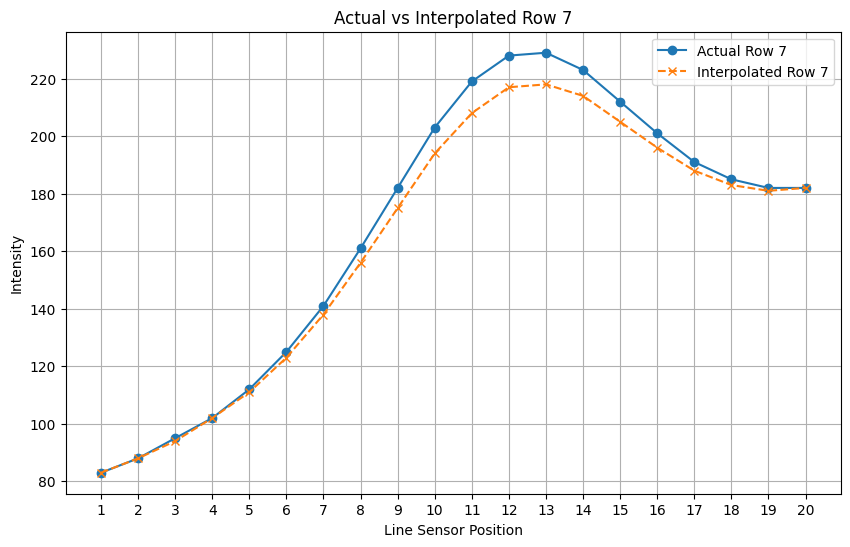

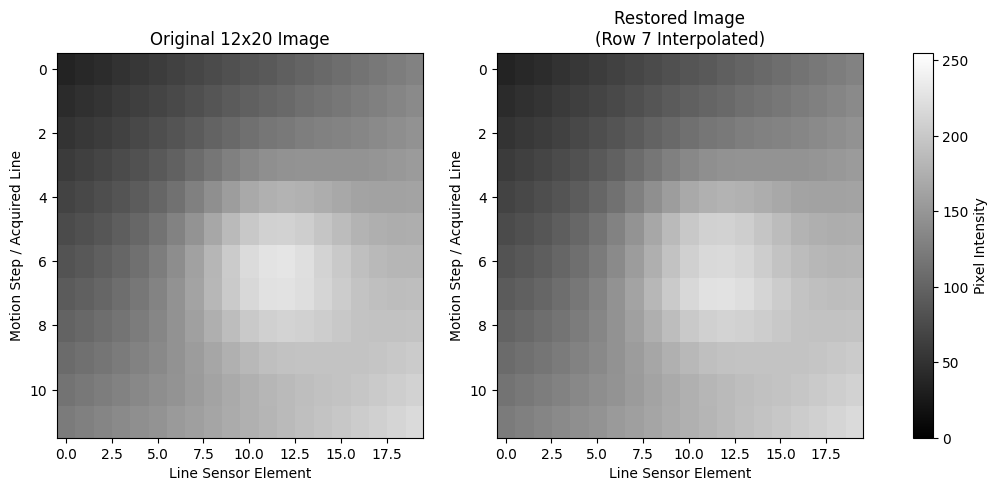

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# LINE-SENSOR RECONSTRUCTION AND MISSING-LINE INTERPOLATION
# ============================================================


# ------------------------------------------------------------
# 1. Load the dataset correctly
# ------------------------------------------------------------

# The CSV contains raw 12x20 intensity values and has no header.
# Therefore, header=None is required.
df = pd.read_csv(
    (DATA_DIR / "sensor_strip_lines_12x20.csv"),
    header=None
)

sensor_data = df.to_numpy(dtype=float)


print("===== DATASET INFORMATION =====")

print("Shape:", sensor_data.shape)

print("\nSensor Strip Matrix:")
print(sensor_data)


# ------------------------------------------------------------
# 2. Confirm number of line sensors and motion steps
# ------------------------------------------------------------

# According to the data:
# Rows    = successive motion steps / acquired image lines
# Columns = individual sensing elements in the line sensor

motion_steps = sensor_data.shape[0]
line_sensors = sensor_data.shape[1]

print("\n===== SENSOR CONFIGURATION =====")

print("Number of line sensors:", line_sensors)
print("Number of motion steps:", motion_steps)

print(
    "Total acquired samples:",
    sensor_data.size
)


# Verify expected dimensions
if sensor_data.shape == (12, 20):
    print("Shape verification: Correct (12 x 20)")
else:
    print(
        "WARNING: Expected shape (12, 20), "
        f"but received {sensor_data.shape}"
    )


# ------------------------------------------------------------
# 3. Reconstruct and display the 12x20 image
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

image_plot = plt.imshow(
    sensor_data,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(
    image_plot,
    label="Pixel Intensity"
)

plt.title(
    "Reconstructed 12x20 Image Using Line Sensor"
)

plt.xlabel("Line Sensor Element")
plt.ylabel("Motion Step / Acquired Line")

plt.show()


# ------------------------------------------------------------
# 4. Extract intensity profiles for rows 1, 6 and 12
# ------------------------------------------------------------

# IMPORTANT:
# The source uses one-based row numbering (1 to 12),
# while NumPy uses zero-based indexing (0 to 11).
#
# Therefore:
# Source Row 1  -> NumPy index 0
# Source Row 6  -> NumPy index 5
# Source Row 12 -> NumPy index 11

row_1 = sensor_data[0, :]
row_6 = sensor_data[5, :]
row_12 = sensor_data[11, :]

sensor_positions = np.arange(
    1,
    line_sensors + 1
)


# Plot all three profiles on one graph
plt.figure(figsize=(10, 6))

plt.plot(
    sensor_positions,
    row_1,
    marker="o",
    label="Row 1"
)

plt.plot(
    sensor_positions,
    row_6,
    marker="o",
    label="Row 6"
)

plt.plot(
    sensor_positions,
    row_12,
    marker="o",
    label="Row 12"
)

plt.title(
    "Intensity Profiles for Rows 1, 6 and 12"
)

plt.xlabel("Line Sensor Position")
plt.ylabel("Intensity")

plt.xticks(sensor_positions)

plt.legend()
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 5. Calculate mean intensity of every acquired line
# ------------------------------------------------------------

line_means = np.mean(
    sensor_data,
    axis=1
)

print("\n===== MEAN INTENSITY OF EACH LINE =====")

for i, mean_value in enumerate(
    line_means,
    start=1
):
    print(
        f"Row {i}: "
        f"Mean Intensity = {mean_value:.2f}"
    )


# ------------------------------------------------------------
# 6. Find the brightest line
# ------------------------------------------------------------

brightest_index = np.argmax(
    line_means
)

brightest_row_number = (
    brightest_index + 1
)

brightest_mean = line_means[
    brightest_index
]


print("\n===== BRIGHTEST LINE =====")

print(
    "Brightest row:",
    brightest_row_number
)

print(
    f"Mean intensity: "
    f"{brightest_mean:.2f}"
)


# ------------------------------------------------------------
# 7. Delete Row 7
# ------------------------------------------------------------

# Source Row 7 corresponds to NumPy index 6.

missing_row_index = 6

data_with_missing_row = np.delete(
    sensor_data,
    missing_row_index,
    axis=0
)

print("\n===== AFTER DELETING ROW 7 =====")

print(
    "Original shape:",
    sensor_data.shape
)

print(
    "Shape after deletion:",
    data_with_missing_row.shape
)


# ------------------------------------------------------------
# 8. Restore Row 7 using linear interpolation
# ------------------------------------------------------------

# Row 7 lies exactly between Row 6 and Row 8.
#
# Linear interpolation at the midpoint:
#
# Row7 = Row6 + 0.5 * (Row8 - Row6)
#
# which is equivalent to:
#
# Row7 = (Row6 + Row8) / 2

row_6_neighbor = sensor_data[5, :]
row_8_neighbor = sensor_data[7, :]

interpolated_row_7 = (
    row_6_neighbor
    + 0.5 * (
        row_8_neighbor
        - row_6_neighbor
    )
)


print("\n===== INTERPOLATED ROW 7 =====")

print(interpolated_row_7)


# ------------------------------------------------------------
# 9. Reconstruct the image with interpolated Row 7
# ------------------------------------------------------------

restored_data = np.insert(
    data_with_missing_row,
    missing_row_index,
    interpolated_row_7,
    axis=0
)


print("\nRestored shape:", restored_data.shape)

if restored_data.shape == (12, 20):
    print(
        "Restoration shape verification: "
        "Correct (12 x 20)"
    )


# ------------------------------------------------------------
# 10. Compare actual Row 7 with interpolated Row 7
# ------------------------------------------------------------

actual_row_7 = sensor_data[6, :]

print("\n===== ROW 7 COMPARISON =====")

print("Actual Row 7:")
print(actual_row_7)

print("\nInterpolated Row 7:")
print(interpolated_row_7)


# Calculate reconstruction error for Row 7
row_7_mse = np.mean(
    (
        actual_row_7
        - interpolated_row_7
    ) ** 2
)

row_7_mae = np.mean(
    np.abs(
        actual_row_7
        - interpolated_row_7
    )
)

print(
    f"\nRow 7 Mean Absolute Error (MAE): "
    f"{row_7_mae:.2f}"
)

print(
    f"Row 7 Mean Squared Error (MSE): "
    f"{row_7_mse:.2f}"
)


# ------------------------------------------------------------
# 11. Plot actual vs interpolated Row 7
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    sensor_positions,
    actual_row_7,
    marker="o",
    label="Actual Row 7"
)

plt.plot(
    sensor_positions,
    interpolated_row_7,
    marker="x",
    linestyle="--",
    label="Interpolated Row 7"
)

plt.title(
    "Actual vs Interpolated Row 7"
)

plt.xlabel("Line Sensor Position")
plt.ylabel("Intensity")

plt.xticks(sensor_positions)

plt.legend()
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 12. Display original and restored images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)


# Original image
original_plot = axes[0].imshow(
    sensor_data,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
    aspect="auto"
)

axes[0].set_title(
    "Original 12x20 Image"
)

axes[0].set_xlabel(
    "Line Sensor Element"
)

axes[0].set_ylabel(
    "Motion Step / Acquired Line"
)


# Restored image
restored_plot = axes[1].imshow(
    restored_data,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
    aspect="auto"
)

axes[1].set_title(
    "Restored Image\n(Row 7 Interpolated)"
)

axes[1].set_xlabel(
    "Line Sensor Element"
)

axes[1].set_ylabel(
    "Motion Step / Acquired Line"
)


fig.colorbar(
    restored_plot,
    ax=axes,
    label="Pixel Intensity"
)

plt.show()


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n===== ANALYSIS SUMMARY =====")

print(
    f"Line sensor elements: {line_sensors}"
)

print(
    f"Motion steps: {motion_steps}"
)

print(
    f"Image dimensions: "
    f"{motion_steps} x {line_sensors}"
)

print(
    f"Brightest line: Row "
    f"{brightest_row_number}"
)

print(
    f"Brightest line mean intensity: "
    f"{brightest_mean:.2f}"
)

print(
    "Missing Row 7 was restored using "
    "linear interpolation between "
    "Rows 6 and 8."
)


### Interpretation
A moving line sensor efficiently builds a 2D image one row at a time. Linear interpolation can repair a missing scan line when neighboring rows vary smoothly, but the reconstruction cannot recover unique detail that existed only in the missing line. The reported MAE and MSE quantify that limitation.


## 10. 2D Sensor Array Spatial Analysis

### Introduction
Modern cameras commonly use two-dimensional sensor arrays that capture both spatial dimensions at the same instant. This eliminates the mechanical scanning required by single-element and line-sensor systems.

### Method
The 20×20 sensor matrix is loaded as a direct intensity image. Its dimensions and total number of samples are verified before the data is visualized as both a conventional grayscale image and a three-dimensional intensity surface.

Global extrema are located, and the image is divided into four 10×10 quadrants to compare regional mean intensity. A threshold of 150 is then applied to identify high-response pixels and calculate their proportion of the complete array.

The combination of spatial visualization, regional statistics, and threshold analysis demonstrates how a 2D sensor array can be treated simultaneously as an image and as a structured numerical measurement grid.


===== DATASET INFORMATION =====
Array shape: (20, 20)
Number of pixels: 400

20x20 Sensor Array:
[[ 32.  34.  37.  40.  45.  49.  52.  53.  52.  49.  45.  41.  37.  34.
   32.  31.  31.  30.  30.  30.]
 [ 43.  46.  51.  58.  65.  72.  78.  80.  78.  73.  65.  58.  51.  47.
   43.  42.  41.  40.  40.  40.]
 [ 52.  57.  65.  75.  87.  98. 107. 110. 107.  99.  88.  76.  66.  58.
   53.  50.  49.  48.  47.  47.]
 [ 58.  65.  76.  90. 107. 123. 135. 140. 136. 124. 108.  92.  77.  66.
   59.  55.  53.  52.  51.  51.]
 [ 58.  67.  81. 100. 122. 142. 158. 164. 159. 144. 124. 103.  84.  71.
   61.  56.  53.  51.  50.  49.]
 [ 53.  64.  80. 102. 127. 152. 170. 177. 171. 155. 132. 107.  86.  70.
   60.  53.  49.  47.  45.  44.]
 [ 45.  56.  73.  96. 123. 149. 168. 176. 171. 154. 130. 106.  84.  67.
   56.  48.  44.  40.  38.  36.]
 [ 35.  45.  61.  83. 109. 134. 153. 162. 158. 143. 122.  99.  79.  64.
   52.  45.  39.  35.  31.  29.]
 [ 25.  34.  48.  67.  90. 112. 129. 138. 136. 125. 109.  91.  

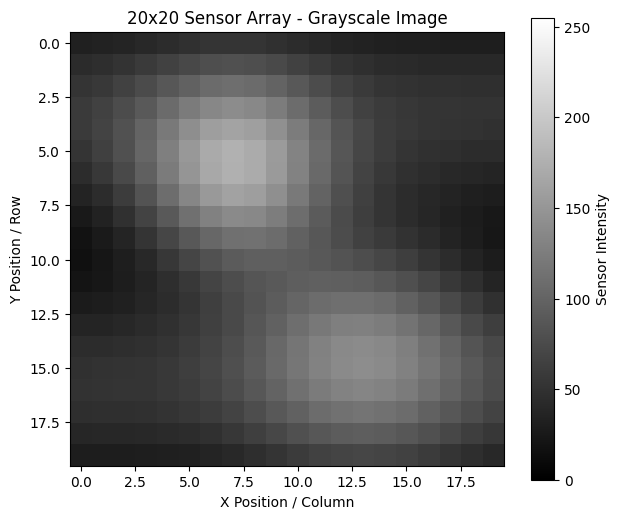

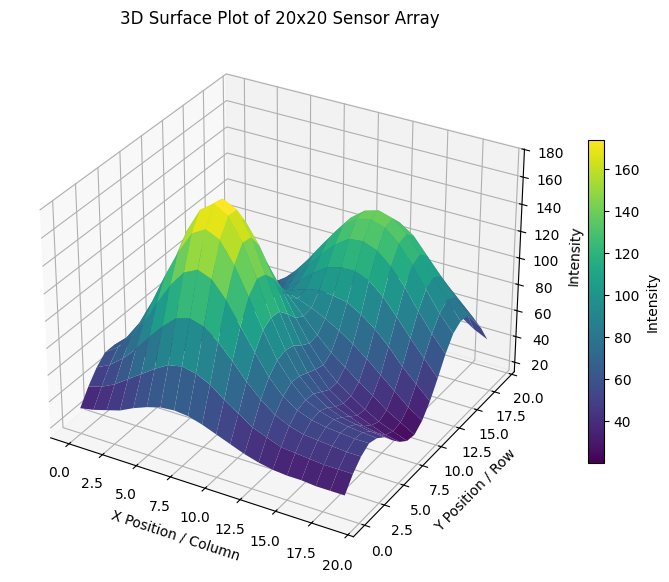

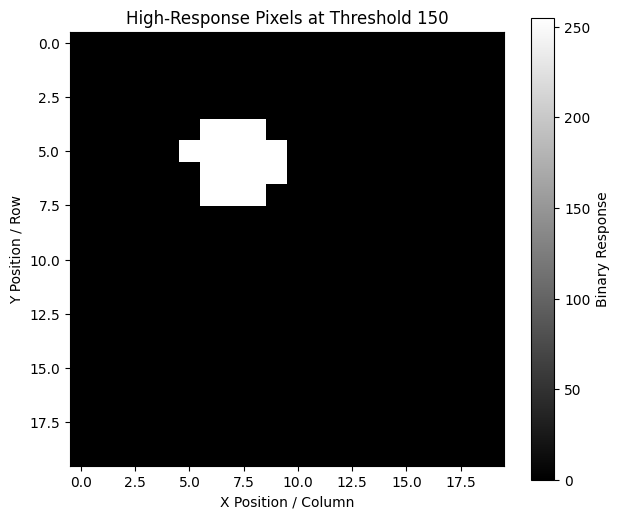

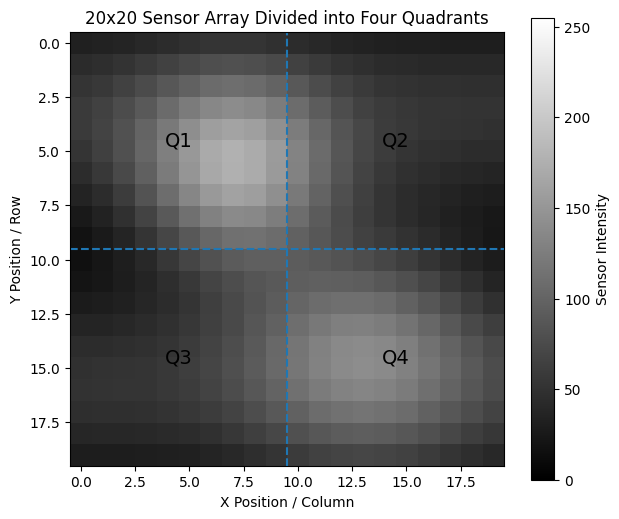

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 2D SENSOR ARRAY SPATIAL ANALYSIS
# ============================================================


# ------------------------------------------------------------
# 1. Load the 20x20 sensor array
# ------------------------------------------------------------

# The CSV is a raw matrix with no column headers.
sensor_df = pd.read_csv(
    (DATA_DIR / "sensor_array_20x20.csv"),
    header=None
)

sensor_array = sensor_df.to_numpy(dtype=float)


print("===== DATASET INFORMATION =====")

print("Array shape:", sensor_array.shape)
print("Number of pixels:", sensor_array.size)

print("\n20x20 Sensor Array:")
print(sensor_array)


# ------------------------------------------------------------
# 2. Verify the required shape
# ------------------------------------------------------------

expected_shape = (20, 20)

if sensor_array.shape == expected_shape:
    print("\nShape verification: Correct (20 x 20)")
else:
    raise ValueError(
        f"Expected a 20x20 sensor array, "
        f"but received {sensor_array.shape}"
    )


# ------------------------------------------------------------
# 3. Display the sensor array as a grayscale image
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

img = plt.imshow(
    sensor_array,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.colorbar(
    img,
    label="Sensor Intensity"
)

plt.title("20x20 Sensor Array - Grayscale Image")
plt.xlabel("X Position / Column")
plt.ylabel("Y Position / Row")

plt.show()


# ------------------------------------------------------------
# 4. Create X and Y coordinate grids
# ------------------------------------------------------------

rows, cols = sensor_array.shape

x = np.arange(cols)
y = np.arange(rows)

X, Y = np.meshgrid(x, y)

Z = sensor_array


print("\n===== COORDINATE GRID INFORMATION =====")

print("X grid shape:", X.shape)
print("Y grid shape:", Y.shape)
print("Z intensity shape:", Z.shape)


# ------------------------------------------------------------
# 5. Create a 3D surface plot
# ------------------------------------------------------------

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X,
    Y,
    Z,
    cmap="viridis"
)

fig.colorbar(
    surface,
    ax=ax,
    shrink=0.6,
    label="Intensity"
)

ax.set_title(
    "3D Surface Plot of 20x20 Sensor Array"
)

ax.set_xlabel("X Position / Column")
ax.set_ylabel("Y Position / Row")
ax.set_zlabel("Intensity")

plt.show()


# ------------------------------------------------------------
# 6. Find global minimum and maximum
# ------------------------------------------------------------

minimum_intensity = np.min(sensor_array)
maximum_intensity = np.max(sensor_array)


# Find flattened locations
minimum_flat_index = np.argmin(sensor_array)
maximum_flat_index = np.argmax(sensor_array)


# Convert flattened positions back to row/column coordinates
minimum_coordinate = np.unravel_index(
    minimum_flat_index,
    sensor_array.shape
)

maximum_coordinate = np.unravel_index(
    maximum_flat_index,
    sensor_array.shape
)


print("\n===== GLOBAL MINIMUM AND MAXIMUM =====")

print(
    f"Minimum intensity: {minimum_intensity}"
)

print(
    f"Minimum coordinate (row, column): "
    f"{minimum_coordinate}"
)

print(
    f"Maximum intensity: {maximum_intensity}"
)

print(
    f"Maximum coordinate (row, column): "
    f"{maximum_coordinate}"
)


# ------------------------------------------------------------
# 7. Divide the 20x20 array into four quadrants
# ------------------------------------------------------------

# Since the array is 20x20, each quadrant is 10x10.
#
# Quadrant 1 = top-left
# Quadrant 2 = top-right
# Quadrant 3 = bottom-left
# Quadrant 4 = bottom-right

half_row = rows // 2
half_col = cols // 2


quadrant_1 = sensor_array[
    0:half_row,
    0:half_col
]

quadrant_2 = sensor_array[
    0:half_row,
    half_col:cols
]

quadrant_3 = sensor_array[
    half_row:rows,
    0:half_col
]

quadrant_4 = sensor_array[
    half_row:rows,
    half_col:cols
]


# ------------------------------------------------------------
# 8. Calculate average intensity of each quadrant
# ------------------------------------------------------------

q1_mean = np.mean(quadrant_1)
q2_mean = np.mean(quadrant_2)
q3_mean = np.mean(quadrant_3)
q4_mean = np.mean(quadrant_4)


print("\n===== QUADRANT INFORMATION =====")

print("Quadrant 1 shape:", quadrant_1.shape)
print("Quadrant 2 shape:", quadrant_2.shape)
print("Quadrant 3 shape:", quadrant_3.shape)
print("Quadrant 4 shape:", quadrant_4.shape)


print("\n===== AVERAGE INTENSITY OF EACH QUADRANT =====")

print(
    f"Quadrant 1 (Top-Left): "
    f"{q1_mean:.2f}"
)

print(
    f"Quadrant 2 (Top-Right): "
    f"{q2_mean:.2f}"
)

print(
    f"Quadrant 3 (Bottom-Left): "
    f"{q3_mean:.2f}"
)

print(
    f"Quadrant 4 (Bottom-Right): "
    f"{q4_mean:.2f}"
)


# Determine quadrant with highest average response
quadrant_means = np.array([
    q1_mean,
    q2_mean,
    q3_mean,
    q4_mean
])

brightest_quadrant = np.argmax(
    quadrant_means
) + 1


print(
    "\nQuadrant with highest average intensity:",
    brightest_quadrant
)


# ------------------------------------------------------------
# 9. Threshold the sensor array at 150
# ------------------------------------------------------------

threshold = 150

# Reference threshold: high-response pixels at threshold 150.
# >= 150 is used so a pixel exactly equal to the threshold
# is included as a high-response pixel.
high_response_mask = sensor_array >= threshold

high_response_count = np.sum(
    high_response_mask
)

low_response_count = (
    sensor_array.size
    - high_response_count
)


print("\n===== THRESHOLD ANALYSIS =====")

print("Threshold:", threshold)

print(
    "High-response pixels (>= 150):",
    high_response_count
)

print(
    "Pixels below 150:",
    low_response_count
)

print(
    "Total pixels:",
    sensor_array.size
)


high_response_percentage = (
    high_response_count
    / sensor_array.size
) * 100


print(
    f"High-response percentage: "
    f"{high_response_percentage:.2f}%"
)


# ------------------------------------------------------------
# 10. Create binary threshold image
# ------------------------------------------------------------

# Convert Boolean mask into conventional binary image:
# False -> 0
# True  -> 255

binary_image = (
    high_response_mask.astype(np.uint8)
    * 255
)


print("\n===== BINARY THRESHOLD MATRIX =====")
print(binary_image)


# ------------------------------------------------------------
# 11. Display thresholded image
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

threshold_plot = plt.imshow(
    binary_image,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.colorbar(
    threshold_plot,
    label="Binary Response"
)

plt.title(
    "High-Response Pixels at Threshold 150"
)

plt.xlabel("X Position / Column")
plt.ylabel("Y Position / Row")

plt.show()


# ------------------------------------------------------------
# 12. Visualize the four quadrants
# ------------------------------------------------------------

# Add boundary lines through the middle of the original image.

plt.figure(figsize=(7, 6))

quadrant_plot = plt.imshow(
    sensor_array,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.colorbar(
    quadrant_plot,
    label="Sensor Intensity"
)


# Boundary lies between indices 9 and 10
plt.axvline(
    x=9.5,
    linestyle="--"
)

plt.axhline(
    y=9.5,
    linestyle="--"
)


plt.text(
    4.5,
    4.5,
    "Q1",
    ha="center",
    va="center",
    fontsize=14
)

plt.text(
    14.5,
    4.5,
    "Q2",
    ha="center",
    va="center",
    fontsize=14
)

plt.text(
    4.5,
    14.5,
    "Q3",
    ha="center",
    va="center",
    fontsize=14
)

plt.text(
    14.5,
    14.5,
    "Q4",
    ha="center",
    va="center",
    fontsize=14
)


plt.title(
    "20x20 Sensor Array Divided into Four Quadrants"
)

plt.xlabel("X Position / Column")
plt.ylabel("Y Position / Row")

plt.show()


# ------------------------------------------------------------
# 13. Final analysis 10 summary
# ------------------------------------------------------------

print("\n===== ANALYSIS SUMMARY =====")

print(
    f"Sensor array dimensions: "
    f"{rows} x {cols}"
)

print(
    f"Total sensing elements: "
    f"{sensor_array.size}"
)

print(
    f"Global minimum: "
    f"{minimum_intensity} "
    f"at {minimum_coordinate}"
)

print(
    f"Global maximum: "
    f"{maximum_intensity} "
    f"at {maximum_coordinate}"
)

print(
    f"Q1 average intensity: "
    f"{q1_mean:.2f}"
)

print(
    f"Q2 average intensity: "
    f"{q2_mean:.2f}"
)

print(
    f"Q3 average intensity: "
    f"{q3_mean:.2f}"
)

print(
    f"Q4 average intensity: "
    f"{q4_mean:.2f}"
)

print(
    f"High-response pixels "
    f"(>= {threshold}): "
    f"{high_response_count}"
)

print(
    f"High-response percentage: "
    f"{high_response_percentage:.2f}%"
)


### Interpretation
A 2D sensor array captures spatial structure directly without mechanical scanning across the image plane. Regional statistics and thresholding show how the same array can support both visual inspection and quantitative detection, which is a common pattern in practical image-processing pipelines.


## 11. 3D Sensor Volume Reconstruction

### Introduction
Volumetric imaging extends the concept of a 2D sensor image into three dimensions. A volume can be constructed by stacking multiple 2D slices along a depth axis, turning pixels into voxels.

### Method
Eight 20×20 CSV slices are loaded and stacked into an array with shape \(8\times20\times20\). The reconstructed volume is compared with the supplied NumPy reference file `sensor_volume_8x20x20.npy` to verify consistency.

Representative depth slices are displayed, and orthogonal \(x\)-\(z\) and \(y\)-\(z\) cross-sections are extracted through the center of the volume. High-intensity voxels are counted using threshold values, and a 3D scatter visualization is produced when qualifying voxels exist.

This section demonstrates the data organization behind CT, MRI, microscopy, and other applications in which a three-dimensional field is reconstructed from a sequence of two-dimensional measurements.


===== LOADING CSV SLICES =====
Slice 1: shape = (20, 20), min = 10, max = 115
Slice 2: shape = (20, 20), min = 11, max = 124
Slice 3: shape = (20, 20), min = 12, max = 133
Slice 4: shape = (20, 20), min = 13, max = 142
Slice 5: shape = (20, 20), min = 14, max = 150
Slice 6: shape = (20, 20), min = 14, max = 159
Slice 7: shape = (20, 20), min = 15, max = 168
Slice 8: shape = (20, 20), min = 16, max = 177

All 8 CSV slices loaded successfully.

===== STACKED 3D VOLUME =====
Volume shape: (8, 20, 20)
Data type: uint8
Minimum intensity: 10
Maximum intensity: 177
Total number of voxels: 3200
Shape verification: Correct (8, 20, 20)

===== SUPPLIED NPY VOLUME =====
NPY shape: (8, 20, 20)
NPY data type: uint8
NPY minimum: 10
NPY maximum: 177

CSV-stacked volume matches NPY volume: True

===== X-Z PLANE =====
Fixed Y index: 10
X-Z plane shape: (8, 20)

===== Y-Z PLANE =====
Fixed X index: 10
Y-Z plane shape: (8, 20)

===== VOXEL THRESHOLD >= 150 =====
Voxels with intensity >= 150: 34
Total voxe

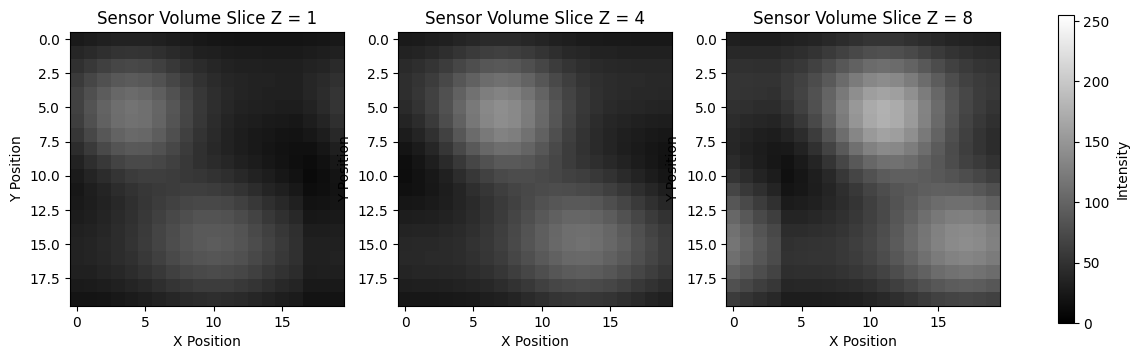

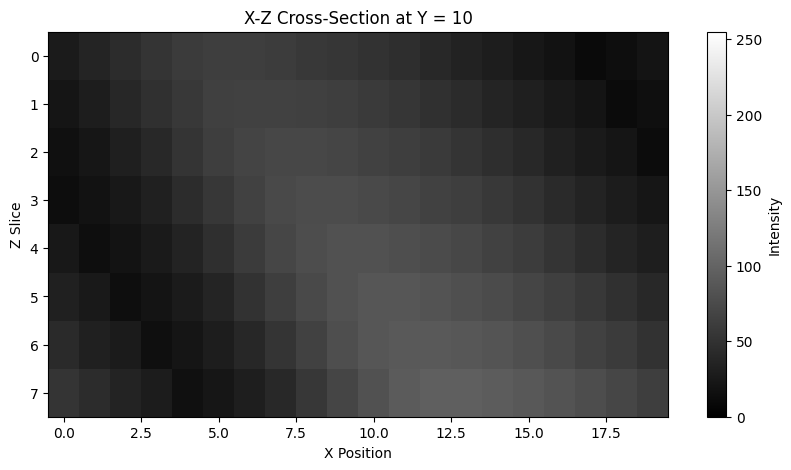

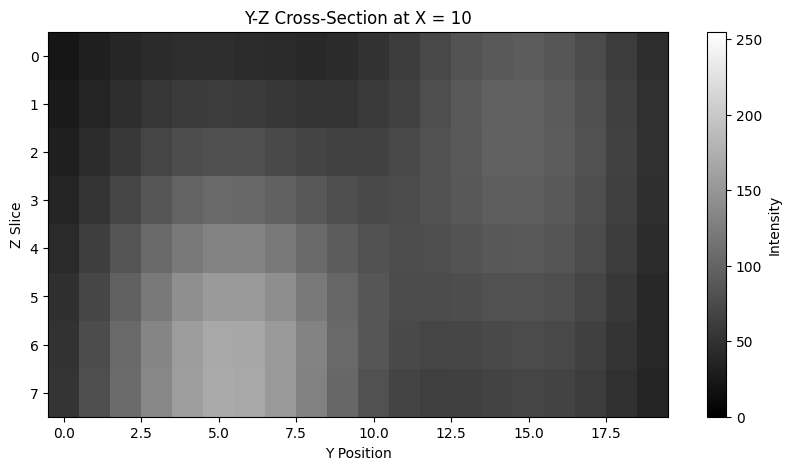

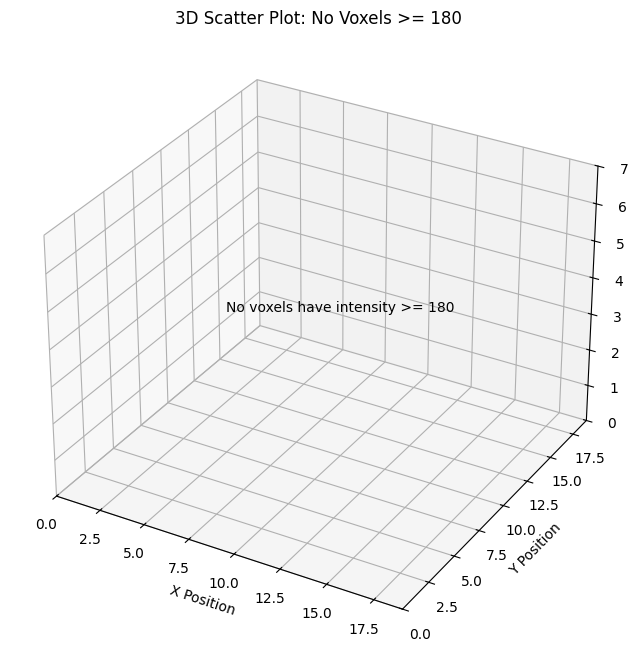

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 3D SENSOR VOLUME RECONSTRUCTION
# ============================================================


# ------------------------------------------------------------
# 1. Load all eight 20x20 CSV slices
# ------------------------------------------------------------

slices = []

print("===== LOADING CSV SLICES =====")

for i in range(1, 9):

    filename = DATA_DIR / f"sensor_volume_slice_{i:02d}.csv"

    # CSV files contain raw matrices with no headers
    df = pd.read_csv(
        filename,
        header=None
    )

    slice_array = df.to_numpy(dtype=np.uint8)

    print(
        f"Slice {i}: "
        f"shape = {slice_array.shape}, "
        f"min = {slice_array.min()}, "
        f"max = {slice_array.max()}"
    )

    # Verify each slice is 20x20
    if slice_array.shape != (20, 20):
        raise ValueError(
            f"{filename} has shape "
            f"{slice_array.shape}; expected (20, 20)"
        )

    slices.append(slice_array)


print("\nAll 8 CSV slices loaded successfully.")


# ------------------------------------------------------------
# 2. Stack the slices along the Z-axis
# ------------------------------------------------------------

volume = np.stack(
    slices,
    axis=0
)


print("\n===== STACKED 3D VOLUME =====")

print("Volume shape:", volume.shape)
print("Data type:", volume.dtype)
print("Minimum intensity:", volume.min())
print("Maximum intensity:", volume.max())
print("Total number of voxels:", volume.size)


# Expected shape
expected_shape = (8, 20, 20)

if volume.shape == expected_shape:
    print(
        "Shape verification: Correct (8, 20, 20)"
    )
else:
    raise ValueError(
        f"Expected {expected_shape}, "
        f"but received {volume.shape}"
    )


# ------------------------------------------------------------
# 3. Load supplied NumPy .npy volume
# ------------------------------------------------------------

volume_npy = np.load(
    (DATA_DIR / "sensor_volume_8x20x20.npy")
)


print("\n===== SUPPLIED NPY VOLUME =====")

print("NPY shape:", volume_npy.shape)
print("NPY data type:", volume_npy.dtype)
print("NPY minimum:", volume_npy.min())
print("NPY maximum:", volume_npy.max())


# ------------------------------------------------------------
# 4. Compare CSV-stacked volume with supplied NPY volume
# ------------------------------------------------------------

if volume.shape == volume_npy.shape:

    volumes_equal = np.array_equal(
        volume,
        volume_npy
    )

    print(
        "\nCSV-stacked volume matches NPY volume:",
        volumes_equal
    )

    if not volumes_equal:

        different_voxels = np.sum(
            volume != volume_npy
        )

        print(
            "Number of different voxels:",
            different_voxels
        )

else:

    print(
        "\nCannot directly compare volumes "
        "because their shapes differ."
    )


# ------------------------------------------------------------
# 5. Display slices Z = 1, Z = 4 and Z = 8
# ------------------------------------------------------------

# Human-readable slice numbering:
#
# Z = 1 -> NumPy index 0
# Z = 4 -> NumPy index 3
# Z = 8 -> NumPy index 7

selected_slices = [
    (1, 0),
    (4, 3),
    (8, 7)
]


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


for ax, (z_number, index) in zip(
    axes,
    selected_slices
):

    image = ax.imshow(
        volume[index],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    ax.set_title(
        f"Sensor Volume Slice Z = {z_number}"
    )

    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")


fig.colorbar(
    image,
    ax=axes,
    label="Intensity",
    shrink=0.8
)

plt.show()


# ------------------------------------------------------------
# 6. Extract an X-Z cross-sectional plane
# ------------------------------------------------------------

# Volume dimensions:
#
# volume[z, y, x]
#
# To obtain an X-Z plane, hold Y constant.
#
# We select the central Y position.

central_y = volume.shape[1] // 2

xz_plane = volume[
    :,
    central_y,
    :
]


print("\n===== X-Z PLANE =====")

print(
    "Fixed Y index:",
    central_y
)

print(
    "X-Z plane shape:",
    xz_plane.shape
)


plt.figure(figsize=(10, 5))

xz_plot = plt.imshow(
    xz_plane,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(
    xz_plot,
    label="Intensity"
)

plt.title(
    f"X-Z Cross-Section at Y = {central_y}"
)

plt.xlabel("X Position")
plt.ylabel("Z Slice")

plt.show()


# ------------------------------------------------------------
# 7. Extract a Y-Z cross-sectional plane
# ------------------------------------------------------------

# To obtain a Y-Z plane, hold X constant.
#
# We select the central X position.

central_x = volume.shape[2] // 2

yz_plane = volume[
    :,
    :,
    central_x
]


print("\n===== Y-Z PLANE =====")

print(
    "Fixed X index:",
    central_x
)

print(
    "Y-Z plane shape:",
    yz_plane.shape
)


plt.figure(figsize=(10, 5))

yz_plot = plt.imshow(
    yz_plane,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(
    yz_plot,
    label="Intensity"
)

plt.title(
    f"Y-Z Cross-Section at X = {central_x}"
)

plt.xlabel("Y Position")
plt.ylabel("Z Slice")

plt.show()


# ------------------------------------------------------------
# 8. Count voxels with intensity >= 150
# ------------------------------------------------------------

threshold_150 = 150

mask_150 = volume >= threshold_150

voxel_count_150 = np.sum(
    mask_150
)

total_voxels = volume.size

percentage_150 = (
    voxel_count_150
    / total_voxels
) * 100


print("\n===== VOXEL THRESHOLD >= 150 =====")

print(
    "Voxels with intensity >= 150:",
    voxel_count_150
)

print(
    "Total voxels:",
    total_voxels
)

print(
    f"Percentage of high-response voxels: "
    f"{percentage_150:.2f}%"
)


# ------------------------------------------------------------
# 9. Find voxels with intensity >= 180
# ------------------------------------------------------------

threshold_180 = 180

mask_180 = volume >= threshold_180

voxel_count_180 = np.sum(
    mask_180
)


print("\n===== VOXEL THRESHOLD >= 180 =====")

print(
    "Maximum volume intensity:",
    volume.max()
)

print(
    "Voxels with intensity >= 180:",
    voxel_count_180
)


# ------------------------------------------------------------
# 10. Extract coordinates of >=180 voxels
# ------------------------------------------------------------

# np.where returns:
#
# z coordinates
# y coordinates
# x coordinates

z_coords, y_coords, x_coords = np.where(
    mask_180
)


# Extract corresponding intensity values
intensities_180 = volume[
    z_coords,
    y_coords,
    x_coords
]


# ------------------------------------------------------------
# 11. Create 3D scatter plot
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


if voxel_count_180 > 0:

    scatter = ax.scatter(
        x_coords,
        y_coords,
        z_coords,
        c=intensities_180,
        cmap="viridis",
        s=35
    )

    fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.6,
        label="Voxel Intensity"
    )

    ax.set_title(
        "3D Scatter Plot of Voxels "
        "with Intensity >= 180"
    )

else:

    # Dataset maximum may be below 180.
    # In that case, there are legitimately no
    # voxels to plot.

    ax.text(
        10,
        10,
        4,
        "No voxels have intensity >= 180",
        ha="center"
    )

    ax.set_title(
        "3D Scatter Plot: No Voxels >= 180"
    )


ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")
ax.set_zlabel("Z Slice")

ax.set_xlim(0, 19)
ax.set_ylim(0, 19)
ax.set_zlim(0, 7)

plt.show()


# ------------------------------------------------------------
# 12. Additional global 3D statistics
# ------------------------------------------------------------

minimum_intensity = np.min(volume)
maximum_intensity = np.max(volume)

mean_intensity = np.mean(volume)

minimum_location = np.unravel_index(
    np.argmin(volume),
    volume.shape
)

maximum_location = np.unravel_index(
    np.argmax(volume),
    volume.shape
)


print("\n===== 3D VOLUME STATISTICS =====")

print(
    "Minimum intensity:",
    minimum_intensity
)

print(
    "Minimum location (z, y, x):",
    minimum_location
)

print(
    "Maximum intensity:",
    maximum_intensity
)

print(
    "Maximum location (z, y, x):",
    maximum_location
)

print(
    f"Mean volume intensity: "
    f"{mean_intensity:.2f}"
)


# ------------------------------------------------------------
# 13. Final analysis 11 summary
# ------------------------------------------------------------

print("\n===== ANALYSIS SUMMARY =====")

print(
    "Number of 2D slices:",
    volume.shape[0]
)

print(
    "Individual slice dimensions:",
    volume.shape[1:]
)

print(
    "Final volume shape:",
    volume.shape
)

print(
    "Total voxels:",
    total_voxels
)

print(
    f"Voxels >= 150: "
    f"{voxel_count_150}"
)

print(
    f"Percentage >= 150: "
    f"{percentage_150:.2f}%"
)

print(
    f"Voxels >= 180: "
    f"{voxel_count_180}"
)

print(
    "X-Z plane shape:",
    xz_plane.shape
)

print(
    "Y-Z plane shape:",
    yz_plane.shape
)


### Interpretation
Stacking aligned 2D slices creates a volumetric dataset in which each voxel has \(x\), \(y\), and depth coordinates. Orthogonal cross-sections reveal internal structure that may not be obvious from individual slices, while threshold-based voxel analysis provides a simple way to isolate high-response regions.


## Part III — Sampling, Quantization, and Spatial Resolution

This part examines how spatial and intensity discretization affect detail, storage, reconstruction error, and measurable resolution.


## 12. Spatial Sampling and Resolution Loss

### Introduction
Spatial sampling determines how densely an image is measured across the \(x\) and \(y\) dimensions. Reducing the number of spatial samples lowers resolution and removes detail even when the intensity range remains unchanged.

### Method
The source image is progressively resampled from its original resolution to 256×256, 128×128, 64×64, and 32×32 pixels using nearest-neighbor sampling. The percentage of retained samples is calculated for each resolution.

Each reduced image is then enlarged back to the original dimensions. This restoration recovers the canvas size but cannot recreate spatial information that was discarded during downsampling. Mean squared error is calculated between the original and each restored image to quantify the loss.

The visual comparison makes pixelation increasingly obvious as sampling density decreases, while the numerical error provides an objective measure of degradation.


===== ORIGINAL IMAGE INFORMATION =====
Original shape: (512, 512)
Data type: uint8
Minimum intensity: 20
Maximum intensity: 255
Total samples: 262144
Shape verification: Correct (512 x 512)

===== SPATIAL SAMPLING RESULTS =====

Resolution: 256 x 256
Number of retained samples: 65536
Percentage of samples retained: 25.0000%

Resolution: 128 x 128
Number of retained samples: 16384
Percentage of samples retained: 6.2500%

Resolution: 64 x 64
Number of retained samples: 4096
Percentage of samples retained: 1.5625%

Resolution: 32 x 32
Number of retained samples: 1024
Percentage of samples retained: 0.3906%

===== RESTORATION MSE RESULTS =====
256 x 256 -> restored to 512 x 512 -> MSE = 448.6291
128 x 128 -> restored to 512 x 512 -> MSE = 887.3288
64 x 64 -> restored to 512 x 512 -> MSE = 1445.2683
32 x 32 -> restored to 512 x 512 -> MSE = 3974.3772

===== analysis 12 FINAL SUMMARY ====
Resolution     Samples        Retained (%)        MSE            
--------------------------------------

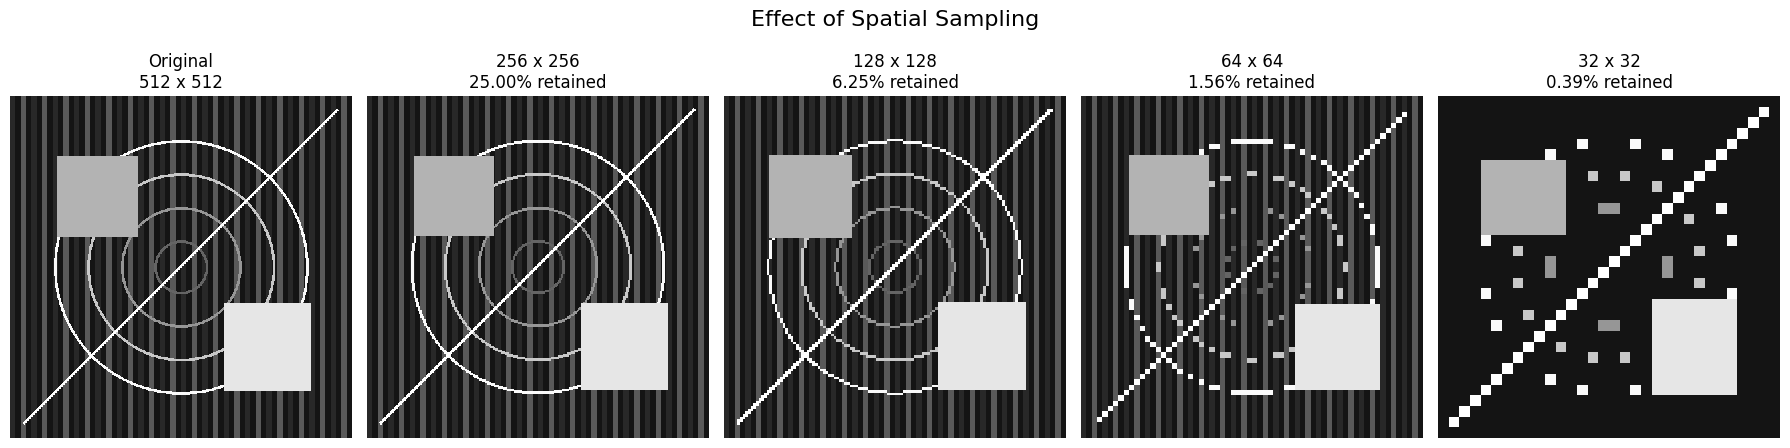

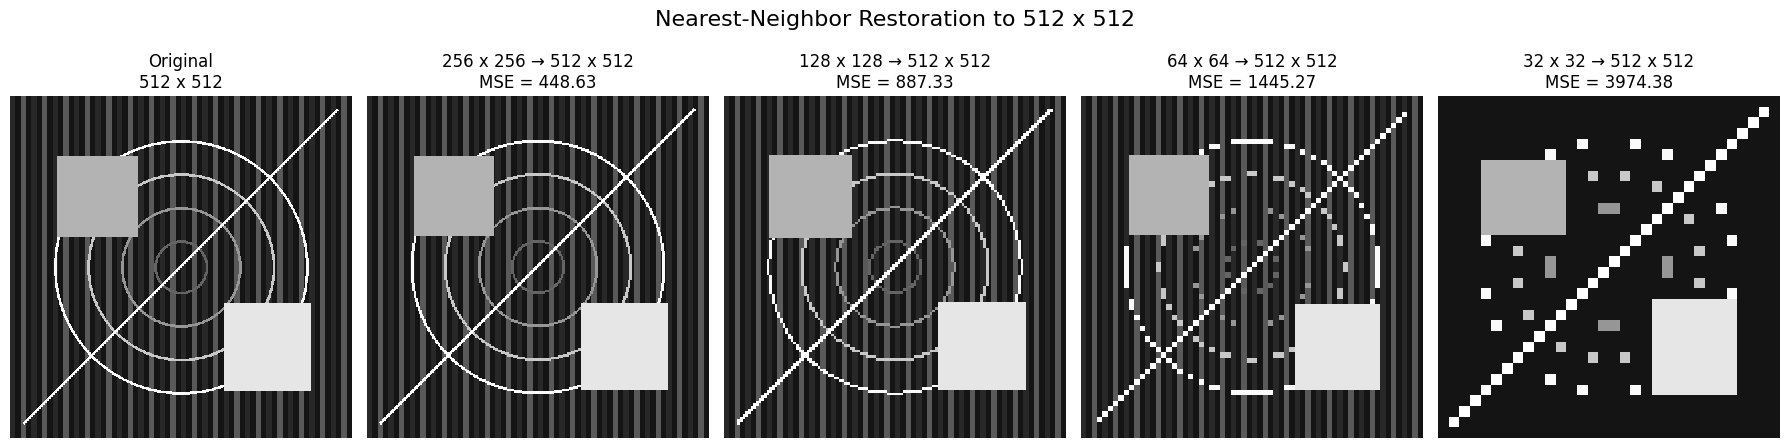

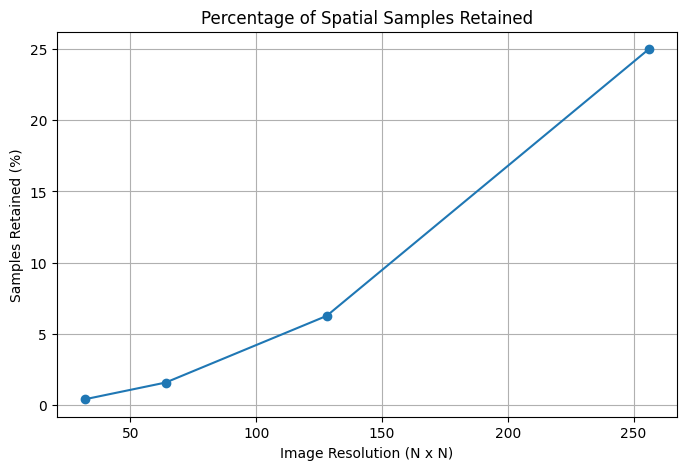

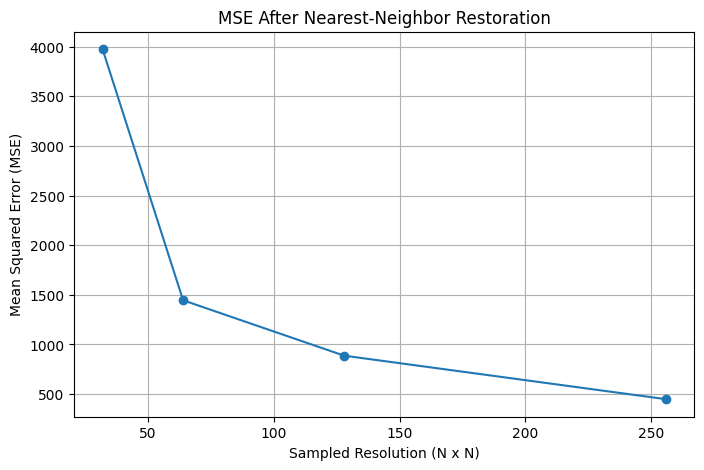

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# ============================================================
# SPATIAL SAMPLING AND RESOLUTION LOSS
# ============================================================


# ------------------------------------------------------------
# 1. Load the original 512x512 source image
# ------------------------------------------------------------

image_path = (DATA_DIR / "sampling_quantization_source.png")

original_image = Image.open(image_path).convert("L")

original = np.array(original_image)


print("===== ORIGINAL IMAGE INFORMATION =====")

print("Original shape:", original.shape)
print("Data type:", original.dtype)
print("Minimum intensity:", original.min())
print("Maximum intensity:", original.max())
print("Total samples:", original.size)


# Verify expected size
if original.shape == (512, 512):
    print("Shape verification: Correct (512 x 512)")
else:
    print(
        "WARNING: The reference image is expected to be a 512x512 image, "
        f"but the loaded image has shape {original.shape}."
    )


# ------------------------------------------------------------
# 2. Define required sampling resolutions
# ------------------------------------------------------------

sampling_sizes = [
    256,
    128,
    64,
    32
]


# Dictionaries will store results
sampled_images = {}
restored_images = {}
sample_percentages = {}
mse_results = {}


# ------------------------------------------------------------
# 3. Spatially sample the original image
# ------------------------------------------------------------

for size in sampling_sizes:

    # Downsample from 512x512 to required resolution
    sampled_pil = original_image.resize(
        (size, size),
        resample=Image.Resampling.NEAREST
    )

    sampled = np.array(sampled_pil)

    sampled_images[size] = sampled


    # Calculate percentage of original samples retained
    original_samples = original.size
    retained_samples = sampled.size

    percentage_retained = (
        retained_samples
        / original_samples
    ) * 100

    sample_percentages[size] = percentage_retained


# ------------------------------------------------------------
# 4. Print sampling information
# ------------------------------------------------------------

print("\n===== SPATIAL SAMPLING RESULTS =====")

for size in sampling_sizes:

    sampled = sampled_images[size]

    print(
        f"\nResolution: {size} x {size}"
    )

    print(
        "Number of retained samples:",
        sampled.size
    )

    print(
        f"Percentage of samples retained: "
        f"{sample_percentages[size]:.4f}%"
    )


# ------------------------------------------------------------
# 5. Display original and sampled images
# at the SAME display size
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    5,
    figsize=(18, 5)
)


# Original
axes[0].imshow(
    original,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

axes[0].set_title(
    "Original\n512 x 512"
)

axes[0].axis("off")


# Sampled images
for ax, size in zip(
    axes[1:],
    sampling_sizes
):

    ax.imshow(
        sampled_images[size],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    ax.set_title(
        f"{size} x {size}\n"
        f"{sample_percentages[size]:.2f}% retained"
    )

    ax.axis("off")


plt.suptitle(
    "Effect of Spatial Sampling",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Restore every sampled image back to 512x512
# using nearest-neighbor interpolation
# ------------------------------------------------------------

for size in sampling_sizes:

    sampled = sampled_images[size]

    # Convert sampled NumPy array back into PIL image
    sampled_pil = Image.fromarray(
        sampled.astype(np.uint8)
    )

    # Restore to original spatial dimensions
    restored_pil = sampled_pil.resize(
        original_image.size,
        resample=Image.Resampling.NEAREST
    )

    restored = np.array(
        restored_pil
    )

    restored_images[size] = restored


# ------------------------------------------------------------
# 7. Calculate MSE between original and restored images
# ------------------------------------------------------------

# MSE:
#
# MSE = (1/N) * Σ (Original - Restored)^2
#
# Convert to float before subtraction to avoid uint8
# arithmetic overflow.

original_float = original.astype(
    np.float64
)


for size in sampling_sizes:

    restored_float = (
        restored_images[size]
        .astype(np.float64)
    )

    mse = np.mean(
        (
            original_float
            - restored_float
        ) ** 2
    )

    mse_results[size] = mse


# ------------------------------------------------------------
# 8. Print MSE results
# ------------------------------------------------------------

print("\n===== RESTORATION MSE RESULTS =====")

for size in sampling_sizes:

    print(
        f"{size} x {size} "
        f"-> restored to 512 x 512 "
        f"-> MSE = {mse_results[size]:.4f}"
    )


# ------------------------------------------------------------
# 9. Display restored images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    5,
    figsize=(18, 5)
)


axes[0].imshow(
    original,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

axes[0].set_title(
    "Original\n512 x 512"
)

axes[0].axis("off")


for ax, size in zip(
    axes[1:],
    sampling_sizes
):

    ax.imshow(
        restored_images[size],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    ax.set_title(
        f"{size} x {size} → 512 x 512\n"
        f"MSE = {mse_results[size]:.2f}"
    )

    ax.axis("off")


plt.suptitle(
    "Nearest-Neighbor Restoration to 512 x 512",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Plot sampling percentage against resolution
# ------------------------------------------------------------

resolutions = np.array(
    sampling_sizes
)

percentages = np.array(
    [
        sample_percentages[size]
        for size in sampling_sizes
    ]
)


plt.figure(figsize=(8, 5))

plt.plot(
    resolutions,
    percentages,
    marker="o"
)

plt.title(
    "Percentage of Spatial Samples Retained"
)

plt.xlabel(
    "Image Resolution (N x N)"
)

plt.ylabel(
    "Samples Retained (%)"
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 11. Plot MSE against sampled resolution
# ------------------------------------------------------------

mse_values = np.array(
    [
        mse_results[size]
        for size in sampling_sizes
    ]
)


plt.figure(figsize=(8, 5))

plt.plot(
    resolutions,
    mse_values,
    marker="o"
)

plt.title(
    "MSE After Nearest-Neighbor Restoration"
)

plt.xlabel(
    "Sampled Resolution (N x N)"
)

plt.ylabel(
    "Mean Squared Error (MSE)"
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 12. Final numerical summary
# ------------------------------------------------------------

print("\n===== analysis 12 FINAL SUMMARY ====")

print(
    f"{'Resolution':<15}"
    f"{'Samples':<15}"
    f"{'Retained (%)':<20}"
    f"{'MSE':<15}"
)

print("-" * 65)


for size in sampling_sizes:

    print(
        f"{size}x{size:<10}"
        f"{sampled_images[size].size:<15}"
        f"{sample_percentages[size]:<20.4f}"
        f"{mse_results[size]:<15.4f}"
    )


### Interpretation
Lower spatial sampling densities remove detail and increase reconstruction error. Upscaling a low-resolution image can enlarge it, but it cannot recreate samples that were never captured. The experiment therefore separates image dimensions from true spatial information content.


## 13. Intensity Quantization and Bit-Depth Analysis

### Introduction
Sampling controls where an image is measured; quantization controls how precisely each measured intensity is represented. Bit depth therefore determines intensity resolution rather than spatial resolution.

### Method
The grayscale source image is quantized to 1, 2, 3, 4, and 8 bits per pixel. The number of available gray levels follows

\[
L=2^k
\]

where \(k\) is the number of bits per pixel. Quantized values are mapped back into the display range \([0,255]\) so all versions can be compared visually.

Histograms reveal how the number of available intensity levels changes with bit depth, while mean squared error measures the deviation from the original 8-bit image. Theoretical raw storage requirements are also calculated for each representation.

The analysis exposes the trade-off between intensity fidelity and storage efficiency: fewer bits reduce storage but increase quantization error and visible banding.


===== ORIGINAL IMAGE INFORMATION ===telek= 
Image shape: (512, 512)
Data type: uint8
Minimum intensity: 20
Maximum intensity: 255
Total pixels: 262144
Shape verification: Correct (512 x 512)

===== QUANTIZATION RESULTS =====
Bits    Gray Levels    MSE               Storage (Bytes)     Storage (KiB)  
----------------------------------------------------------------------------
1       2              2700.5939         32768               32.00          
2       4              567.4212          65536               64.00          
3       8              182.6180          98304               96.00          
4       16             24.0149           131072              128.00         
8       256            0.0000            262144              256.00         

===== UNIQUE INTENSITY LEVELS =====

1-bit (2 possible levels):
[  0 255]
Number of intensity levels actually present: 2

2-bit (4 possible levels):
[  0  85 170 255]
Number of intensity levels actually present: 4

3-bit (8 possible le

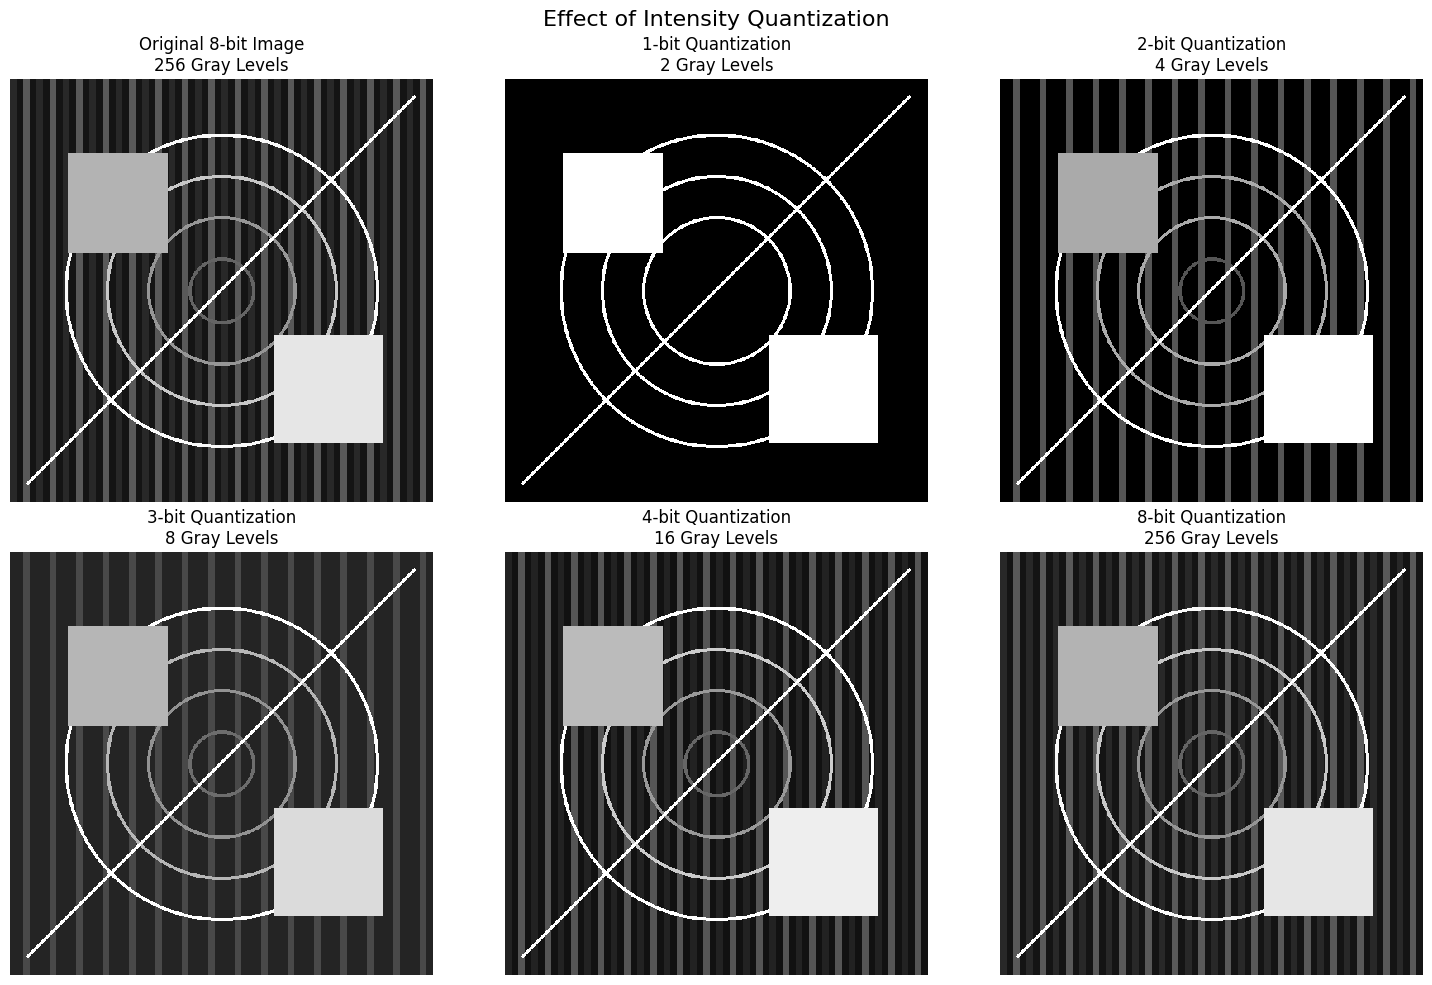

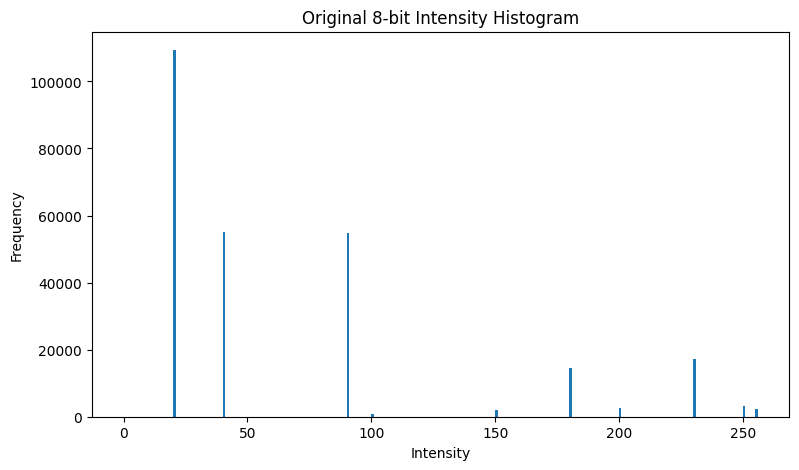

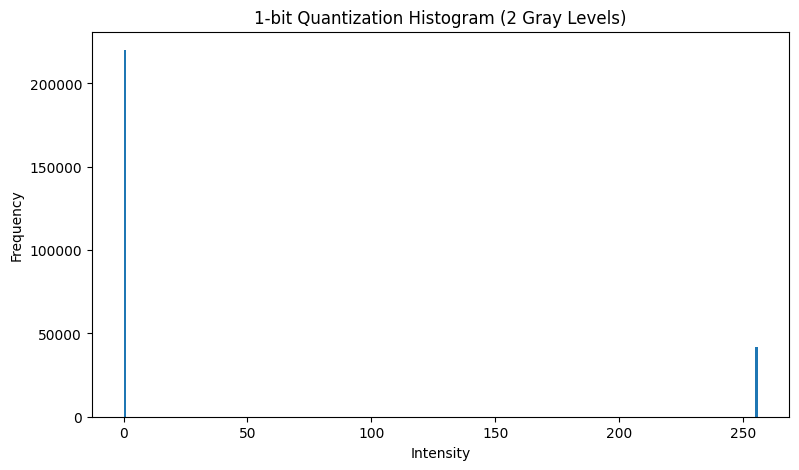

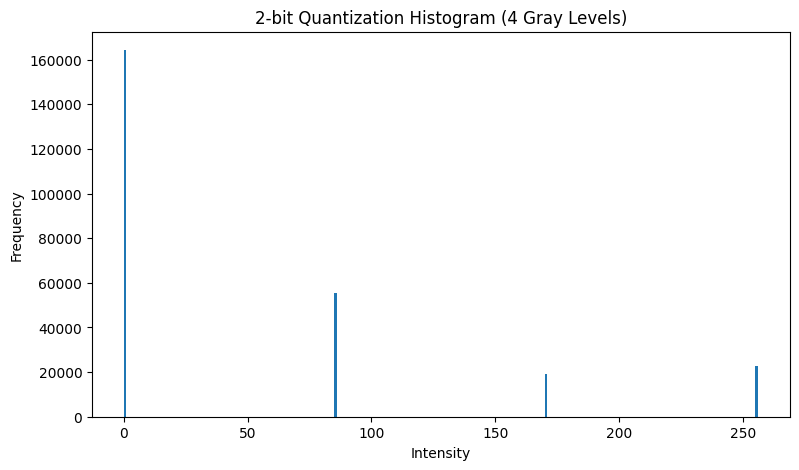

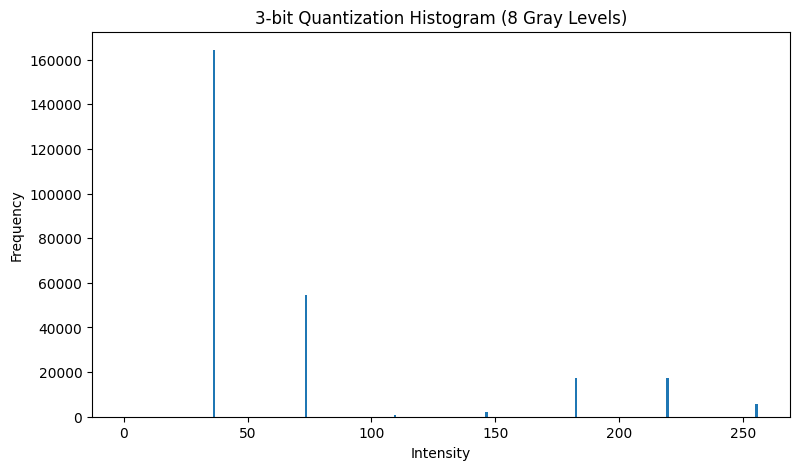

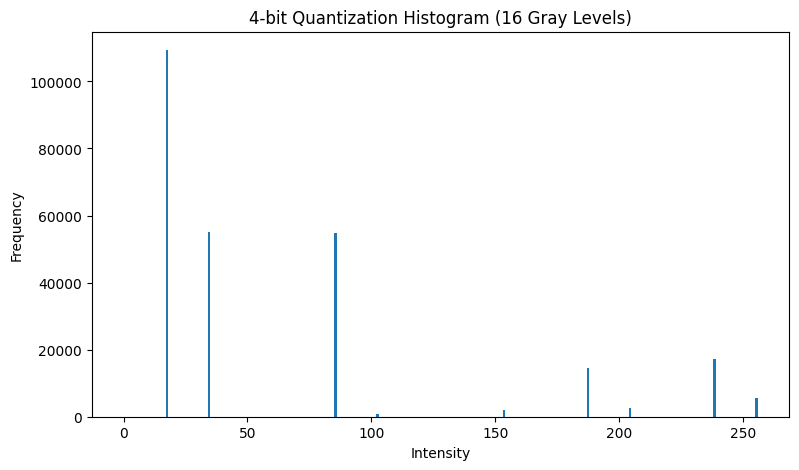

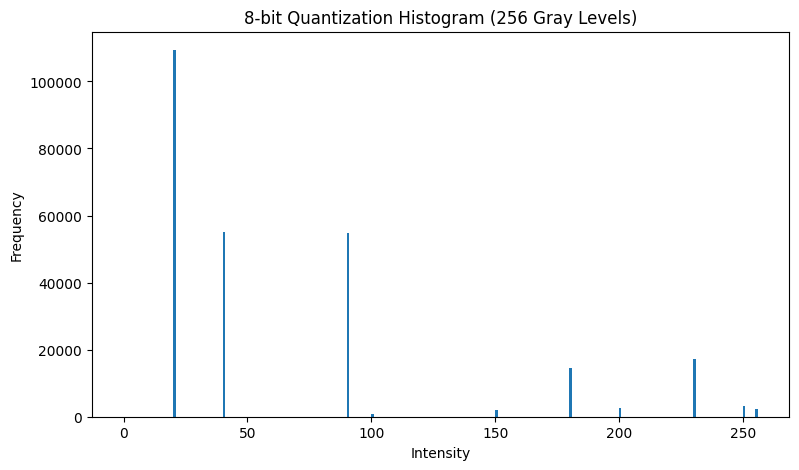

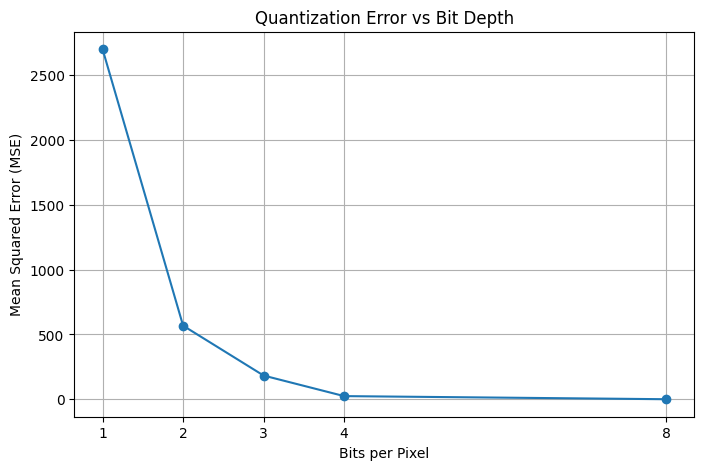

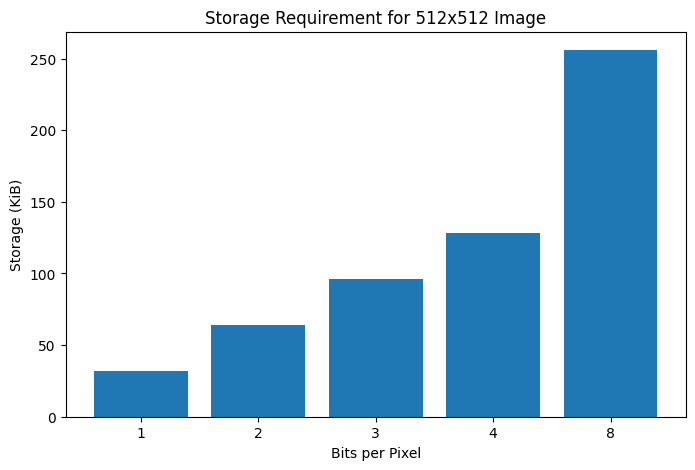

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# ============================================================
# INTENSITY QUANTIZATION AND BIT-DEPTH ANALYSIS
# ============================================================


# ------------------------------------------------------------
# 1. Load the original grayscale image
# ------------------------------------------------------------

image_path = (DATA_DIR / "sampling_quantization_source.png")

original_image = Image.open(
    image_path
).convert("L")

original = np.array(
    original_image,
    dtype=np.uint8
)


print("===== ORIGINAL IMAGE INFORMATION ===telek= ")

print("Image shape:", original.shape)
print("Data type:", original.dtype)
print("Minimum intensity:", original.min())
print("Maximum intensity:", original.max())
print("Total pixels:", original.size)


# Verify expected image dimensions
if original.shape == (512, 512):
    print("Shape verification: Correct (512 x 512)")
else:
    print(
        "WARNING: Reference image is expected to be 512x512, "
        f"but loaded image is {original.shape}"
    )


# ------------------------------------------------------------
# 2. Define required bit depths
# ------------------------------------------------------------

bit_depths = [
    1,
    2,
    3,
    4,
    8
]


quantized_images = {}
gray_levels = {}
mse_results = {}
storage_bytes = {}


# ------------------------------------------------------------
# 3. Quantize image at each bit depth
# ------------------------------------------------------------

for bits in bit_depths:

    # Number of available gray levels
    L = 2 ** bits

    gray_levels[bits] = L


    # --------------------------------------------------------
    # Uniform intensity quantization
    # --------------------------------------------------------
    #
    # Original intensity range = [0, 255]
    #
    # First map 256 original values into L quantization levels.
    # Then map those levels back across [0,255] so that all
    # quantized images can be displayed normally.
    # --------------------------------------------------------

    if L == 256:

        # 8-bit image already contains 256 gray levels
        quantized = original.copy()

    else:

        # Convert to floating point for safe calculations
        original_float = original.astype(
            np.float64
        )

        # Map [0,255] -> [0,L-1]
        level_indices = np.round(
            original_float
            * (L - 1)
            / 255.0
        )

        # Map quantization levels back to display range [0,255]
        quantized = np.round(
            level_indices
            * 255.0
            / (L - 1)
        )

        quantized = np.clip(
            quantized,
            0,
            255
        ).astype(np.uint8)


    quantized_images[bits] = quantized


# ------------------------------------------------------------
# 4. Calculate MSE for every quantized image
# ------------------------------------------------------------

original_float = original.astype(
    np.float64
)


for bits in bit_depths:

    quantized_float = (
        quantized_images[bits]
        .astype(np.float64)
    )

    mse = np.mean(
        (
            original_float
            - quantized_float
        ) ** 2
    )

    mse_results[bits] = mse


# ------------------------------------------------------------
# 5. Calculate storage requirements
# ------------------------------------------------------------

# For an uncompressed grayscale image:
#
# Storage in bits =
# width × height × bits_per_pixel
#
# Storage in bytes =
# total_bits / 8

height, width = original.shape


for bits in bit_depths:

    total_bits = (
        width
        * height
        * bits
    )

    total_bytes = (
        total_bits
        / 8
    )

    storage_bytes[bits] = total_bytes


# ------------------------------------------------------------
# 6. Print numerical results
# ------------------------------------------------------------

print("\n===== QUANTIZATION RESULTS =====")

print(
    f"{'Bits':<8}"
    f"{'Gray Levels':<15}"
    f"{'MSE':<18}"
    f"{'Storage (Bytes)':<20}"
    f"{'Storage (KiB)':<15}"
)

print("-" * 76)


for bits in bit_depths:

    L = gray_levels[bits]

    mse = mse_results[bits]

    bytes_required = storage_bytes[bits]

    kib_required = (
        bytes_required / 1024
    )

    print(
        f"{bits:<8}"
        f"{L:<15}"
        f"{mse:<18.4f}"
        f"{bytes_required:<20.0f}"
        f"{kib_required:<15.2f}"
    )


# ------------------------------------------------------------
# 7. Display original and all quantized images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10)
)

axes = axes.flatten()


# Original image
axes[0].imshow(
    original,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

axes[0].set_title(
    "Original 8-bit Image\n256 Gray Levels"
)

axes[0].axis("off")


# Quantized images
for ax, bits in zip(
    axes[1:],
    bit_depths
):

    L = gray_levels[bits]

    ax.imshow(
        quantized_images[bits],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    ax.set_title(
        f"{bits}-bit Quantization\n"
        f"{L} Gray Levels"
    )

    ax.axis("off")


plt.suptitle(
    "Effect of Intensity Quantization",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Plot histogram of original image
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    original.flatten(),
    bins=256,
    range=(0, 256)
)

plt.title(
    "Original 8-bit Intensity Histogram"
)

plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.show()


# ------------------------------------------------------------
# 9. Plot histogram for each quantized image
# ------------------------------------------------------------

for bits in bit_depths:

    L = gray_levels[bits]

    plt.figure(figsize=(9, 5))

    plt.hist(
        quantized_images[bits].flatten(),
        bins=256,
        range=(0, 256)
    )

    plt.title(
        f"{bits}-bit Quantization Histogram "
        f"({L} Gray Levels)"
    )

    plt.xlabel("Intensity")
    plt.ylabel("Frequency")

    plt.show()


# ------------------------------------------------------------
# 10. Display unique intensity values
# ------------------------------------------------------------

print("\n===== UNIQUE INTENSITY LEVELS =====")

for bits in bit_depths:

    unique_values = np.unique(
        quantized_images[bits]
    )

    print(
        f"\n{bits}-bit "
        f"({gray_levels[bits]} possible levels):"
    )

    print(unique_values)

    print(
        "Number of intensity levels actually present:",
        len(unique_values)
    )


# ------------------------------------------------------------
# 11. Plot MSE versus bit depth
# ------------------------------------------------------------

mse_values = [
    mse_results[bits]
    for bits in bit_depths
]


plt.figure(figsize=(8, 5))

plt.plot(
    bit_depths,
    mse_values,
    marker="o"
)

plt.title(
    "Quantization Error vs Bit Depth"
)

plt.xlabel(
    "Bits per Pixel"
)

plt.ylabel(
    "Mean Squared Error (MSE)"
)

plt.xticks(bit_depths)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 12. Plot storage requirement versus bit depth
# ------------------------------------------------------------

storage_kib = [
    storage_bytes[bits] / 1024
    for bits in bit_depths
]


plt.figure(figsize=(8, 5))

plt.bar(
    [str(bits) for bits in bit_depths],
    storage_kib
)

plt.title(
    "Storage Requirement for 512x512 Image"
)

plt.xlabel(
    "Bits per Pixel"
)

plt.ylabel(
    "Storage (KiB)"
)

plt.show()


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n===== ANALYSIS SUMMARY =====")

for bits in bit_depths:

    print(
        f"{bits}-bit:"
        f" {gray_levels[bits]} gray levels,"
        f" MSE = {mse_results[bits]:.4f},"
        f" Storage = "
        f"{storage_bytes[bits] / 1024:.2f} KiB"
    )


### Interpretation
Lower bit depths reduce the number of available gray levels and increase quantization error, often producing visible banding in smooth regions. Higher bit depths preserve intensity variation more faithfully but require more raw storage. Spatial dimensions remain unchanged throughout this analysis.


## 14. Physical Image Size, DPI, and Storage Requirements

### Introduction
Digital resolution is often described in pixels, while printed or physically displayed images are also constrained by size in inches. DPI connects these two domains by specifying how many image samples occupy each physical inch.

### Method
A fixed 4×3 inch image is evaluated at 72, 150, 300, and 930 DPI. Pixel dimensions are calculated from

\[
\text{pixels}=\text{physical size in inches}\times\text{DPI}
\]

Total pixel count and raw storage are then computed for both 8-bit grayscale and 24-bit RGB data. A synthetic 4:3 pattern is resampled at each resolution to demonstrate that pixel dimensions can change substantially while the physical aspect ratio remains constant.

Because DPI affects both width and height, total pixel count grows approximately with the square of DPI. This has direct consequences for image detail, memory use, transmission, and processing cost.


===== PHYSICAL IMAGE INFORMATION =====
Physical width:  4 inches
Physical height: 3 inches
Aspect ratio: 4:3

===== DPI CALCULATION TABLE =====
 DPI  Width_pixels  Height_pixels  Total_pixels  Grayscale_bytes  RGB_bytes  Grayscale_KiB  Grayscale_MiB      RGB_KiB   RGB_MiB
  72           288            216         62208            62208     186624      60.750000       0.059326   182.250000  0.177979
 150           600            450        270000           270000     810000     263.671875       0.257492   791.015625  0.772476
 300          1200            900       1080000          1080000    3240000    1054.687500       1.029968  3164.062500  3.089905
 930          3720           2790      10378800         10378800   31136400   10135.546875       9.897995 30406.640625 29.693985

===== DETAILED RESULTS =====

--- 72 DPI ---
Pixel dimensions: 288 x 216
Total pixels: 62,208
8-bit grayscale storage: 62,208 bytes (60.75 KiB)
24-bit RGB storage: 186,624 bytes (0.18 MiB)

--- 150 DPI ---
Pixe

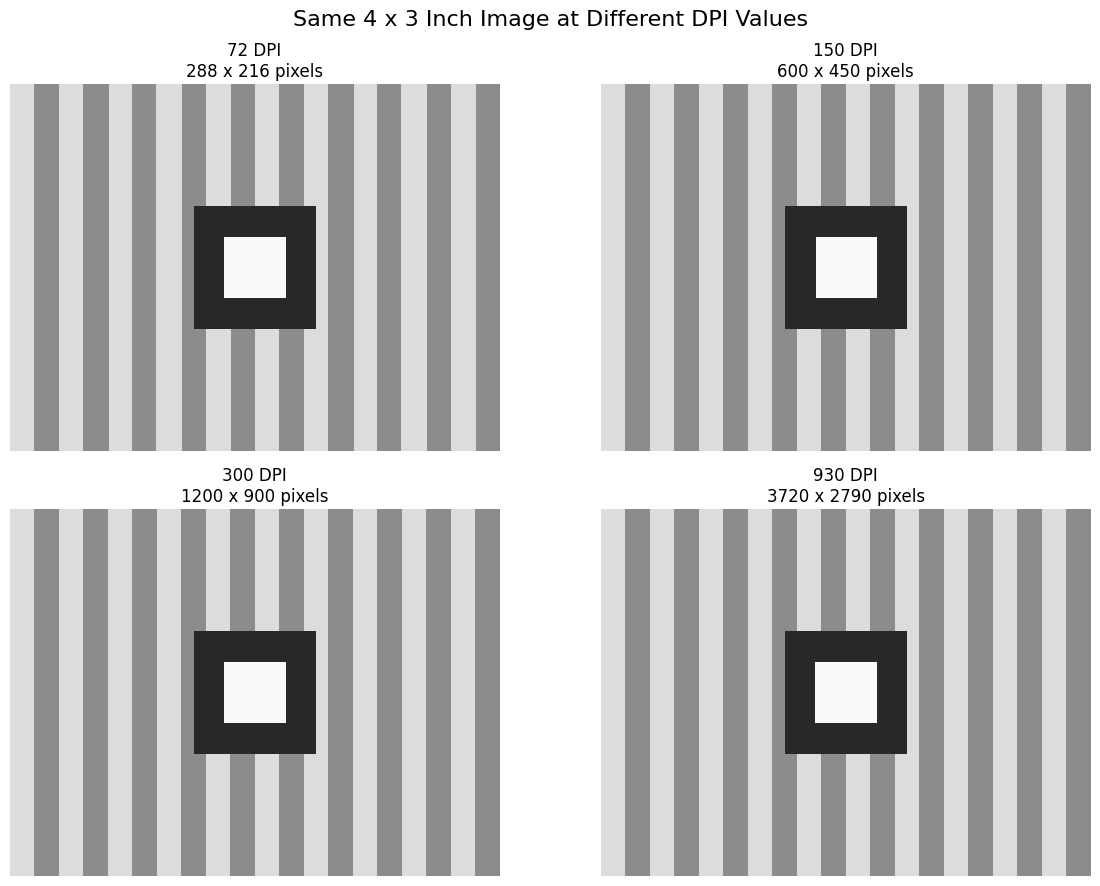

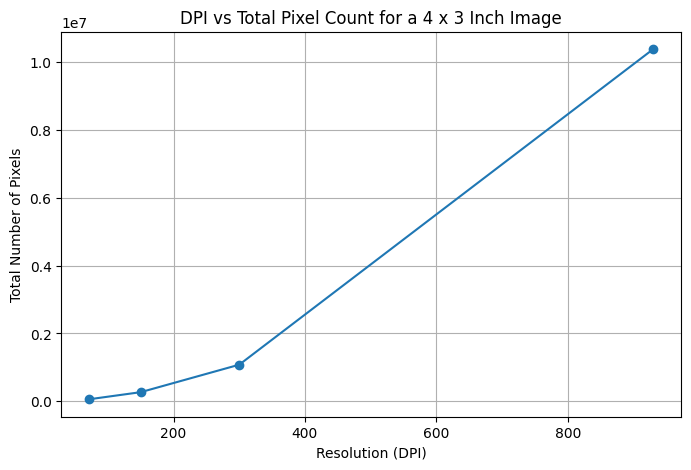

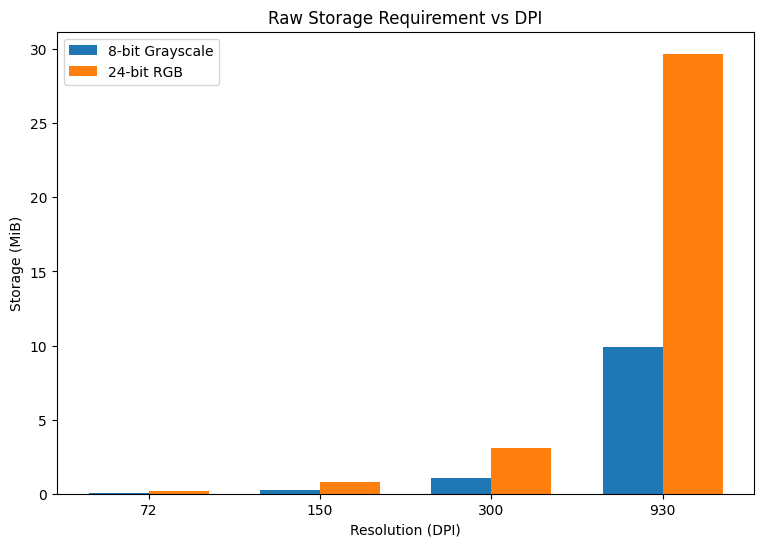

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image


# ============================================================
# PHYSICAL IMAGE SIZE, DPI, AND STORAGE REQUIREMENTS
# ============================================================


# ------------------------------------------------------------
# 1. Define physical dimensions and DPI values
# ------------------------------------------------------------

width_inches = 4
height_inches = 3

dpi_values = [
    72,
    150,
    300,
    930
]


print("===== PHYSICAL IMAGE INFORMATION =====")

print(f"Physical width:  {width_inches} inches")
print(f"Physical height: {height_inches} inches")
print(
    f"Aspect ratio: {width_inches}:{height_inches}"
)


# ------------------------------------------------------------
# 2. Calculate pixel dimensions for each DPI
# ------------------------------------------------------------

results = []


for dpi in dpi_values:

    pixel_width = int(
        width_inches * dpi
    )

    pixel_height = int(
        height_inches * dpi
    )

    total_pixels = (
        pixel_width
        * pixel_height
    )


    # --------------------------------------------------------
    # 8-bit grayscale storage
    # --------------------------------------------------------
    #
    # 8 bits = 1 byte per pixel

    grayscale_bytes = (
        total_pixels * 1
    )


    # --------------------------------------------------------
    # 24-bit RGB storage
    # --------------------------------------------------------
    #
    # 24 bits = 3 bytes per pixel

    rgb_bytes = (
        total_pixels * 3
    )


    results.append({
        "DPI": dpi,
        "Width_pixels": pixel_width,
        "Height_pixels": pixel_height,
        "Total_pixels": total_pixels,
        "Grayscale_bytes": grayscale_bytes,
        "RGB_bytes": rgb_bytes
    })


# ------------------------------------------------------------
# 3. Convert results to DataFrame
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)


# Add KiB and MiB columns

results_df["Grayscale_KiB"] = (
    results_df["Grayscale_bytes"]
    / 1024
)

results_df["Grayscale_MiB"] = (
    results_df["Grayscale_bytes"]
    / (1024 ** 2)
)

results_df["RGB_KiB"] = (
    results_df["RGB_bytes"]
    / 1024
)

results_df["RGB_MiB"] = (
    results_df["RGB_bytes"]
    / (1024 ** 2)
)


print("\n===== DPI CALCULATION TABLE =====")

print(
    results_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 4. Print clean human-readable results
# ------------------------------------------------------------

print("\n===== DETAILED RESULTS =====")


for row in results:

    dpi = row["DPI"]

    print(
        f"\n--- {dpi} DPI ---"
    )

    print(
        f"Pixel dimensions: "
        f"{row['Width_pixels']} x "
        f"{row['Height_pixels']}"
    )

    print(
        f"Total pixels: "
        f"{row['Total_pixels']:,}"
    )

    print(
        f"8-bit grayscale storage: "
        f"{row['Grayscale_bytes']:,} bytes "
        f"({row['Grayscale_bytes'] / 1024:.2f} KiB)"
    )

    print(
        f"24-bit RGB storage: "
        f"{row['RGB_bytes']:,} bytes "
        f"({row['RGB_bytes'] / (1024 ** 2):.2f} MiB)"
    )


# ------------------------------------------------------------
# 5. Calculate pixel-count ratio: 930 DPI vs 72 DPI
# ------------------------------------------------------------

pixels_72 = (
    int(width_inches * 72)
    * int(height_inches * 72)
)

pixels_930 = (
    int(width_inches * 930)
    * int(height_inches * 930)
)


pixel_ratio = (
    pixels_930
    / pixels_72
)


print(
    "\n===== PIXEL COUNT RATIO ====="
)

print(
    f"Pixels at 72 DPI: "
    f"{pixels_72:,}"
)

print(
    f"Pixels at 930 DPI: "
    f"{pixels_930:,}"
)

print(
    f"930 DPI / 72 DPI pixel-count ratio: "
    f"{pixel_ratio:.4f}"
)

print(
    f"The 930 DPI image contains approximately "
    f"{pixel_ratio:.2f} times as many pixels "
    f"as the 72 DPI image."
)


# ------------------------------------------------------------
# 6. Verify ratio mathematically
# ------------------------------------------------------------

theoretical_ratio = (
    930 / 72
) ** 2


print(
    "\nTheoretical squared DPI ratio:",
    theoretical_ratio
)


# ------------------------------------------------------------
# 7. Create a synthetic 4:3 test pattern
# ------------------------------------------------------------

# We create the pattern ourselves so the analysis does not
# depend on an external image file.

base_width = 400
base_height = 300


# Create coordinate grids
x = np.arange(base_width)
y = np.arange(base_height)

X, Y = np.meshgrid(
    x,
    y
)


# Start with a light background
test_pattern = np.full(
    (base_height, base_width),
    220,
    dtype=np.uint8
)


# Add alternating vertical stripes
stripe_width = 20

vertical_pattern = (
    (X // stripe_width) % 2
) * 80

test_pattern = np.clip(
    test_pattern
    - vertical_pattern,
    0,
    255
).astype(np.uint8)


# Add a dark central rectangle
test_pattern[
    100:200,
    150:250
] = 40


# Add a bright inner rectangle
test_pattern[
    125:175,
    175:225
] = 250


test_pattern_pil = Image.fromarray(
    test_pattern
)


# ------------------------------------------------------------
# 8. Resample the 4:3 pattern at each DPI
# ------------------------------------------------------------

resampled_images = {}


for dpi in dpi_values:

    new_width = int(
        width_inches * dpi
    )

    new_height = int(
        height_inches * dpi
    )

    resized = test_pattern_pil.resize(
        (
            new_width,
            new_height
        ),
        resample=Image.Resampling.NEAREST
    )

    resampled_images[dpi] = np.array(
        resized
    )


# ------------------------------------------------------------
# 9. Verify aspect ratio of each resampled image
# ------------------------------------------------------------

print(
    "\n===== RESAMPLED IMAGE SHAPES ====="
)


for dpi in dpi_values:

    image = resampled_images[dpi]

    height, width = image.shape

    aspect_ratio = (
        width / height
    )

    print(
        f"{dpi} DPI: "
        f"{width} x {height} pixels, "
        f"aspect ratio = {aspect_ratio:.4f}"
    )


# ------------------------------------------------------------
# 10. Display all resampled patterns at same visual size
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

axes = axes.flatten()


for ax, dpi in zip(
    axes,
    dpi_values
):

    image = resampled_images[dpi]

    height, width = image.shape

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    ax.set_title(
        f"{dpi} DPI\n"
        f"{width} x {height} pixels"
    )

    ax.axis("off")


plt.suptitle(
    "Same 4 x 3 Inch Image at Different DPI Values",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Plot DPI versus total pixel count
# ------------------------------------------------------------

total_pixel_values = [
    row["Total_pixels"]
    for row in results
]


plt.figure(figsize=(8, 5))

plt.plot(
    dpi_values,
    total_pixel_values,
    marker="o"
)

plt.title(
    "DPI vs Total Pixel Count for a 4 x 3 Inch Image"
)

plt.xlabel(
    "Resolution (DPI)"
)

plt.ylabel(
    "Total Number of Pixels"
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 12. Plot storage requirements
# ------------------------------------------------------------

grayscale_storage_mib = [
    row["Grayscale_bytes"]
    / (1024 ** 2)
    for row in results
]

rgb_storage_mib = [
    row["RGB_bytes"]
    / (1024 ** 2)
    for row in results
]


x_positions = np.arange(
    len(dpi_values)
)

bar_width = 0.35


plt.figure(figsize=(9, 6))

plt.bar(
    x_positions - bar_width / 2,
    grayscale_storage_mib,
    width=bar_width,
    label="8-bit Grayscale"
)

plt.bar(
    x_positions + bar_width / 2,
    rgb_storage_mib,
    width=bar_width,
    label="24-bit RGB"
)

plt.xticks(
    x_positions,
    [str(dpi) for dpi in dpi_values]
)

plt.title(
    "Raw Storage Requirement vs DPI"
)

plt.xlabel(
    "Resolution (DPI)"
)

plt.ylabel(
    "Storage (MiB)"
)

plt.legend()

plt.show()


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print(
    "\n===== ANALYSIS SUMMARY ====="
)


for row in results:

    print(
        f"{row['DPI']} DPI -> "
        f"{row['Width_pixels']} x "
        f"{row['Height_pixels']} pixels, "
        f"{row['Total_pixels']:,} total pixels, "
        f"Grayscale = "
        f"{row['Grayscale_bytes'] / (1024 ** 2):.3f} MiB, "
        f"RGB = "
        f"{row['RGB_bytes'] / (1024 ** 2):.3f} MiB"
    )


print(
    f"\n930 DPI contains "
    f"{pixel_ratio:.2f}x as many pixels "
    f"as 72 DPI for the same physical image size."
)


### Interpretation
For a fixed physical image size, increasing DPI increases both horizontal and vertical pixel counts, so total pixels grow quadratically. RGB data also requires three times the raw pixel storage of 8-bit grayscale at the same dimensions. DPI therefore has a major effect on both potential detail and computational cost.


## 15. Line-Pair Resolution and Sampling Requirements

### Introduction
Spatial resolution can also be expressed using line pairs per millimeter (LP/mm), a common metric for imaging systems. A line pair consists of one bright and one dark line, so narrower lines correspond to higher spatial frequency.

### Method
For an individual line width \(W\), line-pair resolution is calculated as

\[
\text{LP/mm}=\frac{1}{2W}
\]

for widths of 0.50, 0.20, 0.10, and 0.05 mm. Synthetic alternating stripe patterns are generated at 100 pixels/mm to visualize the increasing spatial frequency.

The minimum sampling density is estimated using a conservative requirement of at least two pixels per individual line. Dots per millimeter are then converted to DPI using \(1\text{ inch}=25.4\text{ mm}\).

This connects physical feature size, resolvable spatial frequency, and the digital sampling density required to represent those features.

The theoretical Nyquist boundary is two pixels per line pair: `2 * LP/mm = 1 / W` pixels/mm. This experiment instead uses two pixels per individual line (`2 / W`), or four pixels per pair, as a conservative design assumption. Sampling at the theoretical boundary does not guarantee phase-independent recovery of a square-wave target.


===== LINE-PAIR RESOLUTION RESULTS =====
 Line Width (mm)  Pair Width (mm)  Resolution (LP/mm)  Conservative Pixels/mm  Equivalent DPI
            0.50              1.0                 1.0                     4.0           101.6
            0.20              0.4                 2.5                    10.0           254.0
            0.10              0.2                 5.0                    20.0           508.0
            0.05              0.1                10.0                    40.0          1016.0

===== DETAILED CALCULATIONS =====

Line width = 0.50 mm
Line-pair width = 2 x 0.50 = 1.00 mm
Resolution = 1 / 1.00 = 1.00 LP/mm
Conservative sampling density = 4.00 dots/mm
Equivalent DPI = 101.60 DPI

Line width = 0.20 mm
Line-pair width = 2 x 0.20 = 0.40 mm
Resolution = 1 / 0.40 = 2.50 LP/mm
Conservative sampling density = 10.00 dots/mm
Equivalent DPI = 254.00 DPI

Line width = 0.10 mm
Line-pair width = 2 x 0.10 = 0.20 mm
Resolution = 1 / 0.20 = 5.00 LP/mm
Conservative sampling den

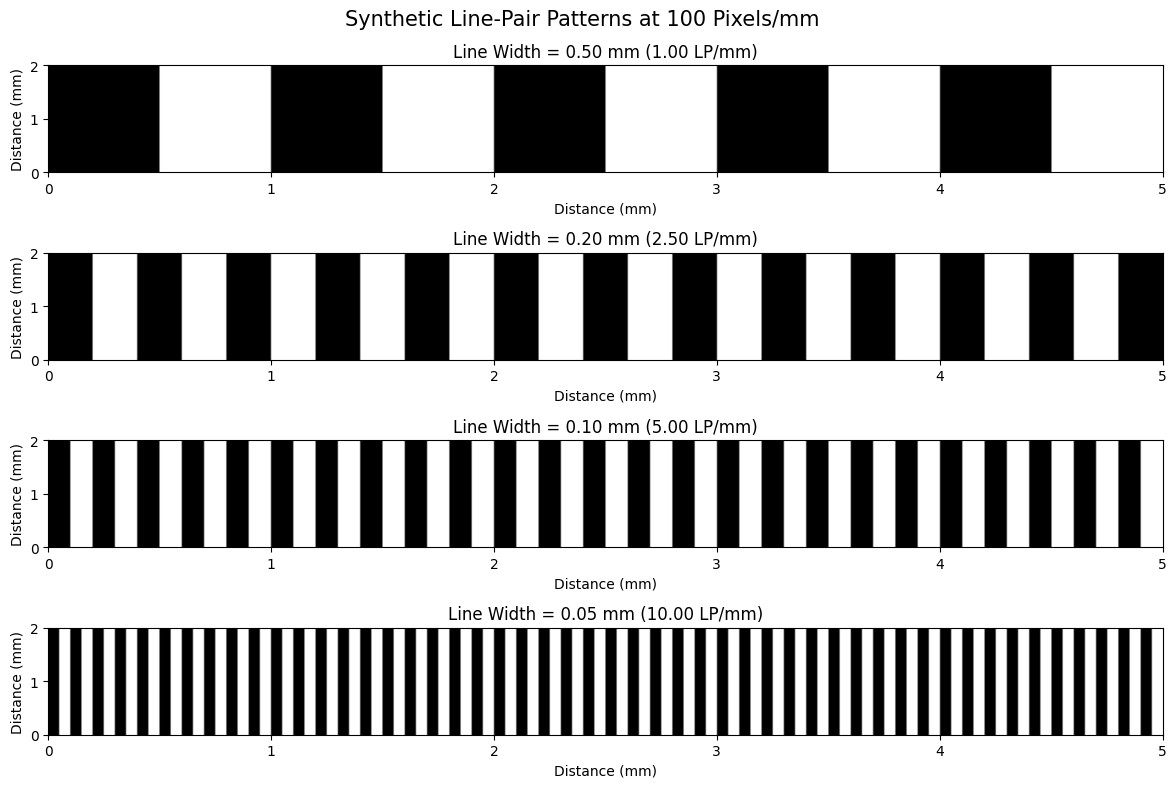

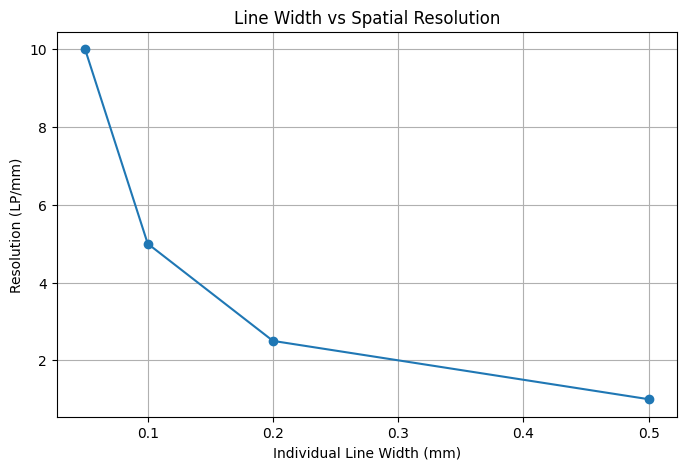

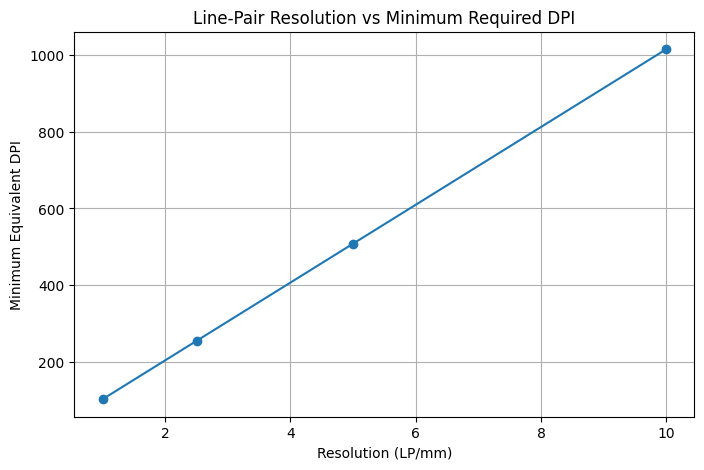

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# LINE-PAIR RESOLUTION AND SAMPLING REQUIREMENTS
# ============================================================


# ------------------------------------------------------------
# 1. Define line widths from the reference specification
# ------------------------------------------------------------

line_widths_mm = np.array([
    0.50,
    0.20,
    0.10,
    0.05
])


# ------------------------------------------------------------
# 2. Calculate line-pair width
# ------------------------------------------------------------

# One line pair consists of:
#
# one dark line + one bright line
#
# If each individual line has width W:
#
# Pair width = 2W

pair_widths_mm = (
    2 * line_widths_mm
)


# ------------------------------------------------------------
# 3. Calculate LP/mm
# ------------------------------------------------------------

# LP/mm = 1 / pair width
#
# Therefore:
#
# LP/mm = 1 / (2W)

lp_per_mm = (
    1 / pair_widths_mm
)


# ------------------------------------------------------------
# 4. Minimum sampling requirement
# ------------------------------------------------------------

# The analysis estimates the minimum dots/mm
# required when EACH INDIVIDUAL LINE must have at
# least 2 pixels.
#
# One individual line has width W.
#
# Required dots/mm:
#
# 2 pixels / W mm

minimum_dots_per_mm = (
    2 / line_widths_mm
)


# ------------------------------------------------------------
# 5. Convert dots/mm to DPI
# ------------------------------------------------------------

# 1 inch = 25.4 mm
#
# dots/inch =
# dots/mm * 25.4

equivalent_dpi = (
    minimum_dots_per_mm
    * 25.4
)


# ------------------------------------------------------------
# 6. Create results table
# ------------------------------------------------------------

results = pd.DataFrame({

    "Line Width (mm)":
        line_widths_mm,

    "Pair Width (mm)":
        pair_widths_mm,

    "Resolution (LP/mm)":
        lp_per_mm,

    "Conservative Pixels/mm":
        minimum_dots_per_mm,

    "Equivalent DPI":
        equivalent_dpi
})


print("===== LINE-PAIR RESOLUTION RESULTS =====")

print(
    results.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 7. Print detailed calculations
# ------------------------------------------------------------

print("\n===== DETAILED CALCULATIONS =====")


for i in range(
    len(line_widths_mm)
):

    W = line_widths_mm[i]
    pair_width = pair_widths_mm[i]
    lpmm = lp_per_mm[i]
    dots_mm = minimum_dots_per_mm[i]
    dpi = equivalent_dpi[i]

    print(
        f"\nLine width = {W:.2f} mm"
    )

    print(
        f"Line-pair width = "
        f"2 x {W:.2f} = "
        f"{pair_width:.2f} mm"
    )

    print(
        f"Resolution = "
        f"1 / {pair_width:.2f} = "
        f"{lpmm:.2f} LP/mm"
    )

    print(
        f"Conservative sampling density = "
        f"{dots_mm:.2f} dots/mm"
    )

    print(
        f"Equivalent DPI = "
        f"{dpi:.2f} DPI"
    )


# ------------------------------------------------------------
# 8. Explicitly verify 0.10 mm -> 5 LP/mm
# ------------------------------------------------------------

W = 0.10

verification_lpmm = (
    1 / (2 * W)
)


print(
    "\n===== 0.10 mm VERIFICATION ====="
)

print(
    "Line width:",
    W,
    "mm"
)

print(
    "Line-pair width:",
    2 * W,
    "mm"
)

print(
    "LP/mm:",
    verification_lpmm
)


if np.isclose(
    verification_lpmm,
    5.0
):

    print(
        "Verification successful: "
        "0.10 mm corresponds to 5 LP/mm."
    )

else:

    print(
        "Verification failed."
    )


# ------------------------------------------------------------
# 9. Generate synthetic stripe patterns
# ------------------------------------------------------------

# Required sampling density:
#
# 100 pixels per millimetre

pixels_per_mm = 100


# Generate a pattern covering 5 mm horizontally
# and 2 mm vertically.

pattern_width_mm = 5
pattern_height_mm = 2


pattern_width_pixels = int(
    pattern_width_mm
    * pixels_per_mm
)

pattern_height_pixels = int(
    pattern_height_mm
    * pixels_per_mm
)


print(
    "\n===== SYNTHETIC PATTERN INFORMATION ====="
)

print(
    "Simulation sampling density:",
    pixels_per_mm,
    "pixels/mm"
)

print(
    "Pattern physical size:",
    pattern_width_mm,
    "mm x",
    pattern_height_mm,
    "mm"
)

print(
    "Pattern pixel dimensions:",
    pattern_width_pixels,
    "x",
    pattern_height_pixels
)


# ------------------------------------------------------------
# 10. Function to generate line-pair pattern
# ------------------------------------------------------------

def create_stripe_pattern(
    line_width_mm,
    pixels_per_mm,
    width_pixels,
    height_pixels
):

    # Convert physical line width into pixels
    line_width_pixels = int(
        round(
            line_width_mm
            * pixels_per_mm
        )
    )

    # Ensure at least one pixel
    line_width_pixels = max(
        1,
        line_width_pixels
    )


    # X coordinates
    x = np.arange(
        width_pixels
    )


    # Alternate between dark and bright lines
    stripe_values = (
        (
            x // line_width_pixels
        ) % 2
    ) * 255


    # Repeat stripe row vertically
    pattern = np.tile(
        stripe_values,
        (
            height_pixels,
            1
        )
    )


    return (
        pattern.astype(np.uint8),
        line_width_pixels
    )


# ------------------------------------------------------------
# 11. Generate all four patterns
# ------------------------------------------------------------

patterns = {}
line_widths_pixels = {}


for W in line_widths_mm:

    pattern, width_pixels = (
        create_stripe_pattern(
            W,
            pixels_per_mm,
            pattern_width_pixels,
            pattern_height_pixels
        )
    )

    patterns[W] = pattern

    line_widths_pixels[W] = (
        width_pixels
    )


# ------------------------------------------------------------
# 12. Print line widths in pixels at 100 pixels/mm
# ------------------------------------------------------------

print(
    "\n===== LINE WIDTHS AT 100 PIXELS/MM ====="
)


for W in line_widths_mm:

    print(
        f"{W:.2f} mm line "
        f"= {line_widths_pixels[W]} pixels"
    )


# ------------------------------------------------------------
# 13. Display synthetic stripe patterns
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    1,
    figsize=(12, 8)
)


for ax, W in zip(
    axes,
    line_widths_mm
):

    pattern = patterns[W]

    lpmm = (
        1 / (2 * W)
    )

    ax.imshow(
        pattern,
        cmap="gray",
        vmin=0,
        vmax=255,
        aspect="auto",
        extent=[
            0,
            pattern_width_mm,
            0,
            pattern_height_mm
        ]
    )

    ax.set_title(
        f"Line Width = {W:.2f} mm "
        f"({lpmm:.2f} LP/mm)"
    )

    ax.set_xlabel(
        "Distance (mm)"
    )

    ax.set_ylabel(
        "Distance (mm)"
    )


plt.suptitle(
    "Synthetic Line-Pair Patterns at 100 Pixels/mm",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Plot line width vs LP/mm
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    line_widths_mm,
    lp_per_mm,
    marker="o"
)

plt.title(
    "Line Width vs Spatial Resolution"
)

plt.xlabel(
    "Individual Line Width (mm)"
)

plt.ylabel(
    "Resolution (LP/mm)"
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 15. Plot LP/mm vs required DPI
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    lp_per_mm,
    equivalent_dpi,
    marker="o"
)

plt.title(
    "Line-Pair Resolution vs Minimum Required DPI"
)

plt.xlabel(
    "Resolution (LP/mm)"
)

plt.ylabel(
    "Minimum Equivalent DPI"
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 16. Final analysis 15 summary
# ------------------------------------------------------------

print(
    "\n===== ANALYSIS SUMMARY ====="
)


for i in range(
    len(line_widths_mm)
):

    print(
        f"Line width "
        f"{line_widths_mm[i]:.2f} mm -> "
        f"{lp_per_mm[i]:.2f} LP/mm, "
        f"minimum "
        f"{minimum_dots_per_mm[i]:.2f} dots/mm, "
        f"equivalent "
        f"{equivalent_dpi[i]:.2f} DPI"
    )


### Interpretation
Narrower lines correspond to higher LP/mm and demand greater sampling density. The calculations connect a physically meaningful resolution target to digital requirements in dots/mm and DPI. LP/mm describes scene or system spatial frequency, while DPI describes digital sampling density; the two should not be treated as interchangeable units.


## Part IV — CCD/CMOS System Modeling

The final part uses simplified numerical models to connect sensor architecture with power consumption, low-light noise, SNR, and selective region-of-interest processing.


## 16. CCD and CMOS Power-Efficiency Modeling

### Introduction
Sensor architecture affects more than image formation; it also influences power demand and system-level energy use. Power consumption becomes especially important in battery-powered cameras, embedded devices, and long-duration imaging systems.

### Method
The supplied reference ranges model CCD consumption at 2–5 W and CMOS consumption at 20–50 mW. CMOS values are converted to watts so both technologies can be compared using consistent units. Minimum, midpoint, and maximum powers are calculated.

Using midpoint values, energy consumption is estimated for one minute, thirty minutes, and two hours with

\[
E=P\times t
\]

A 10 Wh idealized battery is then used to estimate runtime from \(t=E/P\). Separate plots compare power, energy consumption, and runtime.

These values form a simplified numerical model rather than universal hardware specifications; the purpose is to illustrate the relationship between power, energy, operating time, and battery capacity.


===== ORIGINAL POWER VALUES =====
CCD power range: 2.0 W to 5.0 W
CMOS power range: 20.0 mW to 50.0 mW

===== CMOS CONVERSION TO WATTS =====
20.0 mW = 0.020 W
50.0 mW = 0.050 W

===== MINIMUM, MIDPOINT AND MAXIMUM POWER =====
CCD: min = 2.000 W, mid = 3.500 W, max = 5.000 W
CMOS: min = 0.020 W, mid = 0.035 W, max = 0.050 W

===== POWER COMPARISON TABLE =====
Sensor  Minimum Power (W)  Midpoint Power (W)  Maximum Power (W)
   CCD               2.00               3.500               5.00
  CMOS               0.02               0.035               0.05

===== OPERATING TIMES IN HOURS =====
1 minute: 0.016667 hours
30 minutes: 0.500000 hours
2 hours: 2.000000 hours

===== ENERGY CONSUMPTION AT MIDPOINT POWER =====
Operating Time  CCD Energy (Wh)  CMOS Energy (Wh)
      1 minute         0.058333          0.000583
    30 minutes         1.750000          0.017500
       2 hours         7.000000          0.070000

===== DETAILED ENERGY RESULTS =====

Operating time: 1 minute
CCD energy consum

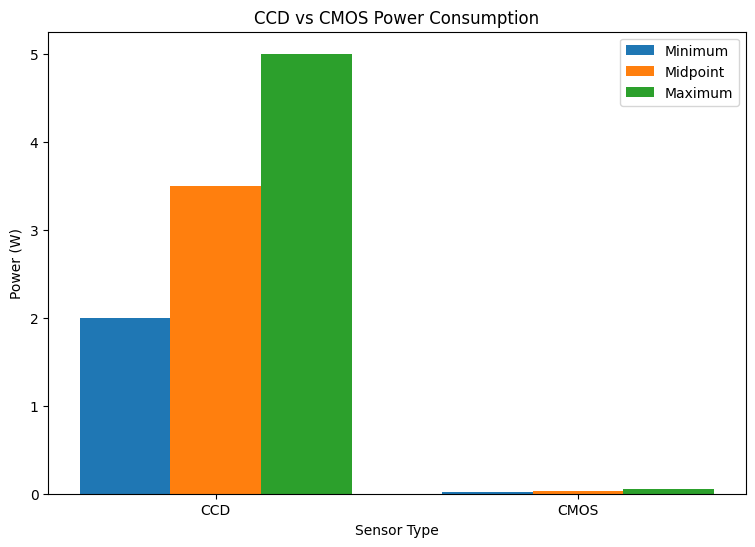

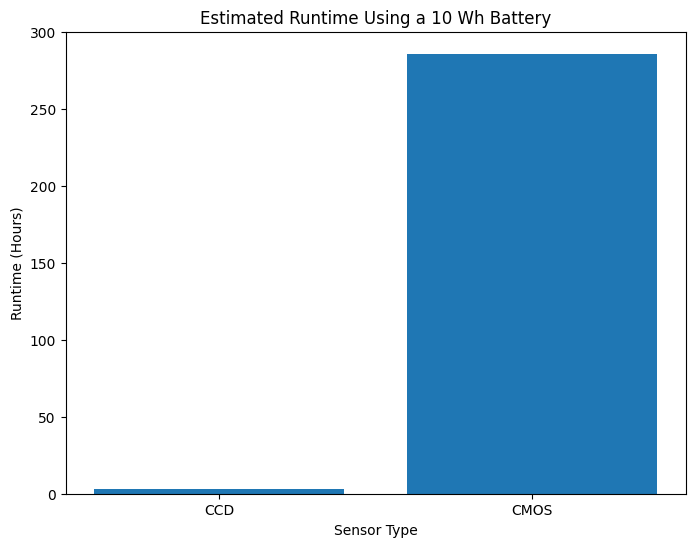

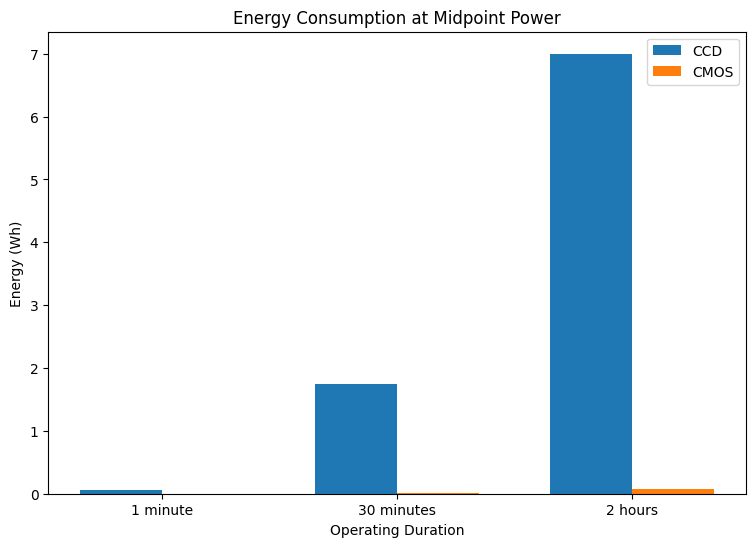

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# CCD AND CMOS POWER-EFFICIENCY MODELING
# ============================================================


# ------------------------------------------------------------
# 1. Power ranges given in the reference specification
# ------------------------------------------------------------

# CCD values are already in watts
ccd_min_w = 2.0
ccd_max_w = 5.0


# CMOS values are given in milliwatts
cmos_min_mw = 20.0
cmos_max_mw = 50.0


print("===== ORIGINAL POWER VALUES =====")

print(
    f"CCD power range: "
    f"{ccd_min_w} W to {ccd_max_w} W"
)

print(
    f"CMOS power range: "
    f"{cmos_min_mw} mW to {cmos_max_mw} mW"
)


# ------------------------------------------------------------
# 2. Convert CMOS milliwatts to watts
# ------------------------------------------------------------

# 1000 mW = 1 W
#
# Therefore:
# W = mW / 1000

cmos_min_w = (
    cmos_min_mw / 1000
)

cmos_max_w = (
    cmos_max_mw / 1000
)


print("\n===== CMOS CONVERSION TO WATTS =====")

print(
    f"{cmos_min_mw} mW = "
    f"{cmos_min_w:.3f} W"
)

print(
    f"{cmos_max_mw} mW = "
    f"{cmos_max_w:.3f} W"
)


# ------------------------------------------------------------
# 3. Calculate midpoint power
# ------------------------------------------------------------

ccd_mid_w = (
    ccd_min_w + ccd_max_w
) / 2


cmos_mid_w = (
    cmos_min_w + cmos_max_w
) / 2


print("\n===== MINIMUM, MIDPOINT AND MAXIMUM POWER =====")

print(
    f"CCD: "
    f"min = {ccd_min_w:.3f} W, "
    f"mid = {ccd_mid_w:.3f} W, "
    f"max = {ccd_max_w:.3f} W"
)

print(
    f"CMOS: "
    f"min = {cmos_min_w:.3f} W, "
    f"mid = {cmos_mid_w:.3f} W, "
    f"max = {cmos_max_w:.3f} W"
)


# ------------------------------------------------------------
# 4. Create power comparison table
# ------------------------------------------------------------

power_table = pd.DataFrame({

    "Sensor": [
        "CCD",
        "CMOS"
    ],

    "Minimum Power (W)": [
        ccd_min_w,
        cmos_min_w
    ],

    "Midpoint Power (W)": [
        ccd_mid_w,
        cmos_mid_w
    ],

    "Maximum Power (W)": [
        ccd_max_w,
        cmos_max_w
    ]
})


print("\n===== POWER COMPARISON TABLE =====")

print(
    power_table.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 5. Define operating times
# ------------------------------------------------------------

# Energy in Wh requires time in HOURS.

times = {
    "1 minute": 1 / 60,
    "30 minutes": 30 / 60,
    "2 hours": 2
}


print("\n===== OPERATING TIMES IN HOURS =====")

for label, hours in times.items():

    print(
        f"{label}: "
        f"{hours:.6f} hours"
    )


# ------------------------------------------------------------
# 6. Calculate energy consumption
# ------------------------------------------------------------

# Formula:
#
# Energy (Wh) = Power (W) × Time (hours)
#
# We calculate energy using the midpoint power.

energy_results = []


for time_label, hours in times.items():

    ccd_energy = (
        ccd_mid_w
        * hours
    )

    cmos_energy = (
        cmos_mid_w
        * hours
    )


    energy_results.append({

        "Operating Time":
            time_label,

        "CCD Energy (Wh)":
            ccd_energy,

        "CMOS Energy (Wh)":
            cmos_energy
    })


energy_table = pd.DataFrame(
    energy_results
)


print("\n===== ENERGY CONSUMPTION AT MIDPOINT POWER =====")

print(
    energy_table.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 7. Print detailed energy calculations
# ------------------------------------------------------------

print("\n===== DETAILED ENERGY RESULTS =====")


for result in energy_results:

    print(
        f"\nOperating time: "
        f"{result['Operating Time']}"
    )

    print(
        f"CCD energy consumption: "
        f"{result['CCD Energy (Wh)']:.6f} Wh"
    )

    print(
        f"CMOS energy consumption: "
        f"{result['CMOS Energy (Wh)']:.6f} Wh"
    )


# ------------------------------------------------------------
# 8. Calculate runtime using a 10 Wh battery
# ------------------------------------------------------------

battery_capacity_wh = 10.0


# Formula:
#
# Runtime (hours) =
# Battery capacity (Wh) / Power (W)

ccd_runtime_hours = (
    battery_capacity_wh
    / ccd_mid_w
)

cmos_runtime_hours = (
    battery_capacity_wh
    / cmos_mid_w
)


print("\n===== 10 Wh BATTERY RUNTIME =====")

print(
    f"CCD runtime at midpoint power: "
    f"{ccd_runtime_hours:.2f} hours"
)

print(
    f"CMOS runtime at midpoint power: "
    f"{cmos_runtime_hours:.2f} hours"
)


# Convert to minutes as well

ccd_runtime_minutes = (
    ccd_runtime_hours * 60
)

cmos_runtime_minutes = (
    cmos_runtime_hours * 60
)


print(
    f"\nCCD runtime: "
    f"{ccd_runtime_minutes:.2f} minutes"
)

print(
    f"CMOS runtime: "
    f"{cmos_runtime_minutes:.2f} minutes"
)


# ------------------------------------------------------------
# 9. Compare midpoint power
# ------------------------------------------------------------

power_ratio = (
    ccd_mid_w
    / cmos_mid_w
)


print("\n===== MIDPOINT POWER COMPARISON =====")

print(
    f"CCD midpoint power / CMOS midpoint power "
    f"= {power_ratio:.2f}"
)

print(
    f"Using the supplied reference values, "
    f"CCD midpoint power is approximately "
    f"{power_ratio:.2f} times the CMOS midpoint power."
)


# ------------------------------------------------------------
# 10. Plot minimum, midpoint and maximum power
# ------------------------------------------------------------

sensor_names = [
    "CCD",
    "CMOS"
]

minimum_power = [
    ccd_min_w,
    cmos_min_w
]

midpoint_power = [
    ccd_mid_w,
    cmos_mid_w
]

maximum_power = [
    ccd_max_w,
    cmos_max_w
]


x = np.arange(
    len(sensor_names)
)

width = 0.25


plt.figure(
    figsize=(9, 6)
)

plt.bar(
    x - width,
    minimum_power,
    width,
    label="Minimum"
)

plt.bar(
    x,
    midpoint_power,
    width,
    label="Midpoint"
)

plt.bar(
    x + width,
    maximum_power,
    width,
    label="Maximum"
)

plt.xticks(
    x,
    sensor_names
)

plt.title(
    "CCD vs CMOS Power Consumption"
)

plt.xlabel(
    "Sensor Type"
)

plt.ylabel(
    "Power (W)"
)

plt.legend()

plt.show()


# ------------------------------------------------------------
# 11. Plot battery runtime separately
# ------------------------------------------------------------

runtime_values = [
    ccd_runtime_hours,
    cmos_runtime_hours
]


plt.figure(
    figsize=(8, 6)
)

plt.bar(
    sensor_names,
    runtime_values
)

plt.title(
    "Estimated Runtime Using a 10 Wh Battery"
)

plt.xlabel(
    "Sensor Type"
)

plt.ylabel(
    "Runtime (Hours)"
)

plt.show()


# ------------------------------------------------------------
# 12. Plot energy consumption over different durations
# ------------------------------------------------------------

time_labels = list(
    times.keys()
)

ccd_energy_values = [
    result["CCD Energy (Wh)"]
    for result in energy_results
]

cmos_energy_values = [
    result["CMOS Energy (Wh)"]
    for result in energy_results
]


x = np.arange(
    len(time_labels)
)

width = 0.35


plt.figure(
    figsize=(9, 6)
)

plt.bar(
    x - width / 2,
    ccd_energy_values,
    width,
    label="CCD"
)

plt.bar(
    x + width / 2,
    cmos_energy_values,
    width,
    label="CMOS"
)

plt.xticks(
    x,
    time_labels
)

plt.title(
    "Energy Consumption at Midpoint Power"
)

plt.xlabel(
    "Operating Duration"
)

plt.ylabel(
    "Energy (Wh)"
)

plt.legend()

plt.show()


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n===== ANALYSIS SUMMARY =====")

print(
    f"CCD power range: "
    f"{ccd_min_w:.3f} - "
    f"{ccd_max_w:.3f} W"
)

print(
    f"CCD midpoint power: "
    f"{ccd_mid_w:.3f} W"
)

print(
    f"CMOS power range: "
    f"{cmos_min_w:.3f} - "
    f"{cmos_max_w:.3f} W"
)

print(
    f"CMOS midpoint power: "
    f"{cmos_mid_w:.3f} W"
)

print(
    f"\n10 Wh battery runtime:"
)

print(
    f"CCD = "
    f"{ccd_runtime_hours:.2f} hours"
)

print(
    f"CMOS = "
    f"{cmos_runtime_hours:.2f} hours"
)

print(
    f"\nMidpoint power ratio "
    f"(CCD / CMOS) = "
    f"{power_ratio:.2f}"
)


### Interpretation
Within this simplified reference model, the CMOS values are far lower than the CCD values, resulting in lower modeled energy consumption and longer idealized battery runtime. The broader lesson is that even modest differences in sensor power can become significant when multiplied over long operating periods.


## 17. CCD/CMOS Low-Light Noise and ROI Processing

### Introduction
Low-light image quality is strongly influenced by sensor noise, while readout architecture affects how much data must be processed. This final analysis combines both ideas in a simplified CCD/CMOS simulation.

### Method
The project loads `ccd_cmos_lowlight_scene.png` and reads simulation parameters from `ccd_cmos_parameters.csv`. CCD noise is modeled as zero-mean Gaussian noise with \(\sigma=3\) gray levels. CMOS noise uses \(\sigma=8\) together with a small deterministic row/column fixed-pattern component. Both simulated images are clipped to the valid 8-bit range.

Signal-to-noise ratio is calculated as

\[
\text{SNR}=\frac{\text{mean(signal)}}{\text{standard deviation(noise)}}
\]

The readout analysis compares a 4000×4000 full frame with a central 1000×1000 region of interest (ROI), then measures the processing time of the full image and the ROI using the same numerical workload.

This demonstrates how noise assumptions affect image quality and how selective readout can reduce computational cost when only part of a frame is needed.

This benchmark computes NumPy mean and standard deviation on an already loaded full frame and a cropped view. It measures CPU processing, not camera acquisition or hardware readout. SNR is a linear mean-signal/noise-standard-deviation ratio calculated from the injected noise before clipping.


===== PARAMETER FILE =====
             parameter        CCD     CMOS                unit_or_note
             power_low        2.0       20              CCD W; CMOS mW
            power_high        5.0       50              CCD W; CMOS mW
simulation_noise_sigma        3.0        8 gray levels; lab assumption
     full_frame_pixels 16000000.0 16000000                      pixels
            ROI_pixels        NaN  1000000  CMOS selective ROI example

===== PARAMETERS USED =====
CCD Gaussian noise sigma: 3.0 gray levels
CMOS Gaussian noise sigma: 8.0 gray levels
Full-frame pixels: 16,000,000
ROI pixels: 1,000,000

===== ORIGINAL IMAGE =====
Shape: (256, 256)
Minimum intensity: 8.0
Maximum intensity: 255.0
Mean intensity: 15.484893798828125

===== SNR RESULTS =====
Mean signal intensity: 15.4849
CCD noise standard deviation: 3.0085
CMOS total noise standard deviation: 8.3402
CCD SNR: 5.1470
CMOS SNR: 1.8567

===== FULL FRAME VS ROI =====
Full frame dimensions: 4000 x 4000
Full-frame pixel

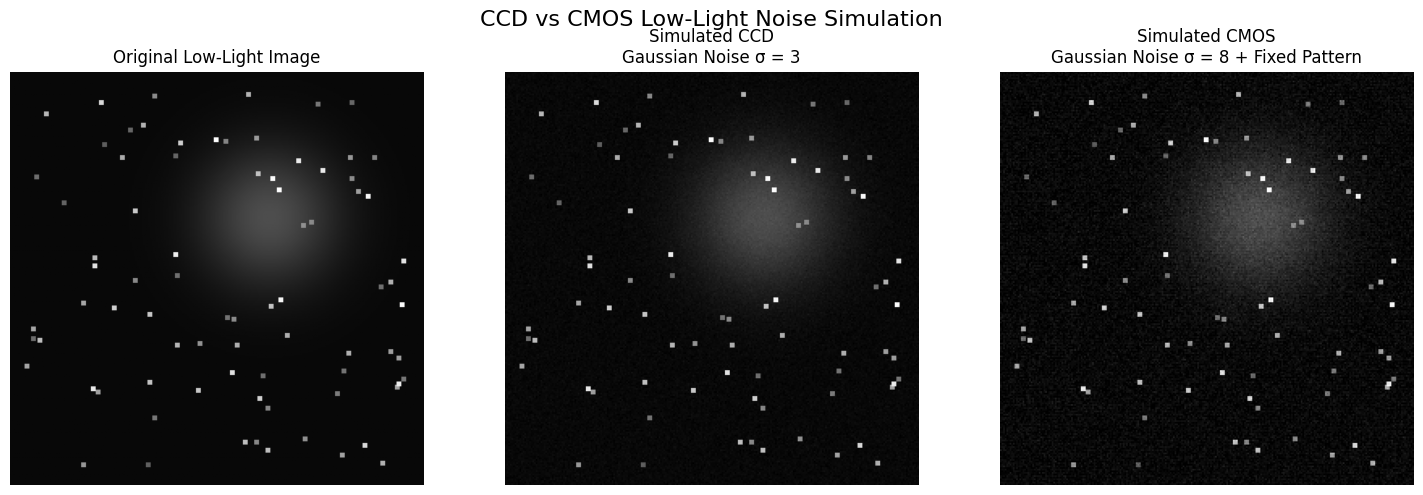

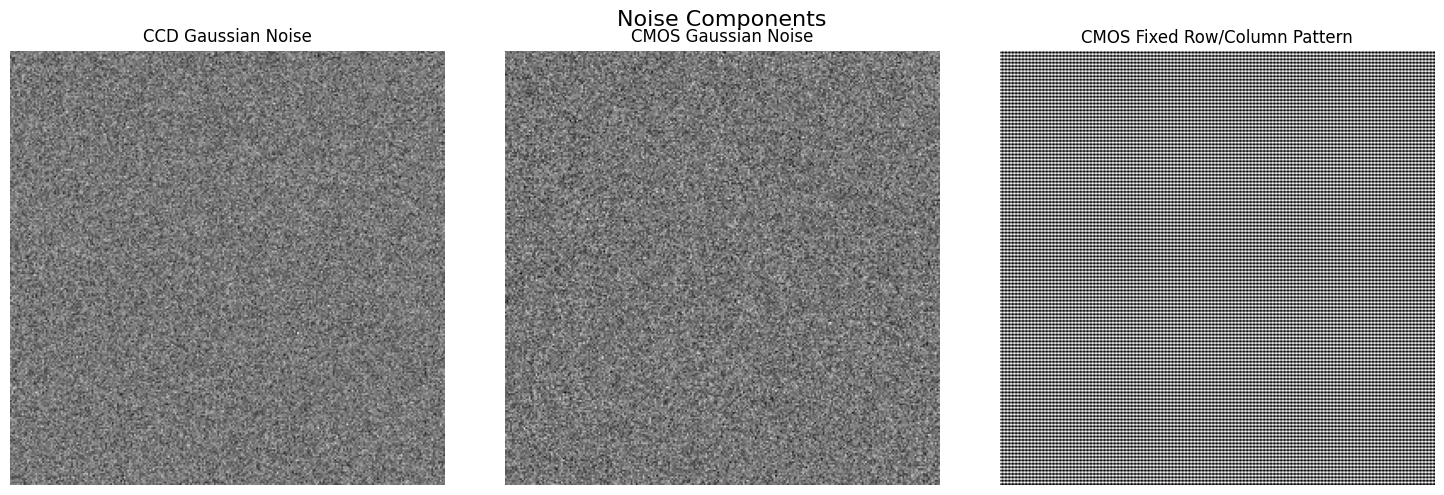

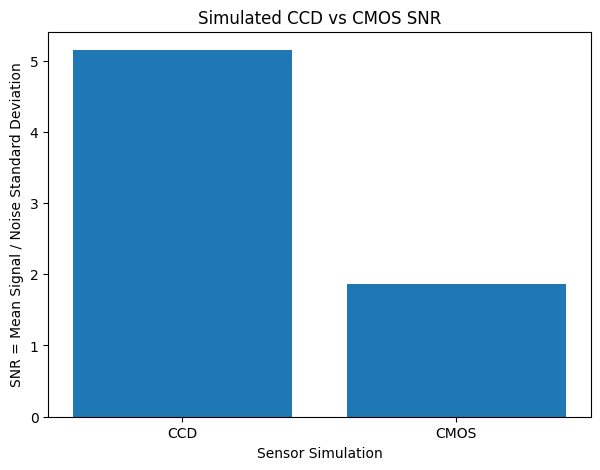

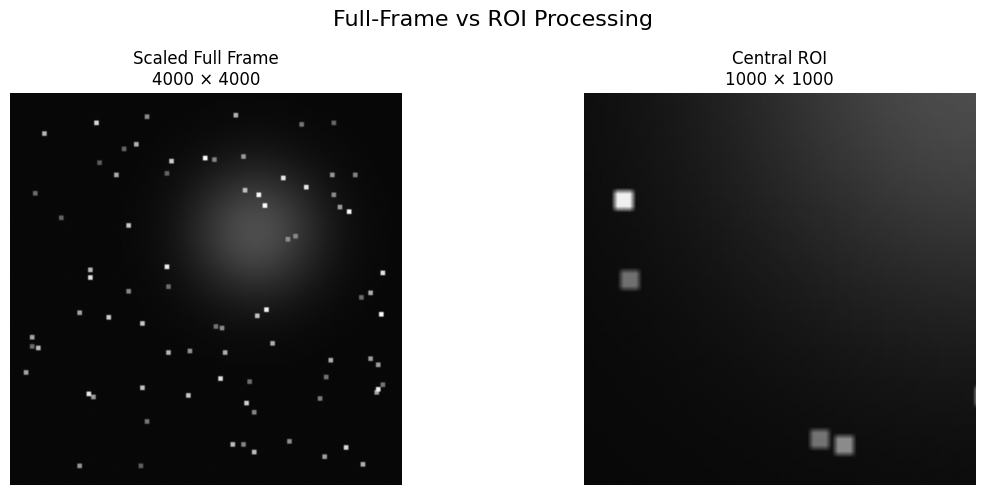

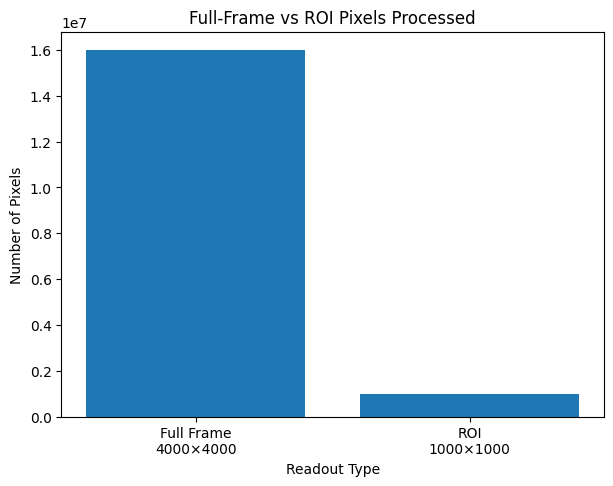

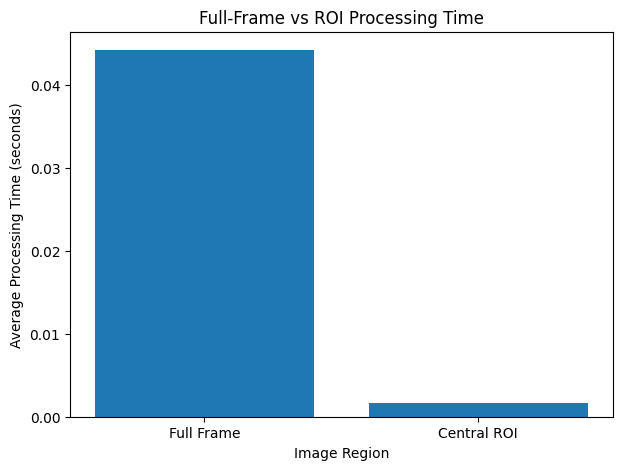

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import time


# ============================================================
# CCD/CMOS LOW-LIGHT NOISE AND SELECTIVE ROI READOUT
# CCD VS CMOS - SIMPLIFIED NOISE AND SELECTIVE READOUT
# ============================================================


# ------------------------------------------------------------
# 1. File paths
# ------------------------------------------------------------

image_path = (DATA_DIR / "ccd_cmos_lowlight_scene.png")
csv_path = (DATA_DIR / "ccd_cmos_parameters.csv")


# ------------------------------------------------------------
# 2. Load parameter CSV
# ------------------------------------------------------------

parameters = pd.read_csv(csv_path)


print("===== PARAMETER FILE =====")

print(parameters.to_string(index=False))


# ------------------------------------------------------------
# 3. Extract required parameters from CSV
# ------------------------------------------------------------

def get_parameter(name, sensor):
    value = parameters.loc[
        parameters["parameter"] == name,
        sensor
    ].iloc[0]

    return value


ccd_sigma = float(
    get_parameter(
        "simulation_noise_sigma",
        "CCD"
    )
)

cmos_sigma = float(
    get_parameter(
        "simulation_noise_sigma",
        "CMOS"
    )
)

full_frame_pixels = int(
    get_parameter(
        "full_frame_pixels",
        "CMOS"
    )
)

roi_pixels = int(
    get_parameter(
        "ROI_pixels",
        "CMOS"
    )
)


print("\n===== PARAMETERS USED =====")

print(
    f"CCD Gaussian noise sigma: "
    f"{ccd_sigma} gray levels"
)

print(
    f"CMOS Gaussian noise sigma: "
    f"{cmos_sigma} gray levels"
)

print(
    f"Full-frame pixels: "
    f"{full_frame_pixels:,}"
)

print(
    f"ROI pixels: "
    f"{roi_pixels:,}"
)


# ------------------------------------------------------------
# 4. Load low-light image as grayscale
# ------------------------------------------------------------

original_pil = Image.open(
    image_path
).convert("L")

original = np.array(
    original_pil,
    dtype=np.float64
)


print("\n===== ORIGINAL IMAGE =====")

print("Shape:", original.shape)
print("Minimum intensity:", original.min())
print("Maximum intensity:", original.max())
print("Mean intensity:", original.mean())


# ------------------------------------------------------------
# 5. Set random seed for reproducibility
# ------------------------------------------------------------

# This ensures that running the notebook again produces
# the same simulated noise pattern.

rng = np.random.default_rng(
    seed=42
)


# ------------------------------------------------------------
# 6. Simulate CCD Gaussian noise
# ------------------------------------------------------------

# CCD:
#
# zero-mean Gaussian noise
# sigma = 3 gray levels

ccd_noise = rng.normal(
    loc=0.0,
    scale=ccd_sigma,
    size=original.shape
)


ccd_simulated_unclipped = (
    original
    + ccd_noise
)


# Clip image to valid 8-bit intensity range

ccd_simulated = np.clip(
    ccd_simulated_unclipped,
    0,
    255
)


# ------------------------------------------------------------
# 7. Simulate CMOS Gaussian noise
# ------------------------------------------------------------

# CMOS:
#
# zero-mean Gaussian noise
# sigma = 8 gray levels
#
# plus a small fixed-pattern row/column offset.

cmos_random_noise = rng.normal(
    loc=0.0,
    scale=cmos_sigma,
    size=original.shape
)


height, width = original.shape


# ------------------------------------------------------------
# 8. Create small fixed row offsets
# ------------------------------------------------------------

# Alternating +/- 2 gray levels across rows.
# This is deterministic fixed-pattern noise.

row_offsets = np.where(
    np.arange(height) % 2 == 0,
    2.0,
    -2.0
).reshape(
    height,
    1
)


# ------------------------------------------------------------
# 9. Create small fixed column offsets
# ------------------------------------------------------------

# Alternating +/- 1 gray level across columns.

column_offsets = np.where(
    np.arange(width) % 2 == 0,
    1.0,
    -1.0
).reshape(
    1,
    width
)


# Combined fixed-pattern offset

fixed_pattern_offset = (
    row_offsets
    + column_offsets
)


# Total CMOS noise contains:
#
# random Gaussian noise
# +
# fixed row/column pattern

cmos_total_noise = (
    cmos_random_noise
    + fixed_pattern_offset
)


cmos_simulated_unclipped = (
    original
    + cmos_total_noise
)


# Clip to valid range

cmos_simulated = np.clip(
    cmos_simulated_unclipped,
    0,
    255
)


# ------------------------------------------------------------
# 10. Convert simulated images to uint8
# ------------------------------------------------------------

ccd_display = np.rint(
    ccd_simulated
).astype(np.uint8)

cmos_display = np.rint(
    cmos_simulated
).astype(np.uint8)

original_display = np.rint(
    original
).astype(np.uint8)


# ------------------------------------------------------------
# 11. Display original, CCD and CMOS images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axes[0].imshow(
    original_display,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[0].set_title(
    "Original Low-Light Image"
)

axes[0].axis("off")


axes[1].imshow(
    ccd_display,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[1].set_title(
    f"Simulated CCD\nGaussian Noise σ = {ccd_sigma:g}"
)

axes[1].axis("off")


axes[2].imshow(
    cmos_display,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[2].set_title(
    f"Simulated CMOS\nGaussian Noise σ = {cmos_sigma:g} + Fixed Pattern"
)

axes[2].axis("off")


plt.suptitle(
    "CCD vs CMOS Low-Light Noise Simulation",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Display noise patterns separately
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axes[0].imshow(
    ccd_noise,
    cmap="gray"
)

axes[0].set_title(
    "CCD Gaussian Noise"
)

axes[0].axis("off")


axes[1].imshow(
    cmos_random_noise,
    cmap="gray"
)

axes[1].set_title(
    "CMOS Gaussian Noise"
)

axes[1].axis("off")


axes[2].imshow(
    fixed_pattern_offset,
    cmap="gray"
)

axes[2].set_title(
    "CMOS Fixed Row/Column Pattern"
)

axes[2].axis("off")


plt.suptitle(
    "Noise Components",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Calculate SNR
# ------------------------------------------------------------

# Required formula:
#
# SNR = mean(signal) / standard deviation(noise)
#
# The original low-light image is treated as the signal.

mean_signal = np.mean(
    original
)


# CCD noise standard deviation
ccd_noise_std = np.std(
    ccd_noise
)


# CMOS total noise includes Gaussian + fixed pattern
cmos_noise_std = np.std(
    cmos_total_noise
)


ccd_snr = (
    mean_signal
    / ccd_noise_std
)


cmos_snr = (
    mean_signal
    / cmos_noise_std
)


print("\n===== SNR RESULTS =====")

print(
    f"Mean signal intensity: "
    f"{mean_signal:.4f}"
)

print(
    f"CCD noise standard deviation: "
    f"{ccd_noise_std:.4f}"
)

print(
    f"CMOS total noise standard deviation: "
    f"{cmos_noise_std:.4f}"
)

print(
    f"CCD SNR: "
    f"{ccd_snr:.4f}"
)

print(
    f"CMOS SNR: "
    f"{cmos_snr:.4f}"
)


# ------------------------------------------------------------
# 14. Compare SNR graphically
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    ["CCD", "CMOS"],
    [ccd_snr, cmos_snr]
)

plt.title(
    "Simulated CCD vs CMOS SNR"
)

plt.xlabel(
    "Sensor Simulation"
)

plt.ylabel(
    "SNR = Mean Signal / Noise Standard Deviation"
)

plt.show()


# ------------------------------------------------------------
# 15. Full-frame vs ROI pixel calculations
# ------------------------------------------------------------

# Given:
#
# Full frame = 4000 x 4000
# ROI        = 1000 x 1000

full_width = 4000
full_height = 4000

roi_width = 1000
roi_height = 1000


calculated_full_pixels = (
    full_width
    * full_height
)

calculated_roi_pixels = (
    roi_width
    * roi_height
)


# Percentage of pixels retained

roi_percentage = (
    calculated_roi_pixels
    / calculated_full_pixels
) * 100


# Percentage reduction

percentage_reduction = (
    (
        calculated_full_pixels
        - calculated_roi_pixels
    )
    / calculated_full_pixels
) * 100


print(
    "\n===== FULL FRAME VS ROI ====="
)

print(
    f"Full frame dimensions: "
    f"{full_width} x {full_height}"
)

print(
    f"Full-frame pixels: "
    f"{calculated_full_pixels:,}"
)

print(
    f"\nROI dimensions: "
    f"{roi_width} x {roi_height}"
)

print(
    f"ROI pixels: "
    f"{calculated_roi_pixels:,}"
)

print(
    f"\nROI contains "
    f"{roi_percentage:.2f}% "
    f"of full-frame pixels."
)

print(
    f"Pixel-count reduction: "
    f"{percentage_reduction:.2f}%"
)


# ------------------------------------------------------------
# 16. Verify against CSV
# ------------------------------------------------------------

print(
    "\n===== CSV VERIFICATION ====="
)

print(
    "Calculated full-frame pixels match CSV:",
    calculated_full_pixels
    == full_frame_pixels
)

print(
    "Calculated ROI pixels match CSV:",
    calculated_roi_pixels
    == roi_pixels
)


# ------------------------------------------------------------
# 17. Create scaled 4000 x 4000 test image
# ------------------------------------------------------------

# The provided image may not actually be 4000x4000.
# Therefore, create the full-frame equivalent by scaling it.

scaled_full_pil = original_pil.resize(
    (
        full_width,
        full_height
    ),
    resample=Image.Resampling.BILINEAR
)


scaled_full = np.array(
    scaled_full_pil,
    dtype=np.float64
)


print(
    "\n===== SCALED TEST IMAGE ====="
)

print(
    "Scaled full-frame shape:",
    scaled_full.shape
)


# ------------------------------------------------------------
# 18. Extract central 1000 x 1000 ROI
# ------------------------------------------------------------

center_y = (
    full_height // 2
)

center_x = (
    full_width // 2
)


half_roi_height = (
    roi_height // 2
)

half_roi_width = (
    roi_width // 2
)


start_y = (
    center_y
    - half_roi_height
)

end_y = (
    start_y
    + roi_height
)


start_x = (
    center_x
    - half_roi_width
)

end_x = (
    start_x
    + roi_width
)


central_roi = scaled_full[
    start_y:end_y,
    start_x:end_x
]


print(
    "Central ROI shape:",
    central_roi.shape
)

print(
    f"ROI coordinates:"
    f" rows {start_y}:{end_y},"
    f" columns {start_x}:{end_x}"
)


# ------------------------------------------------------------
# 19. Display full frame and central ROI
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


axes[0].imshow(
    scaled_full,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[0].set_title(
    "Scaled Full Frame\n4000 × 4000"
)

axes[0].axis("off")


axes[1].imshow(
    central_roi,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[1].set_title(
    "Central ROI\n1000 × 1000"
)

axes[1].axis("off")


plt.suptitle(
    "Full-Frame vs ROI Processing",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 20. Define simple processing operation
# ------------------------------------------------------------

# We use the same operation on both arrays.
# Mean + standard deviation gives us a simple
# reproducible image-processing workload.

def process_image(image):

    mean_value = np.mean(
        image
    )

    std_value = np.std(
        image
    )

    return (
        mean_value,
        std_value
    )


# ------------------------------------------------------------
# 21. Time processing repeatedly for better measurement
# ------------------------------------------------------------

# One timing measurement can fluctuate because of the computer,
# operating system and Python overhead.
#
# Repeating the operation gives a more stable comparison.

repetitions = 20


# Time full-frame processing

start_time = time.perf_counter()

for _ in range(repetitions):

    full_result = process_image(
        scaled_full
    )

full_elapsed = (
    time.perf_counter()
    - start_time
)

full_average_time = (
    full_elapsed
    / repetitions
)


# Time ROI processing

start_time = time.perf_counter()

for _ in range(repetitions):

    roi_result = process_image(
        central_roi
    )

roi_elapsed = (
    time.perf_counter()
    - start_time
)

roi_average_time = (
    roi_elapsed
    / repetitions
)


print(
    "\n===== PROCESSING TIME COMPARISON ====="
)

print(
    f"Repetitions: "
    f"{repetitions}"
)

print(
    f"Average full-frame processing time: "
    f"{full_average_time:.6f} seconds"
)

print(
    f"Average ROI processing time: "
    f"{roi_average_time:.6f} seconds"
)


# ------------------------------------------------------------
# 22. Calculate measured processing speed ratio
# ------------------------------------------------------------

if roi_average_time > 0:

    processing_ratio = (
        full_average_time
        / roi_average_time
    )

    print(
        f"Measured full-frame / ROI "
        f"processing-time ratio: "
        f"{processing_ratio:.2f}x"
    )

else:

    processing_ratio = np.nan

    print(
        "ROI processing time was too small "
        "to calculate a reliable ratio."
    )


# ------------------------------------------------------------
# 23. Plot full-frame vs ROI pixel count
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    [
        "Full Frame\n4000×4000",
        "ROI\n1000×1000"
    ],
    [
        calculated_full_pixels,
        calculated_roi_pixels
    ]
)

plt.title(
    "Full-Frame vs ROI Pixels Processed"
)

plt.ylabel(
    "Number of Pixels"
)

plt.xlabel(
    "Readout Type"
)

plt.show()


# ------------------------------------------------------------
# 24. Plot processing-time comparison
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    [
        "Full Frame",
        "Central ROI"
    ],
    [
        full_average_time,
        roi_average_time
    ]
)

plt.title(
    "Full-Frame vs ROI Processing Time"
)

plt.ylabel(
    "Average Processing Time (seconds)"
)

plt.xlabel(
    "Image Region"
)

plt.show()


# ------------------------------------------------------------
# 25. Final summary
# ------------------------------------------------------------

print(
    "\n===== ANALYSIS SUMMARY ====="
)

print(
    f"CCD noise sigma: "
    f"{ccd_sigma:g} gray levels"
)

print(
    f"CMOS noise sigma: "
    f"{cmos_sigma:g} gray levels"
)

print(
    f"CCD simulated SNR: "
    f"{ccd_snr:.4f}"
)

print(
    f"CMOS simulated SNR: "
    f"{cmos_snr:.4f}"
)

print(
    f"Full-frame pixels: "
    f"{calculated_full_pixels:,}"
)

print(
    f"ROI pixels: "
    f"{calculated_roi_pixels:,}"
)

print(
    f"Pixel-count reduction using ROI: "
    f"{percentage_reduction:.2f}%"
)

print(
    f"Average full-frame processing time: "
    f"{full_average_time:.6f} seconds"
)

print(
    f"Average ROI processing time: "
    f"{roi_average_time:.6f} seconds"
)

if not np.isnan(processing_ratio):

    print(
        f"Measured processing-time ratio: "
        f"{processing_ratio:.2f}x"
    )


### Interpretation
Under the selected simulation parameters, the lower CCD noise standard deviation produces a higher modeled SNR than the CMOS case. The 1000×1000 ROI contains only 6.25% of the pixels in a 4000×4000 frame, corresponding to a 93.75% reduction in pixels processed. Actual timing varies by hardware and software, but the ROI demonstrates the computational value of selective processing.


# Project Conclusion

This project connects the physical origin of image signals with the way those signals are sampled, quantized, stored, visualized, and processed computationally. The electromagnetic analyses establish the inverse relationships among wavelength, frequency, and photon energy, while the flux and brightness sections show that physical measurements and visual perception are not identical. Sensor-reconstruction examples then demonstrate how spatial images can emerge from single-element streams, line sensors, 2D arrays, and stacked volumetric slices.

The sampling and quantization experiments separate two fundamental forms of discretization: spatial sampling controls **where** measurements are taken, whereas quantization controls **how precisely** their amplitudes are represented. DPI, line-pair resolution, and storage calculations extend those ideas into practical imaging-system design.

Finally, the simplified CCD/CMOS models connect image processing with system constraints. Power consumption affects energy and battery runtime, while low-light noise influences SNR. Selective ROI processing demonstrates that reducing the number of pixels processed can also reduce computational workload substantially. Together, the analyses provide an end-to-end view of digital imaging—from electromagnetic energy to sensor data and efficient numerical processing.
